In [ ]:
# ============================================================
# 1. MONTAR O GOOGLE DRIVE
# ============================================================
from google.colab import drive

# Importa o módulo os, que permite ao Python interagir com o sistema de arquivos.
# Neste projeto, será usado para verificar se o arquivo CSV existe no caminho informado.
import os

# Pandas é a principal biblioteca para leitura, limpeza e manipulação da base tabular.
import pandas as pd

#código simples para verificar se o arquivo será encontrado por todos no grupo
drive.mount("/content/drive")

banco_dados = '/content/drive/MyDrive/DataScienceFIAP/application_record.csv'

if os.path.exists(banco_dados):
    print("Arquivo encontrado. Continuando...")

    df = pd.read_csv(banco_dados)

    print("Base carregada com sucesso.")
    print("Dimensão:", df.shape)

else:
    print("ERRO: arquivo não encontrado.")
    print("Verifique se o caminho está correto:")
    print(banco_dados)


# ============================================================
# 2. IMPORTAR AS BIBLIOTECAS PRINCIPAIS
# ============================================================

# Path facilita a criação e manipulação de caminhos de arquivos de forma segura.
from pathlib import Path

# warnings permite controlar mensagens de aviso durante os experimentos.
import warnings

# NumPy oferece estruturas e operações numéricas usadas por várias bibliotecas.
import numpy as np

# Matplotlib é a biblioteca base para criação de gráficos.
import matplotlib.pyplot as plt

# Seaborn facilita gráficos estatísticos e exploratórios.
import seaborn as sns

# SimpleImputer permite preencher valores ausentes dentro do pipeline,
# evitando fazer o tratamento manualmente de forma inconsistente.
from sklearn.impute import SimpleImputer

# train_test_split separa dados de treinamento e teste.
from sklearn.model_selection import train_test_split

# StratifiedKFold será útil posteriormente para validação cruzada mantendo
# aproximadamente a mesma proporção de bons e maus pagadores em cada divisão.
from sklearn.model_selection import StratifiedKFold

# cross_validate permite avaliar um modelo em várias divisões da base.
from sklearn.model_selection import cross_validate

# StandardScaler padroniza variáveis numéricas para modelos sensíveis à escala.
from sklearn.preprocessing import StandardScaler

# OneHotEncoder transforma variáveis categóricas em representação numérica.
from sklearn.preprocessing import OneHotEncoder

# ColumnTransformer permite aplicar tratamentos diferentes em colunas numéricas
# e categóricas dentro de um único fluxo.
from sklearn.compose import ColumnTransformer

# Pipeline encadeia pré-processamento e modelo, reduzindo risco de vazamento de dados.
from sklearn.pipeline import Pipeline

# DummyClassifier cria um modelo de referência extremamente simples.
# Ele é importante para saber se os modelos reais são de fato melhores que um baseline.
from sklearn.dummy import DummyClassifier

# Regressão logística: bom modelo inicial por ser simples e interpretável.
from sklearn.linear_model import LogisticRegression

# Árvore de decisão: modelo não linear e fácil de explicar visualmente.
from sklearn.tree import DecisionTreeClassifier

# Random Forest: conjunto de árvores, normalmente mais robusto que uma árvore isolada.
from sklearn.ensemble import RandomForestClassifier

# Métricas de classificação que serão utilizadas na avaliação dos modelos.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Joblib permite salvar o pipeline/modelo treinado para uso posterior.
import joblib


# ============================================================
# 3. VERIFICAÇÕES INICIAIS DA BASE
# ============================================================

# Exibe a quantidade de linhas e colunas.
print("Dimensão da base:", df.shape)

# Mostra as primeiras cinco linhas para uma inspeção visual.
display(df.head())

# Mostra os nomes das colunas.
print("\nColunas:")
print(df.columns.tolist())

# Mostra tipos das variáveis, quantidade de valores não nulos e uso aproximado de memória.
print("\nInformações gerais:")
df.info(memory_usage="deep")

# ============================================================
# 4. PRESERVAR UMA REFERÊNCIA DOS DADOS ORIGINAIS
# ============================================================

# Cria uma cópia da base carregada antes de iniciar transformações exploratórias.
# Isso é útil para conferência durante o desenvolvimento.
df_original = df.copy()


# ============================================================
# 5. PADRONIZAR NOMES DAS COLUNAS
# ============================================================

# Remove espaços no início e no fim, converte nomes para minúsculas e troca
# espaços internos por sublinhado. Isso reduz erros de digitação no código.
df.columns = (
    df.columns
      .astype(str)
      .str.strip()
      .str.lower()
      .str.replace(" ", "_", regex=False)
)

# Mostra os nomes após a padronização.
print("\nColunas padronizadas:")
print(df.columns.tolist())


# ============================================================
# 6. DIAGNÓSTICO DE QUALIDADE DOS DADOS
# ============================================================

# Conta quantos registros completamente duplicados existem.
duplicados = df.duplicated().sum()

# Exibe a quantidade encontrada.
print(f"\nRegistros duplicados: {duplicados}")

# Conta valores ausentes em cada coluna.
nulos = df.isna().sum()

# Calcula o percentual de valores ausentes em cada coluna.
percentual_nulos = (df.isna().mean() * 100).round(2)

# Junta quantidade e percentual em uma única tabela.
resumo_nulos = pd.DataFrame({
    "quantidade_nulos": nulos,
    "percentual_nulos": percentual_nulos
})

# Ordena as colunas começando pelas que têm maior percentual de ausência.
resumo_nulos = resumo_nulos.sort_values(
    "percentual_nulos",
    ascending=False
)

# Exibe apenas colunas que possuem pelo menos um valor ausente.
display(resumo_nulos[resumo_nulos["quantidade_nulos"] > 0])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo encontrado. Continuando...
Base carregada com sucesso.
Dimensão: (438557, 18)
Dimensão da base: (438557, 18)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0



Colunas:
['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS']

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-nu

,quantidade_nulos,percentual_nulos
occupation_type,134203,30.6


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Linhas: 438,557 | Colunas: 18


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0



Diagnóstico das colunas:


,tipo,ausentes,ausentes_%,valores_distintos
ID,int64,0,0.0,438510
CODE_GENDER,object,0,0.0,2
FLAG_OWN_CAR,object,0,0.0,2
FLAG_OWN_REALTY,object,0,0.0,2
CNT_CHILDREN,int64,0,0.0,12
AMT_INCOME_TOTAL,float64,0,0.0,866
NAME_INCOME_TYPE,object,0,0.0,5
NAME_EDUCATION_TYPE,object,0,0.0,5
NAME_FAMILY_STATUS,object,0,0.0,5
NAME_HOUSING_TYPE,object,0,0.0,6


Linhas completamente duplicadas: 0
IDs repetidos: 47
Registros com DAYS_EMPLOYED = 365243: 75329

Colunas constantes removidas: ['FLAG_MOBIL']


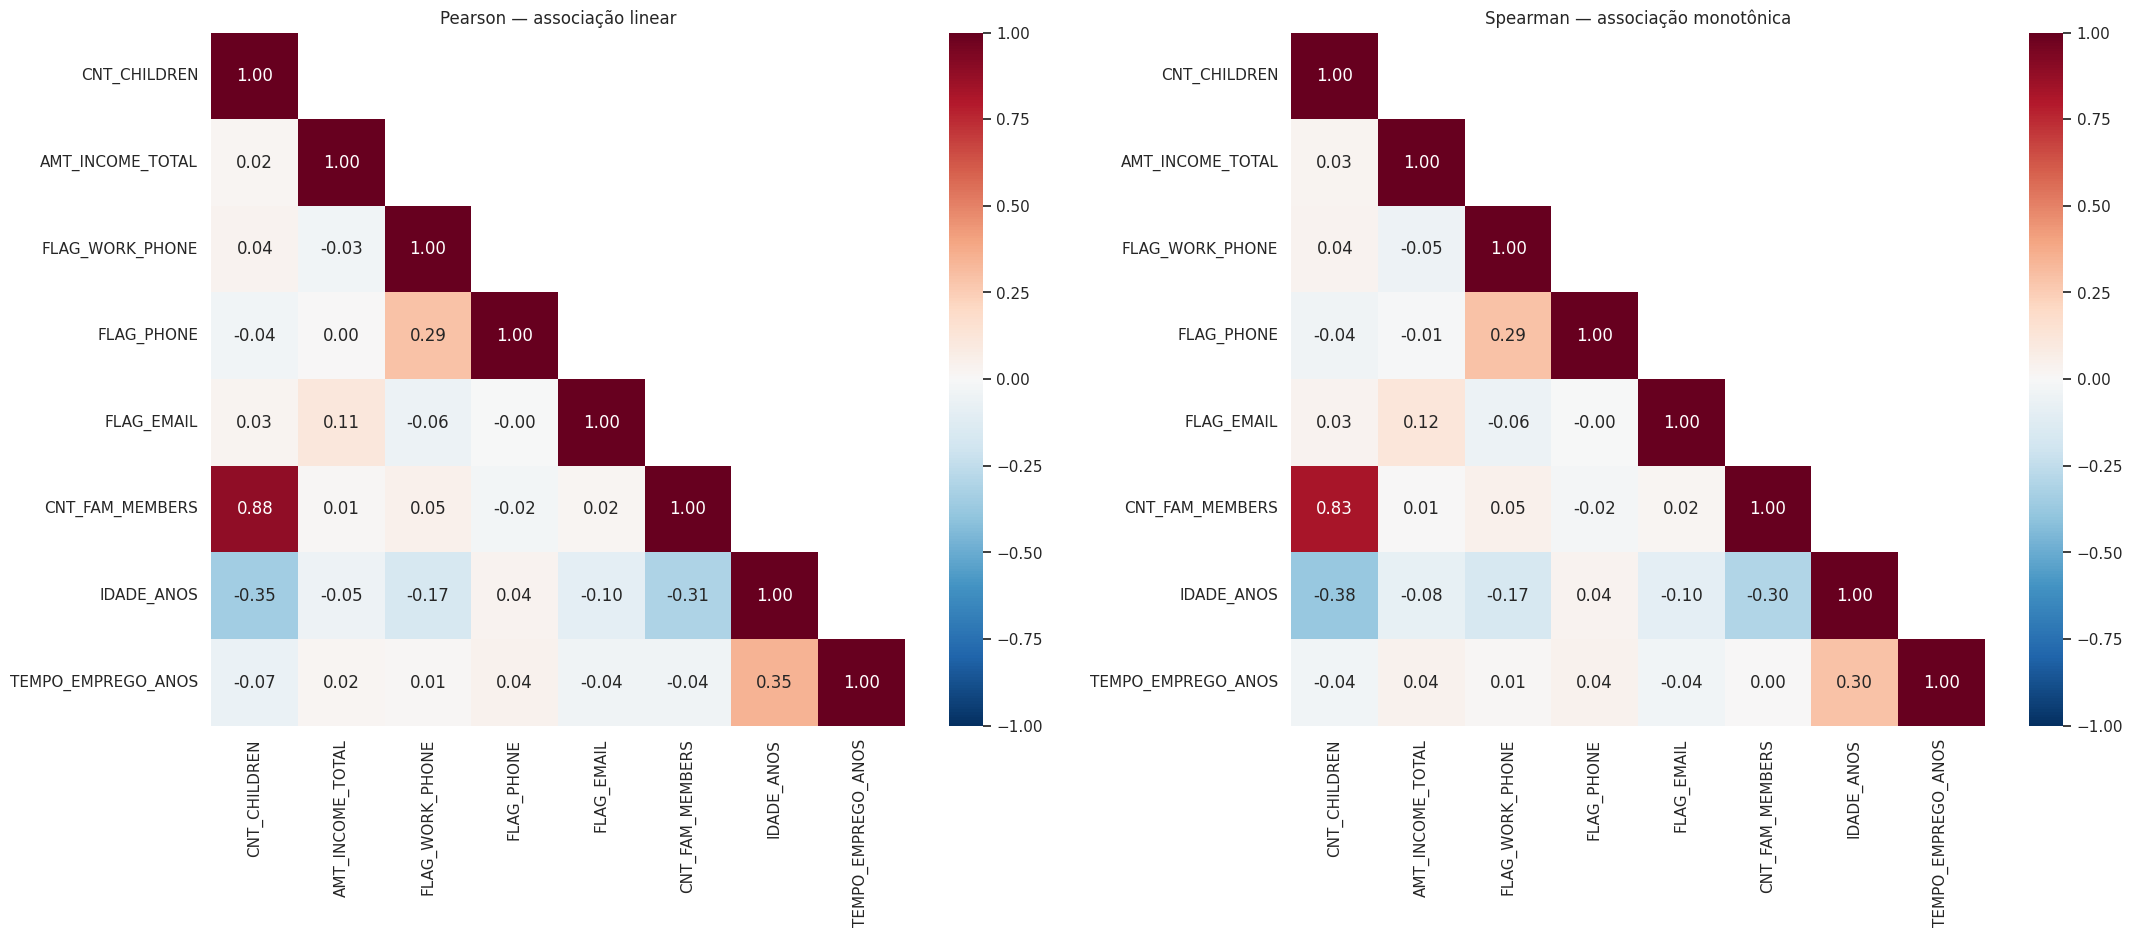


Maiores correlações numéricas — Pearson:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.885,0.885
5,CNT_CHILDREN,IDADE_ANOS,-0.349,0.349
27,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.348,0.348
25,CNT_FAM_MEMBERS,IDADE_ANOS,-0.306,0.306
13,FLAG_WORK_PHONE,FLAG_PHONE,0.290,0.290
16,FLAG_WORK_PHONE,IDADE_ANOS,-0.172,0.172
9,AMT_INCOME_TOTAL,FLAG_EMAIL,0.112,0.112
23,FLAG_EMAIL,IDADE_ANOS,-0.097,0.097
6,CNT_CHILDREN,TEMPO_EMPREGO_ANOS,-0.070,0.070
14,FLAG_WORK_PHONE,FLAG_EMAIL,-0.061,0.061



Maiores correlações numéricas — Spearman:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.826,0.826
5,CNT_CHILDREN,IDADE_ANOS,-0.382,0.382
25,CNT_FAM_MEMBERS,IDADE_ANOS,-0.304,0.304
27,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.296,0.296
13,FLAG_WORK_PHONE,FLAG_PHONE,0.290,0.290
16,FLAG_WORK_PHONE,IDADE_ANOS,-0.167,0.167
9,AMT_INCOME_TOTAL,FLAG_EMAIL,0.121,0.121
23,FLAG_EMAIL,IDADE_ANOS,-0.096,0.096
11,AMT_INCOME_TOTAL,IDADE_ANOS,-0.079,0.079
14,FLAG_WORK_PHONE,FLAG_EMAIL,-0.061,0.061



Quantidade de registros usados em cada par numérico:


,CNT_CHILDREN,AMT_INCOME_TOTAL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,IDADE_ANOS,TEMPO_EMPREGO_ANOS
CNT_CHILDREN,438557,438557,438557,438557,438557,438557,438557,363228
AMT_INCOME_TOTAL,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_WORK_PHONE,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_PHONE,438557,438557,438557,438557,438557,438557,438557,363228
FLAG_EMAIL,438557,438557,438557,438557,438557,438557,438557,363228
CNT_FAM_MEMBERS,438557,438557,438557,438557,438557,438557,438557,363228
IDADE_ANOS,438557,438557,438557,438557,438557,438557,438557,363228
TEMPO_EMPREGO_ANOS,363228,363228,363228,363228,363228,363228,363228,363228



Maiores correlações incluindo indicadores de categorias:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
4,CNT_CHILDREN,CNT_FAM_MEMBERS,0.885,0.885
699,NAME_INCOME_TYPE=Pensioner,OCCUPATION_TYPE=<AUSENTE>,0.685,0.685
311,IDADE_ANOS,NAME_INCOME_TYPE=Pensioner,0.621,0.621
274,CNT_FAM_MEMBERS,NAME_FAMILY_STATUS=Married,0.511,0.511
331,IDADE_ANOS,OCCUPATION_TYPE=<AUSENTE>,0.429,0.429
276,CNT_FAM_MEMBERS,NAME_FAMILY_STATUS=Single / not married,-0.427,0.427
5,CNT_CHILDREN,IDADE_ANOS,-0.349,0.349
303,IDADE_ANOS,TEMPO_EMPREGO_ANOS,0.348,0.348
397,CODE_GENDER=F,FLAG_OWN_CAR=Y,-0.347,0.347
396,CODE_GENDER=F,FLAG_OWN_CAR=N,0.347,0.347



Resultados salvos em: /content/drive/MyDrive/DataScienceFIAP/analise_correlacao


In [ ]:
#ANALISA A TABELA application_record

# ============================================================
# ANÁLISE DE CORRELAÇÃO — application_record
# Google Colab
# ============================================================

from google.colab import drive
from IPython.display import display
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Conectar ao Google Drive e carregar a tabela
drive.mount("/content/drive")

CAMINHO = Path(
    "/content/drive/MyDrive/DataScienceFIAP/application_record.csv"
)

if not CAMINHO.is_file():
    raise FileNotFoundError(f"Arquivo não encontrado: {CAMINHO}")

df = pd.read_csv(CAMINHO)
df.columns = df.columns.str.strip()

print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")
display(df.head())

# 2. Diagnóstico inicial
diagnostico = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "ausentes_%": df.isna().mean().mul(100).round(2),
    "valores_distintos": df.nunique()
})

print("\nDiagnóstico das colunas:")
display(diagnostico)

print("Linhas completamente duplicadas:", df.duplicated().sum())
if "ID" in df.columns:
    print("IDs repetidos:", df["ID"].duplicated().sum())

# Trabalhar em uma cópia, preservando a tabela original.
dados = df.drop(columns=["ID"], errors="ignore").copy()

# 3. Tratar dias e criar variáveis mais interpretáveis
if "DAYS_BIRTH" in dados.columns:
    dias = pd.to_numeric(dados.pop("DAYS_BIRTH"), errors="coerce")
    # Valores não negativos não representam uma idade válida.
    dados["IDADE_ANOS"] = -dias.where(dias < 0) / 365.25

if "DAYS_EMPLOYED" in dados.columns:
    dias = pd.to_numeric(dados.pop("DAYS_EMPLOYED"), errors="coerce")

    print(
        "Registros com DAYS_EMPLOYED = 365243:",
        int(dias.eq(365243).sum())
    )

    # O código especial não é uma duração real de emprego.
    # Outros valores positivos também ficam ausentes nesta análise.
    dados["TEMPO_EMPREGO_ANOS"] = -dias.where(dias <= 0) / 365.25

# 4. Remover constantes: sua correlação não é definida
constantes = dados.columns[dados.nunique(dropna=True) <= 1].tolist()
dados = dados.drop(columns=constantes)

print("\nColunas constantes removidas:", constantes)

numericas = dados.select_dtypes(include=["number", "bool"]).copy()
numericas = numericas.replace([np.inf, -np.inf], np.nan)

if numericas.shape[1] < 2:
    raise ValueError("São necessárias pelo menos duas colunas numéricas.")

# Os valores ausentes são excluídos por par de variáveis.
# Não preencher com zero, pois isso alteraria as correlações.
pearson = numericas.corr(method="pearson", min_periods=30)
spearman = numericas.corr(method="spearman", min_periods=30)

# Quantidade de observações efetivamente disponíveis em cada par
validos = numericas.notna().astype("int64")
n_por_par = validos.T @ validos

# 5. Mapas de correlação das variáveis numéricas
sns.set_theme(style="white")

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

for ax, matriz, titulo in zip(
    axes,
    [pearson, spearman],
    ["Pearson — associação linear", "Spearman — associação monotônica"]
):
    mascara = np.triu(np.ones(matriz.shape, dtype=bool), k=1)
    sns.heatmap(
        matriz,
        mask=mascara,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax
    )
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

# 6. Função para listar os pares de maior correlação absoluta
def listar_pares(matriz, origens=None):
    linhas = []

    for i, coluna_a in enumerate(matriz.columns):
        for j in range(i + 1, len(matriz.columns)):
            coluna_b = matriz.columns[j]
            valor = matriz.iloc[i, j]

            if pd.isna(valor):
                continue

            # Evitar listar associações entre categorias da mesma coluna:
            # elas são mutuamente exclusivas por construção.
            if origens and origens[coluna_a] == origens[coluna_b]:
                continue

            linhas.append({
                "variavel_1": coluna_a,
                "variavel_2": coluna_b,
                "correlacao": valor,
                "correlacao_absoluta": abs(valor)
            })

    return pd.DataFrame(
        linhas,
        columns=[
            "variavel_1", "variavel_2",
            "correlacao", "correlacao_absoluta"
        ]
    ).sort_values("correlacao_absoluta", ascending=False)

print("\nMaiores correlações numéricas — Pearson:")
display(listar_pares(pearson).head(20).round(3))

print("\nMaiores correlações numéricas — Spearman:")
display(listar_pares(spearman).head(20).round(3))

print("\nQuantidade de registros usados em cada par numérico:")
display(n_por_par)

# 7. Incluir variáveis categóricas como indicadores 0/1
# Cada categoria vira uma coluna própria, por exemplo:
# FLAG_OWN_CAR=N e FLAG_OWN_CAR=Y.
categoricas = dados.select_dtypes(exclude=["number", "bool"]).columns

blocos = [numericas]
origens = {coluna: coluna for coluna in numericas.columns}

for coluna in categoricas:
    categorias = dados[coluna].astype("string").fillna("<AUSENTE>")
    indicadores = pd.get_dummies(
        categorias,
        prefix=coluna,
        prefix_sep="=",
        dtype="int8"
    )

    blocos.append(indicadores)
    origens.update({nome: coluna for nome in indicadores.columns})

expandida = pd.concat(blocos, axis=1)
expandida = expandida.loc[:, expandida.nunique(dropna=True) > 1]

correlacao_expandida = expandida.corr(
    method="pearson",
    min_periods=30
)

pares_expandida = listar_pares(correlacao_expandida, origens)

print("\nMaiores correlações incluindo indicadores de categorias:")
display(pares_expandida.head(30).round(3))

# 8. Salvar resultados em uma pasta própria no Drive
SAIDA = CAMINHO.parent / "analise_correlacao"
SAIDA.mkdir(parents=True, exist_ok=True)

diagnostico.to_csv(SAIDA / "diagnostico.csv")
pearson.to_csv(SAIDA / "correlacao_pearson.csv")
spearman.to_csv(SAIDA / "correlacao_spearman.csv")
n_por_par.to_csv(SAIDA / "observacoes_por_par.csv")
correlacao_expandida.to_csv(SAIDA / "correlacao_com_categorias.csv")
pares_expandida.to_csv(SAIDA / "pares_correlacionados.csv", index=False)

print(f"\nResultados salvos em: {SAIDA}")

In [ ]:
#ANALISE INICIAL DA TABELA credit_record

import argparse
from pathlib import Path
import pandas as pd

ENTRADA = "/content/drive/MyDrive/DataScienceFIAP/credit_record.csv"
STATUS = ['0', '1', '2', '3', '4', '5', 'C', 'X']


def resumir(df):
    """Entrada já validada, com uma observação por cliente/mês."""
    df = df.sort_values(['ID', 'MONTHS_BALANCE']).copy()
    g = df.groupby('ID', sort=True)
    r = g.MONTHS_BALANCE.agg(primeiro_mes='min', ultimo_mes='max', meses_registrados='size')
    r['intervalo_meses'] = r.ultimo_mes - r.primeiro_mes + 1
    r['lacunas'] = r.intervalo_meses - r.meses_registrados
    r['meses_desde_ultimo_registro'] = -r.ultimo_mes
    counts = pd.crosstab(df.ID, df.STATUS).reindex(index=r.index, columns=STATUS, fill_value=0)
    for s in STATUS:
        r['meses_status_' + s] = counts[s]
    r['meses_com_credito_observado'] = r.meses_registrados - counts.X
    r['somente_X'] = counts.X.eq(r.meses_registrados)
    r['somente_C'] = counts.C.eq(r.meses_registrados)
    r['somente_C_ou_X'] = (counts.C + counts.X).eq(r.meses_registrados)
    numeric = pd.to_numeric(df.STATUS, errors='coerce')
    r['pior_status_numerico'] = numeric.groupby(df.ID).max().astype('Int64')
    r['ultimo_status'] = g.STATUS.last()
    for threshold, label in [(0, '1mais'), (1, '30mais'), (2, '60mais'), (3, '90mais')]:
        flag = numeric.ge(threshold)
        r['meses_atraso_' + label] = flag.groupby(df.ID).sum().astype(int)
        r['teve_atraso_' + label] = r['meses_atraso_' + label].gt(0)
        # X não é exposição; C permanece no denominador de crédito observado.
        r['proporcao_atraso_' + label] = r['meses_atraso_' + label] / r.meses_com_credito_observado.replace(0, float('nan'))
        r['ultimo_mes_atraso_' + label] = df.MONTHS_BALANCE.where(flag).groupby(df.ID).max().astype('Int64')
        # Quebrar sequências nas lacunas, mudanças de cliente e meses sem atraso.
        boundary = df.ID.ne(df.ID.shift()) | df.MONTHS_BALANCE.diff().ne(1) | ~flag | ~flag.shift(fill_value=False)
        runs = pd.DataFrame({'ID': df.ID, 'run': boundary.cumsum(), 'flag': flag})
        maximum = runs.groupby(['ID', 'run']).flag.sum().groupby(level=0).max()
        r['maior_sequencia_atraso_' + label] = maximum.reindex(r.index, fill_value=0).astype(int)
    return r.reset_index()


def executar(entrada=ENTRADA, exibir=True):
    """Retorna um dicionário com diagnóstico e DataFrames

    Em caso de erro, exibe até 10 registros para revisão e interrompe a
    agregação. Não preenche lacunas nem remove registros automaticamente.
    """
    entrada = Path(entrada)
    if entrada.is_relative_to('/content/drive'):
        try:
            from google.colab import drive
        except ImportError:
            pass
        else:
            drive.mount('/content/drive')
    if not entrada.is_file():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {entrada}. '
            'Confira a pasta e o nome do CSV no Google Drive.'
        )
    df = pd.read_csv(entrada, dtype='string', keep_default_na=False)
    obrigatorias = ['ID', 'MONTHS_BALANCE', 'STATUS']
    ausentes = set(obrigatorias) - set(df.columns)
    if ausentes:
        raise ValueError('Colunas obrigatórias ausentes: ' + str(sorted(ausentes)))
    df = df[obrigatorias].copy()
    if df.empty:
        raise ValueError('A tabela não contém registros.')
    invalid = df.apply(lambda col: col.str.strip().eq('')).any(axis=1)
    valores_mes = pd.to_numeric(df.MONTHS_BALANCE, errors='coerce')
    for col in ['ID', 'MONTHS_BALANCE']:
        value = pd.to_numeric(df[col], errors='coerce')
        invalid |= value.isna() | value.mod(1).ne(0)
        invalid |= value.le(0) if col == 'ID' else value.gt(0)
    invalid |= ~df.STATUS.isin(STATUS)
    # A chave usa o mês numérico: '-01' e '-1' representam o mesmo mês.
    chaves = pd.DataFrame({'ID': df.ID, 'mes': valores_mes})
    duplicate_keys = chaves.duplicated(['ID', 'mes'], keep=False)
    if invalid.any() or duplicate_keys.any():
        revisao = df.loc[invalid | duplicate_keys].copy()
        revisao['linha_invalida'] = invalid.loc[revisao.index]
        revisao['chave_repetida'] = duplicate_keys.loc[revisao.index]
        print('Amostra de registros para revisão:')
        print(revisao.head(10).to_string(index=False))
        raise ValueError(
            f'Agregação interrompida: {invalid.sum()} linhas inválidas; '
            f'{duplicate_keys.sum()} linhas com chave repetida. '
            'Nenhuma correção automática aplicada.'
        )
    df['MONTHS_BALANCE'] = valores_mes.astype('int64')
    # IDs ficam em texto para preservar possíveis zeros iniciais.
    r = resumir(df)
    assert r.ID.is_unique and r.meses_registrados.sum() == len(df)
    assert (r.lacunas >= 0).all()
    assert r[['meses_status_' + s for s in STATUS]].sum(axis=1).eq(r.meses_registrados).all()
    dist = df.STATUS.value_counts().reindex(STATUS, fill_value=0).rename_axis('STATUS').to_frame('registros')
    dist['percentual_registros'] = dist.registros / len(df) * 100
    dist['clientes_com_status'] = [int(r['meses_status_' + s].gt(0).sum()) for s in STATUS]
    dist['percentual_clientes'] = dist.clientes_com_status / len(r) * 100
    monthly = pd.crosstab(df.MONTHS_BALANCE, df.STATUS).reindex(columns=STATUS, fill_value=0)
    monthly['clientes_observados'] = monthly.sum(axis=1)
    d = {'arquivo': str(entrada),
         'linhas': len(df), 'clientes': len(r), 'mes_inicial': int(df.MONTHS_BALANCE.min()), 'mes_final': int(df.MONTHS_BALANCE.max()),
         'linhas_invalidas': 0, 'chaves_repetidas': 0,
         'clientes_com_lacunas': int(r.lacunas.gt(0).sum()), 'lacunas_totais': int(r.lacunas.sum()),
         'clientes_terminam_antes_mes_zero': int(r.ultimo_mes.lt(0).sum()),
         'clientes_somente_X': int(r.somente_X.sum()), 'clientes_somente_C': int(r.somente_C.sum()),
         'clientes_somente_C_ou_X': int(r.somente_C_ou_X.sum()),
         'clientes_menos_6_meses': int(r.meses_registrados.lt(6).sum()),
         'clientes_menos_12_meses': int(r.meses_registrados.lt(12).sum()),
         'meses_registrados_descritiva': r.meses_registrados.describe().to_dict(),
         'clientes_com_atraso': {label: int(r['teve_atraso_' + label].sum()) for label in ['1mais', '30mais', '60mais', '90mais']}}
    atrasos = pd.DataFrame([
        {'corte': label, 'clientes': n, 'percentual_clientes': 100 * n / len(r)}
        for label, n in d['clientes_com_atraso'].items()
    ])
    resultados = {
        'diagnostico': d,
        'resumo_por_cliente': r,
        'distribuicao_status': dist,
        'distribuicao_mensal': monthly,
        'clientes_com_atraso': atrasos,
        'duracao_historico': r.meses_registrados.describe(),
    }
    if exibir:
        exibir_resultados(resultados)
    return resultados


def exibir_resultados(resultados):
    """Exibe tabelas no notebook ou imprime no terminal."""
    def mostrar(tabela):
        try:
            from IPython import get_ipython
            from IPython.display import display
            if get_ipython() is not None:
                display(tabela)
                return
        except ImportError:
            pass
        print(tabela.to_string())

    d = resultados['diagnostico']
    print('DIAGNÓSTICO DA TABELA')
    mostrar(pd.Series({k: v for k, v in d.items() if not isinstance(v, dict)}, name='resultado').to_frame())
    for titulo, chave in [
        ('DISTRIBUIÇÃO DOS STATUS', 'distribuicao_status'),
        ('CLIENTES COM ATRASO EM ALGUM MÊS', 'clientes_com_atraso'),
        ('DURAÇÃO DOS HISTÓRICOS', 'duracao_historico'),
        ('DISTRIBUIÇÃO MENSAL', 'distribuicao_mensal'),
    ]:
        print('\n' + titulo)
        mostrar(resultados[chave])
    print('\nRESUMO POR CLIENTE — primeiros 10 clientes')
    mostrar(resultados['resumo_por_cliente'].head(10))
    print('\nResumo completo disponível em resumo_por_cliente. Proporções entre 0 e 1.')
    print('Os cortes de atraso se sobrepõem; clientes com status diferentes também.')


def em_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except ImportError:
        return False


if __name__ == '__main__':
    if em_notebook():
        entrada = ENTRADA
    else:
        parser = argparse.ArgumentParser(description=__doc__)
        parser.add_argument('entrada', nargs='?', default=ENTRADA)
        entrada = parser.parse_args().entrada
    resultados = executar(entrada)
    # Disponíveis no namespace da célula ou após %run (Jupyter/Colab).
    diagnostico = resultados['diagnostico']
    resumo_por_cliente = resultados['resumo_por_cliente']
    distribuicao_status = resultados['distribuicao_status']
    distribuicao_mensal = resultados['distribuicao_mensal']
    clientes_com_atraso = resultados['clientes_com_atraso']
    duracao_historico = resultados['duracao_historico']


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DIAGNÓSTICO DA TABELA


,resultado
arquivo,/content/drive/MyDrive/DataScienceFIAP/credit_...
linhas,1048575
clientes,45985
mes_inicial,-60
mes_final,0
linhas_invalidas,0
chaves_repetidas,0
clientes_com_lacunas,0
lacunas_totais,0
clientes_terminam_antes_mes_zero,12129



DISTRIBUIÇÃO DOS STATUS


,registros,percentual_registros,clientes_com_status,percentual_clientes
STATUS,,,,
0,383120,36.537205,39980,86.941394
1,11090,1.057626,5201,11.310210
2,868,0.082779,597,1.298249
3,320,0.030518,268,0.582799
4,223,0.021267,190,0.413178
5,1693,0.161457,195,0.424051
C,442031,42.155401,22707,49.379145
X,209230,19.953747,25005,54.376427



CLIENTES COM ATRASO EM ALGUM MÊS


...


DISTRIBUIÇÃO MENSAL


STATUS,0,1,2,3,4,5,C,X,clientes_observados
MONTHS_BALANCE,,,,,,,,,
-60,230,0,0,0,0,0,1,184,415
-59,538,3,0,0,0,0,9,270,820
-58,850,11,0,0,0,0,24,370,1255
-57,1120,17,0,0,0,0,52,460,1649
-56,1416,28,2,0,0,0,91,572,2109
...,...,...,...,...,...,...,...,...,...
-4,10491,379,21,5,8,54,16403,6004,33365
-3,10610,313,31,6,5,54,16784,6051,33854
-2,10398,367,19,11,3,57,17139,6215,34209



RESUMO POR CLIENTE — primeiros 10 clientes


,ID,primeiro_mes,ultimo_mes,meses_registrados,intervalo_meses,lacunas,meses_desde_ultimo_registro,meses_status_0,meses_status_1,meses_status_2,...,meses_atraso_60mais,teve_atraso_60mais,proporcao_atraso_60mais,ultimo_mes_atraso_60mais,maior_sequencia_atraso_60mais,meses_atraso_90mais,teve_atraso_90mais,proporcao_atraso_90mais,ultimo_mes_atraso_90mais,maior_sequencia_atraso_90mais
0,5001711,-3,0,4,4,0,0,3,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
1,5001712,-18,0,19,19,0,0,10,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
2,5001713,-21,0,22,22,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
3,5001714,-14,0,15,15,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
4,5001715,-59,0,60,60,0,0,0,0,0,...,0,False,NaN,<NA>,0,0,False,NaN,<NA>,0
5,5001717,-21,0,22,22,0,0,17,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
6,5001718,-38,0,39,39,0,0,24,2,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
7,5001719,-42,0,43,43,0,0,2,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
8,5001720,-35,0,36,36,0,0,29,7,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0
9,5001723,-30,0,31,31,0,0,8,0,0,...,0,False,0.0,<NA>,0,0,False,0.0,<NA>,0



Resumo completo disponível em resumo_por_cliente. Proporções entre 0 e 1.
Os cortes de atraso se sobrepõem; clientes com status diferentes também.


In [ ]:
#CRIA BASE DE CADASTROS TOTAL base_total_trat COM TODOS OS REGISTROS DE CLIENTES E INICIA TRATAMENTO

import pandas as pd
from google.colab import drive

# Conectar ao Google Drive.
drive.mount('/content/drive')

# Carregar a tabela application_record.
caminho = '/content/drive/MyDrive/DataScienceFIAP/application_record.csv'
application_record = pd.read_csv(caminho)

print(f'Total de linhas carregadas: {len(application_record):,}')

# Remover IDs duplicados, mantendo a primeira ocorrência.
base_total_trat = (
    application_record
    .drop_duplicates(subset=['ID'], keep='first')
    .copy()
    .reset_index(drop=True)
)

linhas_excluidas = len(application_record) - len(base_total_trat)
print(f'Linhas excluídas por ID duplicado: {linhas_excluidas:,}')

# Atualizar a ocupação dos clientes classificados como Pensioner.
condicao = (
    base_total_trat['NAME_INCOME_TYPE']
    .eq('Pensioner')
    .fillna(False)
)

base_total_trat.loc[condicao, 'OCCUPATION_TYPE'] = 'APOSENTADO'

print(f'Registros preenchidos como APOSENTADO: {condicao.sum():,}')
print(f'Total de linhas em base_total_trat: {len(base_total_trat):,}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total de linhas carregadas: 438,557
Linhas excluídas por ID duplicado: 47
Registros preenchidos como APOSENTADO: 75,488
Total de linhas em base_total_trat: 438,510


In [ ]:
# Atualizar a ocupação dos clientes ainda não preenchidos
ocupacao = base_total_trat['OCCUPATION_TYPE'].astype('string')

condicao = (
    ocupacao.isna()
    | ocupacao.str.strip().eq('')
).fillna(False)

base_total_trat.loc[
    condicao, 'OCCUPATION_TYPE'
] = 'N_INFORMADO'

print(f'Registros preenchidos com N_INFORMADO: {condicao.sum():,}')
print(f'Total de linhas em base_total_trat: {len(base_total_trat):,}')

Registros preenchidos com N_INFORMADO: 58,841
Total de linhas em base_total_trat: 438,510


In [ ]:
#FINALIZA TRATAMENTO DA base_total_trat TRATANDO CLIENTES COM (CNT_FAM_MEMBERS) < (CNT_CHILDREN)

import pandas as pd

membros = pd.to_numeric(base_total_trat['CNT_FAM_MEMBERS'], errors='raise')
filhos = pd.to_numeric(base_total_trat['CNT_CHILDREN'], errors='raise')

condicao = membros.lt(filhos).fillna(False)

base_total_trat.loc[
    condicao, 'CNT_FAM_MEMBERS'
] = filhos.loc[condicao] + 2

print(f'Registros corrigidos: {condicao.sum():,}')

Registros corrigidos: 41


In [ ]:
#CRIA TABELA INTERMEDIÁRIA CREDIT_FILTRADO QUE EXCLUI CLIENTES QUE NUNCA TIVERAM CRÉDITO DA TABELA credit_record

import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')

credit_record = pd.read_csv(
    '/content/drive/MyDrive/DataScienceFIAP/credit_record.csv',
    dtype={'ID': 'string', 'STATUS': 'string'}
)

# Identificar clientes cujo histórico contém somente X.
clientes_somente_X = (
    credit_record['STATUS']
    .eq('X')
    .fillna(False)
    .groupby(credit_record['ID'])
    .transform('all')
)

# Excluir todos os registros desses clientes.
CREDIT_FILTRADO = (
    credit_record.loc[~clientes_somente_X]
    .copy()
    .reset_index(drop=True)
)

print(f"IDs antes do filtro: {credit_record['ID'].nunique():,}")
print(
    f"IDs excluídos — somente X: "
    f"{credit_record.loc[clientes_somente_X, 'ID'].nunique():,}"
)
print(f"IDs após o filtro: {CREDIT_FILTRADO['ID'].nunique():,}")
print(f"Registros após o filtro: {len(CREDIT_FILTRADO):,}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IDs antes do filtro: 45,985
IDs excluídos — somente X: 4,536
IDs após o filtro: 41,449
Registros após o filtro: 947,052


In [ ]:
#CRIA TABELA DE CADASTRO PARA O MODELO
# Comparar IDs como texto sem alterar as tabelas de origem.
ids_credito = (
    CREDIT_FILTRADO['ID']
    .astype('string')
    .str.strip()
    .dropna()
    .unique()
)

ids_cadastro = (
    base_total_trat['ID']
    .astype('string')
    .str.strip()
)

# Preservar todas as colunas do cadastro tratado.
base_inicial_modelo = (
    base_total_trat.loc[ids_cadastro.isin(ids_credito)]
    .copy()
    .reset_index(drop=True)
)

print(f'Linhas do cadastro tratado: {len(base_total_trat):,}')
print(f'Linhas de base_inicial_modelo: {len(base_inicial_modelo):,}')
print(f"IDs distintos na nova base: {base_inicial_modelo['ID'].nunique():,}")
print(f'Colunas preservadas: {base_inicial_modelo.shape[1]}')

display(base_inicial_modelo.head(10))

Linhas do cadastro tratado: 438,510
Linhas de base_inicial_modelo: 33,110
IDs distintos na nova base: 33,110
Colunas preservadas: 18


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,N_INFORMADO,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,N_INFORMADO,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008810,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
5,5008811,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
6,5008812,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,APOSENTADO,1.0
7,5008813,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,APOSENTADO,1.0
8,5008814,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,APOSENTADO,1.0
9,5008815,M,Y,Y,0,270000.0,Working,Higher education,Married,House / apartment,-16872,-769,1,1,1,1,Accountants,2.0


In [ ]:
#Avaliar cortes de atraso para ajudar a decidir quando o atraso é problemático

import pandas as pd
from IPython.display import display

credito = CREDIT_FILTRADO[
    ['ID', 'MONTHS_BALANCE', 'STATUS']
].copy()

# Validar dados antes da contagem.
if credito['ID'].isna().any():
    raise ValueError('Existem IDs ausentes na tabela.')

credito['MONTHS_BALANCE'] = pd.to_numeric(
    credito['MONTHS_BALANCE'], errors='raise'
)

if (
    credito['MONTHS_BALANCE'].isna().any()
    or credito['MONTHS_BALANCE'].mod(1).ne(0).any()
    or credito['MONTHS_BALANCE'].gt(0).any()
):
    raise ValueError('Existem meses ausentes ou inválidos.')

credito['STATUS'] = credito['STATUS'].astype('string').str.strip()

status_validos = ['0', '1', '2', '3', '4', '5', 'C', 'X']

if not credito['STATUS'].isin(status_validos).all():
    raise ValueError('Existem STATUS ausentes ou desconhecidos.')

if credito.duplicated(['ID', 'MONTHS_BALANCE']).any():
    raise ValueError('Existem registros duplicados de ID + mês.')

# Indicadores mensais: C e X não são classificados como atraso.
credito['ATRASO_30_MAIS'] = credito['STATUS'].isin(
    ['1', '2', '3', '4', '5']
)
credito['ATRASO_60_MAIS'] = credito['STATUS'].isin(
    ['2', '3', '4', '5']
)

# Uma linha por cliente.
RESUMO_CREDITO_CLIENTE = (
    credito.groupby('ID')
    .agg(
        MESES_REGISTRADOS=('MONTHS_BALANCE', 'nunique'),
        MESES_ATRASO_30_MAIS=('ATRASO_30_MAIS', 'sum'),
        MESES_ATRASO_60_MAIS=('ATRASO_60_MAIS', 'sum')
    )
    .reset_index()
)

# Comparar histórico mínimo × corte de atraso.
resultados = []
total_clientes = len(RESUMO_CREDITO_CLIENTE)

for minimo_meses in [6, 12]:
    elegiveis = RESUMO_CREDITO_CLIENTE.loc[
        RESUMO_CREDITO_CLIENTE['MESES_REGISTRADOS']
        .ge(minimo_meses)
    ]

    for corte in [30, 60]:
        coluna = f'MESES_ATRASO_{corte}_MAIS'

        total_elegiveis = len(elegiveis)
        clientes_atraso = elegiveis[coluna].gt(0).sum()

        resultados.append({
            'HISTORICO_MINIMO_MESES': minimo_meses,
            'CORTE_ATRASO_DIAS': f'{corte}+',
            'CLIENTES_ELEGIVEIS': total_elegiveis,
            'CLIENTES_EXCLUIDOS_HISTORICO_CURTO':
                total_clientes - total_elegiveis,
            'CLIENTES_COM_ATRASO': int(clientes_atraso),
            'CLIENTES_SEM_ATRASO_NO_CORTE':
                int(total_elegiveis - clientes_atraso),
            'PERCENTUAL_CLIENTES_COM_ATRASO': (
                round(100 * clientes_atraso / total_elegiveis, 2)
                if total_elegiveis else float('nan')
            ),
            'MESES_COM_ATRASO': int(elegiveis[coluna].sum())
        })

COMPARACAO_CORTES = pd.DataFrame(resultados)

display(COMPARACAO_CORTES)

,HISTORICO_MINIMO_MESES,CORTE_ATRASO_DIAS,CLIENTES_ELEGIVEIS,CLIENTES_EXCLUIDOS_HISTORICO_CURTO,CLIENTES_COM_ATRASO,CLIENTES_SEM_ATRASO_NO_CORTE,PERCENTUAL_CLIENTES_COM_ATRASO,MESES_COM_ATRASO
0,6,30+,36876,4573,5175,31701,14.03,13987
1,6,60+,36876,4573,659,36217,1.79,3090
2,12,30+,29175,12274,4397,24778,15.07,12579
3,12,60+,29175,12274,597,28578,2.05,2963


In [ ]:
#INÍCIO DOS TESTES COM DUMMY CLASSIFIER

import pandas as pd
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Configuração ajustável.
CORTE_ATRASO_DIAS = 60       # Aceita 30 ou 60.
MINIMO_MESES = 6
SEMENTE = 42

if CORTE_ATRASO_DIAS not in [30, 60]:
    raise ValueError('Use corte de 30 ou 60 dias.')

# 2. Preparar cópias das tabelas.
credito = CREDIT_FILTRADO[['ID', 'MONTHS_BALANCE', 'STATUS']].copy()
cadastro = base_inicial_modelo.copy()

for tabela in [credito, cadastro]:
    tabela['ID'] = tabela['ID'].astype('string')
    if tabela['ID'].isna().any() or tabela['ID'].str.strip().eq('').any():
        raise ValueError('Existem IDs ausentes ou vazios.')

credito['MONTHS_BALANCE'] = pd.to_numeric(
    credito['MONTHS_BALANCE'], errors='raise'
)
credito['STATUS'] = credito['STATUS'].astype('string').str.strip()

if not credito['STATUS'].isin(['0', '1', '2', '3', '4', '5', 'C', 'X']).all():
    raise ValueError('Existem STATUS ausentes ou desconhecidos.')

if credito['MONTHS_BALANCE'].isna().any():
    raise ValueError('Existem meses ausentes.')

if credito.duplicated(['ID', 'MONTHS_BALANCE']).any():
    raise ValueError('Existem registros repetidos de ID + mês.')

if cadastro['ID'].duplicated().any():
    raise ValueError('O cadastro precisa conter uma única linha por ID.')

if 'ALVO' in cadastro.columns:
    raise ValueError('O cadastro já contém ALVO. Revise antes de continuar.')

# 3. Construir o alvo a partir de todo o histórico disponível.
status_atraso = (
    ['1', '2', '3', '4', '5']
    if CORTE_ATRASO_DIAS == 30
    else ['2', '3', '4', '5']
)

credito['ATRASO'] = credito['STATUS'].isin(status_atraso)

RESUMO_ALVO = (
    credito.groupby('ID')
    .agg(
        MESES_REGISTRADOS=('MONTHS_BALANCE', 'nunique'),
        ALVO=('ATRASO', 'max')
    )
    .reset_index()
)

RESUMO_ALVO = RESUMO_ALVO.loc[
    RESUMO_ALVO['MESES_REGISTRADOS'].ge(MINIMO_MESES)
].copy()

RESUMO_ALVO['ALVO'] = RESUMO_ALVO['ALVO'].astype(int)

# Somente cadastro + alvo; métricas do histórico não entram como preditores.
BASE_MODELO = cadastro.merge(
    RESUMO_ALVO[['ID', 'ALVO']],
    on='ID',
    how='inner',
    validate='one_to_one'
)

X = BASE_MODELO.drop(columns=['ID', 'ALVO'])
y = BASE_MODELO['ALVO']

contagens = y.value_counts()
if len(contagens) != 2 or contagens.min() < 2:
    raise ValueError('São necessários exemplos suficientes das duas classes.')

# 4. Separar treino e teste, preservando a proporção das classes.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEMENTE
)

if y_treino.nunique() != 2 or y_teste.nunique() != 2:
    raise ValueError('Treino e teste precisam conter as duas classes.')

# 5. Treinar a referência.
# Não exige codificação ou escala: DummyClassifier ignora as entradas.
modelo_dummy = DummyClassifier(
    strategy='prior',
    random_state=SEMENTE
)

modelo_dummy.fit(X_treino, y_treino)

previsoes = modelo_dummy.predict(X_teste)
indice_classe_1 = list(modelo_dummy.classes_).index(1)
probabilidades = modelo_dummy.predict_proba(X_teste)[:, indice_classe_1]

# 6. Avaliar no teste. Classe positiva = atraso no corte escolhido.
RESULTADOS_DUMMY = pd.DataFrame([{
    'MODELO': 'DummyClassifier — prior',
    'ACURACIA': accuracy_score(y_teste, previsoes),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(y_teste, previsoes),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(y_teste, probabilidades),
    'ROC_AUC': roc_auc_score(y_teste, probabilidades)
}])

MATRIZ_CONFUSAO_DUMMY = pd.DataFrame(
    confusion_matrix(y_teste, previsoes, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

print(f'Clientes na base do modelo: {len(BASE_MODELO):,}')
print(f'Clientes no treino: {len(y_treino):,}')
print(f'Clientes no teste: {len(y_teste):,}')
print(f'Percentual com atraso no teste: {100 * y_teste.mean():.2f}%')

display(RESULTADOS_DUMMY.round(4))
display(MATRIZ_CONFUSAO_DUMMY)

Clientes na base do modelo: 29,029
Clientes no treino: 23,223
Clientes no teste: 5,806
Percentual com atraso no teste: 2.10%


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.979,0.5,0.0,0.0,0.0,0.021,0.5


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,5684,0
Real: com atraso no corte,122,0


In [ ]:
#MODELO DE REGRESSÃO LOGÍSTICA
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Preparar cópias dos conjuntos já separados.
X_treino_lr = X_treino.copy()
X_teste_lr = X_teste.copy()

colunas_numericas = X_treino_lr.select_dtypes(
    include='number'
).columns.tolist()

colunas_categoricas = [
    coluna for coluna in X_treino_lr.columns
    if coluna not in colunas_numericas
]

# Uniformizar ausências e tipos para o pré-processamento.
for tabela in [X_treino_lr, X_teste_lr]:
    for coluna in colunas_numericas:
        tabela[coluna] = pd.to_numeric(
            tabela[coluna], errors='raise'
        ).astype('float64')

    for coluna in colunas_categoricas:
        valores = tabela[coluna].astype('string')
        tabela[coluna] = (
            valores.astype(object)
            .where(valores.notna(), float('nan'))
        )

# 2. Pré-processamento.
pipeline_numerica = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('padronizacao', StandardScaler())
])

pipeline_categorica = Pipeline([
    ('imputacao', SimpleImputer(
        strategy='constant',
        fill_value='N_INFORMADO'
    )),
    ('codificacao', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer([
    ('numericas', pipeline_numerica, colunas_numericas),
    ('categoricas', pipeline_categorica, colunas_categoricas)
])

# 3. Regressão Logística.
# balanced dá maior peso à classe menos frequente.
modelo_logistico = Pipeline([
    ('preprocessamento', preprocessador),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        solver='lbfgs',
        max_iter=2000,
        random_state=42
    ))
])

modelo_logistico.fit(X_treino_lr, y_treino)

# 4. Previsões no teste, com limiar de 0,50.
previsoes_lr = modelo_logistico.predict(X_teste_lr)

indice_classe_1 = list(
    modelo_logistico.named_steps['modelo'].classes_
).index(1)

probabilidades_lr = modelo_logistico.predict_proba(
    X_teste_lr
)[:, indice_classe_1]

# 5. Avaliação — classe positiva = 1.
RESULTADOS_LOGISTICA = pd.DataFrame([{
    'MODELO': 'Regressão Logística — balanced',
    'ACURACIA': accuracy_score(y_teste, previsoes_lr),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(
        y_teste, previsoes_lr
    ),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes_lr, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes_lr, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes_lr, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(
        y_teste, probabilidades_lr
    ),
    'ROC_AUC': roc_auc_score(y_teste, probabilidades_lr)
}])

MATRIZ_CONFUSAO_LOGISTICA = pd.DataFrame(
    confusion_matrix(y_teste, previsoes_lr, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

display(RESULTADOS_LOGISTICA.round(4))
display(MATRIZ_CONFUSAO_LOGISTICA)

# 6. Comparar com a referência anterior.
COMPARACAO_MODELOS = pd.concat(
    [RESULTADOS_DUMMY, RESULTADOS_LOGISTICA],
    ignore_index=True
)

print('Comparação dos modelos no mesmo conjunto de teste:')
display(COMPARACAO_MODELOS.round(4))

,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,3762,1922
Real: com atraso no corte,68,54


Comparação dos modelos no mesmo conjunto de teste:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000
1,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684


In [ ]:
#MODELO ÁRVORE DE DECISÃO

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Criar uma pipeline independente.
# clone reutiliza a configuração do pré-processamento,
# mas os ajustes são aprendidos novamente somente no treino.
modelo_arvore = Pipeline([
    ('preprocessamento', clone(preprocessador)),
    ('modelo', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        class_weight='balanced',
        random_state=42
    ))
])

# Parâmetros iniciais; ainda não foram otimizados.
modelo_arvore.fit(X_treino_lr, y_treino)

# 2. Prever no mesmo conjunto de teste.
previsoes_arvore = modelo_arvore.predict(X_teste_lr)

indice_classe_1 = list(
    modelo_arvore.named_steps['modelo'].classes_
).index(1)

probabilidades_arvore = modelo_arvore.predict_proba(
    X_teste_lr
)[:, indice_classe_1]

# 3. Avaliar a classe positiva = 1.
RESULTADOS_ARVORE = pd.DataFrame([{
    'MODELO': 'Árvore de Decisão — balanced',
    'ACURACIA': accuracy_score(y_teste, previsoes_arvore),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(
        y_teste, previsoes_arvore
    ),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes_arvore, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes_arvore, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes_arvore, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(
        y_teste, probabilidades_arvore
    ),
    'ROC_AUC': roc_auc_score(
        y_teste, probabilidades_arvore
    )
}])

MATRIZ_CONFUSAO_ARVORE = pd.DataFrame(
    confusion_matrix(y_teste, previsoes_arvore, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

display(RESULTADOS_ARVORE.round(4))
display(MATRIZ_CONFUSAO_ARVORE)

# 4. Comparar os três modelos.
COMPARACAO_MODELOS = pd.concat(
    [
        RESULTADOS_DUMMY,
        RESULTADOS_LOGISTICA,
        RESULTADOS_ARVORE
    ],
    ignore_index=True
)

print('Comparação no mesmo conjunto de teste:')
display(COMPARACAO_MODELOS.round(4))

,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,Árvore de Decisão — balanced,0.7773,0.5614,0.0327,0.3361,0.0596,0.033,0.5995


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,4472,1212
Real: com atraso no corte,81,41


Comparação no mesmo conjunto de teste:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000
1,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684
2,Árvore de Decisão — balanced,0.7773,0.5614,0.0327,0.3361,0.0596,0.0330,0.5995


In [ ]:
#MODELO RANDOM FOREST

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Pipeline independente, com parâmetros iniciais.
modelo_random_forest = Pipeline([
    ('preprocessamento', clone(preprocessador)),
    ('modelo', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=10,
        max_features='sqrt',
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42
    ))
])

# Pré-processamento e modelo ajustados somente no treino.
modelo_random_forest.fit(X_treino_lr, y_treino)

# 2. Previsões no mesmo conjunto de teste.
previsoes_rf = modelo_random_forest.predict(X_teste_lr)

indice_classe_1 = list(
    modelo_random_forest.named_steps['modelo'].classes_
).index(1)

probabilidades_rf = modelo_random_forest.predict_proba(
    X_teste_lr
)[:, indice_classe_1]

# 3. Avaliação — classe positiva = 1.
RESULTADOS_RANDOM_FOREST = pd.DataFrame([{
    'MODELO': 'Random Forest — balanced_subsample',
    'ACURACIA': accuracy_score(y_teste, previsoes_rf),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(
        y_teste, previsoes_rf
    ),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes_rf, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes_rf, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes_rf, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(
        y_teste, probabilidades_rf
    ),
    'ROC_AUC': roc_auc_score(y_teste, probabilidades_rf)
}])

MATRIZ_CONFUSAO_RANDOM_FOREST = pd.DataFrame(
    confusion_matrix(y_teste, previsoes_rf, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

display(RESULTADOS_RANDOM_FOREST.round(4))
display(MATRIZ_CONFUSAO_RANDOM_FOREST)

# 4. Comparar os quatro modelos.
COMPARACAO_MODELOS = pd.concat(
    [
        RESULTADOS_DUMMY,
        RESULTADOS_LOGISTICA,
        RESULTADOS_ARVORE,
        RESULTADOS_RANDOM_FOREST
    ],
    ignore_index=True
)

print('Comparação no mesmo conjunto de teste:')
display(COMPARACAO_MODELOS.round(4))

,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,Random Forest — balanced_subsample,0.9268,0.6298,0.1024,0.3197,0.1551,0.1303,0.7075


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,5342,342
Real: com atraso no corte,83,39


Comparação no mesmo conjunto de teste:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000
1,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684
2,Árvore de Decisão — balanced,0.7773,0.5614,0.0327,0.3361,0.0596,0.0330,0.5995
3,Random Forest — balanced_subsample,0.9268,0.6298,0.1024,0.3197,0.1551,0.1303,0.7075


In [ ]:
#MODELO HIST GRADIENT BOOSTING

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Clonar o pré-processamento sem alterar os modelos anteriores.
preprocessador_hgb = clone(preprocessador)

# HistGradientBoosting exige entrada densa.
preprocessador_hgb.set_params(
    categoricas__codificacao__sparse_output=False,
    sparse_threshold=0
)

# 2. Criar o modelo com parâmetros iniciais.
modelo_hist_gradient_boosting = Pipeline([
    ('preprocessamento', preprocessador_hgb),
    ('modelo', HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=200,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        class_weight='balanced',
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=42
    ))
])

# Ajustar a pipeline somente no conjunto de treino.
modelo_hist_gradient_boosting.fit(X_treino_lr, y_treino)

# 3. Previsões no mesmo conjunto de teste.
previsoes_hgb = modelo_hist_gradient_boosting.predict(X_teste_lr)

indice_classe_1 = list(
    modelo_hist_gradient_boosting.named_steps['modelo'].classes_
).index(1)

probabilidades_hgb = (
    modelo_hist_gradient_boosting
    .predict_proba(X_teste_lr)[:, indice_classe_1]
)

# 4. Avaliação — classe positiva = 1.
RESULTADOS_HIST_GRADIENT_BOOSTING = pd.DataFrame([{
    'MODELO': 'Hist Gradient Boosting — balanced',
    'ACURACIA': accuracy_score(y_teste, previsoes_hgb),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(
        y_teste, previsoes_hgb
    ),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes_hgb, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes_hgb, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes_hgb, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(
        y_teste, probabilidades_hgb
    ),
    'ROC_AUC': roc_auc_score(
        y_teste, probabilidades_hgb
    )
}])

MATRIZ_CONFUSAO_HGB = pd.DataFrame(
    confusion_matrix(y_teste, previsoes_hgb, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

print(
    'Iterações realizadas: '
    f"{modelo_hist_gradient_boosting.named_steps['modelo'].n_iter_}"
)

display(RESULTADOS_HIST_GRADIENT_BOOSTING.round(4))
display(MATRIZ_CONFUSAO_HGB)

# 5. Comparar os cinco modelos.
COMPARACAO_MODELOS = pd.concat(
    [
        RESULTADOS_DUMMY,
        RESULTADOS_LOGISTICA,
        RESULTADOS_ARVORE,
        RESULTADOS_RANDOM_FOREST,
        RESULTADOS_HIST_GRADIENT_BOOSTING
    ],
    ignore_index=True
)

print('Comparação no mesmo conjunto de teste:')
display(COMPARACAO_MODELOS.round(4))

Iterações realizadas: 61


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,Hist Gradient Boosting — balanced,0.867,0.6674,0.0735,0.459,0.1267,0.1577,0.7137


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,4978,706
Real: com atraso no corte,66,56


Comparação no mesmo conjunto de teste:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000
1,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684
2,Árvore de Decisão — balanced,0.7773,0.5614,0.0327,0.3361,0.0596,0.0330,0.5995
3,Random Forest — balanced_subsample,0.9268,0.6298,0.1024,0.3197,0.1551,0.1303,0.7075
4,Hist Gradient Boosting — balanced,0.8670,0.6674,0.0735,0.4590,0.1267,0.1577,0.7137


In [ ]:
#MODELO KNN CLASSIFIER

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Criar uma pipeline independente.
modelo_knn = Pipeline([
    ('preprocessamento', clone(preprocessador)),
    ('modelo', KNeighborsClassifier(
        n_neighbors=15,
        weights='distance',
        metric='euclidean',
        algorithm='brute',
        n_jobs=-1
    ))
])

# Pré-processamento ajustado somente no treino.
modelo_knn.fit(X_treino_lr, y_treino)

# 2. Previsões no mesmo conjunto de teste.
previsoes_knn = modelo_knn.predict(X_teste_lr)

indice_classe_1 = list(
    modelo_knn.named_steps['modelo'].classes_
).index(1)

probabilidades_knn = modelo_knn.predict_proba(
    X_teste_lr
)[:, indice_classe_1]

# 3. Avaliação — classe positiva = 1.
RESULTADOS_KNN = pd.DataFrame([{
    'MODELO': 'KNN — 15 vizinhos, distance',
    'ACURACIA': accuracy_score(y_teste, previsoes_knn),
    'ACURACIA_BALANCEADA': balanced_accuracy_score(
        y_teste, previsoes_knn
    ),
    'PRECISAO_CLASSE_1': precision_score(
        y_teste, previsoes_knn, zero_division=0
    ),
    'RECALL_CLASSE_1': recall_score(
        y_teste, previsoes_knn, zero_division=0
    ),
    'F1_CLASSE_1': f1_score(
        y_teste, previsoes_knn, zero_division=0
    ),
    'AVERAGE_PRECISION': average_precision_score(
        y_teste, probabilidades_knn
    ),
    'ROC_AUC': roc_auc_score(
        y_teste, probabilidades_knn
    )
}])

MATRIZ_CONFUSAO_KNN = pd.DataFrame(
    confusion_matrix(y_teste, previsoes_knn, labels=[0, 1]),
    index=['Real: sem atraso no corte', 'Real: com atraso no corte'],
    columns=['Previsto: sem atraso', 'Previsto: com atraso']
)

display(RESULTADOS_KNN.round(4))
display(MATRIZ_CONFUSAO_KNN)

# 4. Comparar os seis modelos.
COMPARACAO_MODELOS = pd.concat(
    [
        RESULTADOS_DUMMY,
        RESULTADOS_LOGISTICA,
        RESULTADOS_ARVORE,
        RESULTADOS_RANDOM_FOREST,
        RESULTADOS_HIST_GRADIENT_BOOSTING,
        RESULTADOS_KNN
    ],
    ignore_index=True
)

print('Comparação no mesmo conjunto de teste:')
display(COMPARACAO_MODELOS.round(4))

,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,"KNN — 15 vizinhos, distance",0.9786,0.576,0.475,0.1557,0.2346,0.2281,0.7388


,Previsto: sem atraso,Previsto: com atraso
Real: sem atraso no corte,5663,21
Real: com atraso no corte,103,19


Comparação no mesmo conjunto de teste:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000
1,Regressão Logística — balanced,0.6573,0.5522,0.0273,0.4426,0.0515,0.1024,0.5684
2,Árvore de Decisão — balanced,0.7773,0.5614,0.0327,0.3361,0.0596,0.0330,0.5995
3,Random Forest — balanced_subsample,0.9268,0.6298,0.1024,0.3197,0.1551,0.1303,0.7075
4,Hist Gradient Boosting — balanced,0.8670,0.6674,0.0735,0.4590,0.1267,0.1577,0.7137
5,"KNN — 15 vizinhos, distance",0.9786,0.5760,0.4750,0.1557,0.2346,0.2281,0.7388


In [ ]:
#IDENTIFICA PERFIS COM VALORES IGUAIS EM TODAS AS VARIAVEIS CADASTRAIS USADAS PELO MODELO

import pandas as pd
from IPython.display import display

# 1. Conferir as variáveis comparadas.
colunas_perfil = X_treino.columns.tolist()

if set(colunas_perfil) != set(X_teste.columns):
    raise ValueError('Treino e teste possuem colunas diferentes.')

if 'ID' in colunas_perfil or 'ALVO' in colunas_perfil:
    raise ValueError('Retire ID e ALVO das variáveis comparadas.')

if not colunas_perfil:
    raise ValueError('Não há variáveis cadastrais para comparar.')

# 2. Reunir cópias dos cadastros antes do pré-processamento.
perfis = pd.concat(
    [
        X_treino[colunas_perfil],
        X_teste[colunas_perfil]
    ],
    ignore_index=True
)

# Agrupar por igualdade de todas as colunas.
# dropna=False considera ausências na comparação.
grupos = (
    perfis.groupby(
        colunas_perfil,
        dropna=False,
        observed=True,
        sort=False
    )
    .ngroup()
)

# Acrescentar informações apenas à tabela de diagnóstico.
perfis['_PERFIL'] = grupos
perfis['_ORIGEM'] = (
    ['TREINO'] * len(X_treino)
    + ['TESTE'] * len(X_teste)
)
perfis['_INDICE_BASE'] = (
    X_treino.index.tolist()
    + X_teste.index.tolist()
)

# 3. Contar ocorrências de cada perfil nos dois conjuntos.
RESUMO_PERFIS = (
    perfis.groupby(['_PERFIL', '_ORIGEM'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['TREINO', 'TESTE'], fill_value=0)
)

PERFIS_COMPARTILHADOS = RESUMO_PERFIS.loc[
    RESUMO_PERFIS['TREINO'].gt(0)
    & RESUMO_PERFIS['TESTE'].gt(0)
].copy()

# 4. Recuperar todos os cadastros com perfis compartilhados.
CADASTROS_IGUAIS_TREINO_TESTE = (
    perfis.loc[
        perfis['_PERFIL'].isin(PERFIS_COMPARTILHADOS.index)
    ]
    .sort_values(['_PERFIL', '_ORIGEM'])
    .reset_index(drop=True)
)

n_treino = int(PERFIS_COMPARTILHADOS['TREINO'].sum())
n_teste = int(PERFIS_COMPARTILHADOS['TESTE'].sum())

percentual_teste = (
    100 * n_teste / len(X_teste)
    if len(X_teste) else 0
)

print(f'Perfis distintos no conjunto completo: {len(RESUMO_PERFIS):,}')
print(
    'Perfis presentes simultaneamente em treino e teste: '
    f'{len(PERFIS_COMPARTILHADOS):,}'
)
print(f'Linhas do treino com esses perfis: {n_treino:,}')
print(f'Linhas do teste com esses perfis: {n_teste:,}')
print(
    'Percentual do teste com cadastro igual a algum cadastro do treino: '
    f'{percentual_teste:.2f}%'
)

print('\nContagem por perfil compartilhado — primeiros 20:')
display(PERFIS_COMPARTILHADOS.head(20))

print('\nCadastros compartilhados — primeiras 20 linhas:')

Perfis distintos no conjunto completo: 8,744
Perfis presentes simultaneamente em treino e teste: 3,222
Linhas do treino com esses perfis: 12,589
Linhas do teste com esses perfis: 5,063
Percentual do teste com cadastro igual a algum cadastro do treino: 87.20%

Contagem por perfil compartilhado — primeiros 20:


_ORIGEM,TREINO,TESTE
_PERFIL,,
1,2,1
3,2,1
4,8,1
6,5,1
8,8,1
9,8,2
12,11,3
13,7,1
18,10,3



Cadastros compartilhados — primeiras 20 linhas:


In [ ]:
#CRIA UM GRUPO POR PERFIL CADASTRAL
#REFAZ A SEPARAÇÃO MANTENDO CADA GRUPO INTEIRAMENTE NO TREINO OU TESTE
#TREINA NOVAMENTE TODOS OS MODELOS

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Preservar a comparação inicial.
# Não sobrescrever essa cópia ao executar a célula novamente.
if 'COMPARACAO_INICIAL' not in globals():
    COMPARACAO_INICIAL = COMPARACAO_MODELOS.copy()

# Usar exatamente os clientes e o alvo já definidos.
base_agrupada = BASE_MODELO.copy().reset_index(drop=True)

if base_agrupada['ID'].isna().any():
    raise ValueError('Existem IDs ausentes.')

if base_agrupada['ID'].duplicated().any():
    raise ValueError('A base deve conter uma única linha por ID.')

X_agrupado = base_agrupada.drop(columns=['ID', 'ALVO']).copy()
y_agrupado = base_agrupada['ALVO'].copy()

if y_agrupado.isna().any() or set(y_agrupado.unique()) != {0, 1}:
    raise ValueError('O alvo deve conter as classes 0 e 1, sem ausências.')

# 2. Criar grupos por igualdade de todas as variáveis cadastrais.
# ID e ALVO ficam fora da definição do perfil.
# Ausências nas mesmas posições são consideradas iguais.
GRUPOS_PERFIL = (
    X_agrupado.groupby(
        X_agrupado.columns.tolist(),
        dropna=False,
        observed=True,
        sort=False
    )
    .ngroup()
)

if GRUPOS_PERFIL.nunique() < 5:
    raise ValueError('São necessários pelo menos 5 perfis distintos.')

# 3. Nova divisão. Usar a primeira divisão, sem escolher por desempenho.
divisor = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

indices_treino, indices_teste = next(
    divisor.split(X_agrupado, y_agrupado, groups=GRUPOS_PERFIL)
)

X_treino_grupos = X_agrupado.iloc[indices_treino].copy()
X_teste_grupos = X_agrupado.iloc[indices_teste].copy()

y_treino_grupos = y_agrupado.iloc[indices_treino].copy()
y_teste_grupos = y_agrupado.iloc[indices_teste].copy()

grupos_treino = set(GRUPOS_PERFIL.iloc[indices_treino])
grupos_teste = set(GRUPOS_PERFIL.iloc[indices_teste])

sobreposicao = grupos_treino & grupos_teste

if sobreposicao:
    raise ValueError('Há perfis compartilhados entre treino e teste.')

if (
    y_treino_grupos.nunique() != 2
    or y_teste_grupos.nunique() != 2
):
    raise ValueError(
        'A divisão agrupada não contém ambas as classes nos dois conjuntos.'
    )

# Guardar quais IDs pertencem a cada conjunto.
DIVISAO_POR_PERFIL = base_agrupada[['ID', 'ALVO']].copy()
DIVISAO_POR_PERFIL['GRUPO_PERFIL'] = GRUPOS_PERFIL
DIVISAO_POR_PERFIL['CONJUNTO'] = 'TREINO'
DIVISAO_POR_PERFIL.loc[indices_teste, 'CONJUNTO'] = 'TESTE'

print(f'Perfis distintos: {GRUPOS_PERFIL.nunique():,}')
print(f'Perfis compartilhados: {len(sobreposicao)}')
print(f'Clientes no treino: {len(y_treino_grupos):,}')
print(f'Clientes no teste: {len(y_teste_grupos):,}')
print(f'Percentual no teste: {100 * len(indices_teste) / len(base_agrupada):.2f}%')

DISTRIBUICAO_CLASSES_GRUPOS = pd.DataFrame([
    {
        'CONJUNTO': nome,
        'CLASSE_0': int(alvo.eq(0).sum()),
        'CLASSE_1': int(alvo.eq(1).sum()),
        'PERCENTUAL_CLASSE_1': round(100 * alvo.mean(), 2)
    }
    for nome, alvo in [
        ('TREINO', y_treino_grupos),
        ('TESTE', y_teste_grupos)
    ]
])

display(DISTRIBUICAO_CLASSES_GRUPOS)

# 4. Uniformizar tipos, sem aprender estatísticas do teste.
# Imputação, escala e codificação serão ajustadas dentro das pipelines.
numericas = X_treino_grupos.select_dtypes(
    include='number'
).columns.tolist()

categoricas = [
    c for c in X_treino_grupos.columns if c not in numericas
]

for tabela in [X_treino_grupos, X_teste_grupos]:
    for coluna in numericas:
        tabela[coluna] = pd.to_numeric(
            tabela[coluna], errors='raise'
        ).astype('float64')

    for coluna in categoricas:
        valores = tabela[coluna].astype('string')
        tabela[coluna] = (
            valores.astype(object)
            .where(valores.notna(), float('nan'))
        )

# 5. Clonar os modelos anteriores.
# clone mantém a configuração, mas remove os ajustes já aprendidos.
MODELOS_POR_PERFIL = {
    'DummyClassifier — prior': clone(modelo_dummy),
    'Regressão Logística — balanced': clone(modelo_logistico),
    'Árvore de Decisão — balanced': clone(modelo_arvore),
    'Random Forest — balanced_subsample': clone(modelo_random_forest),
    'Hist Gradient Boosting — balanced': clone(
        modelo_hist_gradient_boosting
    ),
    'KNN — 15 vizinhos, distance': clone(modelo_knn)
}

# Desativar a divisão interna aleatória do HGB, que poderia
# compartilhar perfis no treino/validação da parada antecipada.
# O modelo passa a executar o máximo configurado de 200 iterações.
MODELOS_POR_PERFIL[
    'Hist Gradient Boosting — balanced'
].set_params(modelo__early_stopping=False)

# 6. Treinar e avaliar os seis modelos na mesma divisão agrupada.
resultados = []
MATRIZES_CONFUSAO_POR_PERFIL = {}

for nome, modelo in MODELOS_POR_PERFIL.items():
    print(f'\nTreinando: {nome}')

    modelo.fit(X_treino_grupos, y_treino_grupos)

    previsoes = modelo.predict(X_teste_grupos)
    indice_classe_1 = list(modelo.classes_).index(1)
    probabilidades = modelo.predict_proba(
        X_teste_grupos
    )[:, indice_classe_1]

    resultados.append({
        'MODELO': nome,
        'ACURACIA': accuracy_score(y_teste_grupos, previsoes),
        'ACURACIA_BALANCEADA': balanced_accuracy_score(
            y_teste_grupos, previsoes
        ),
        'PRECISAO_CLASSE_1': precision_score(
            y_teste_grupos, previsoes, zero_division=0
        ),
        'RECALL_CLASSE_1': recall_score(
            y_teste_grupos, previsoes, zero_division=0
        ),
        'F1_CLASSE_1': f1_score(
            y_teste_grupos, previsoes, zero_division=0
        ),
        'AVERAGE_PRECISION': average_precision_score(
            y_teste_grupos, probabilidades
        ),
        'ROC_AUC': roc_auc_score(
            y_teste_grupos, probabilidades
        )
    })

    MATRIZES_CONFUSAO_POR_PERFIL[nome] = pd.DataFrame(
        confusion_matrix(
            y_teste_grupos, previsoes, labels=[0, 1]
        ),
        index=['Real: classe 0', 'Real: classe 1'],
        columns=['Previsto: classe 0', 'Previsto: classe 1']
    )

COMPARACAO_POR_PERFIL = pd.DataFrame(resultados)

print('\nRESULTADOS COM PERFIS SEPARADOS:')
display(COMPARACAO_POR_PERFIL.round(4))

# 7. Mostrar os dois protocolos separadamente.
COMPARACAO_PROTOCOLOS = pd.concat(
    [
        COMPARACAO_INICIAL.assign(
            PROTOCOLO='Divisão inicial por ID'
        ),
        COMPARACAO_POR_PERFIL.assign(
            PROTOCOLO='Divisão por perfil cadastral'
        )
    ],
    ignore_index=True
)

print('\nCOMPARAÇÃO DOS PROTOCOLOS:')
display(
    COMPARACAO_PROTOCOLOS[
        ['PROTOCOLO', 'MODELO', 'PRECISAO_CLASSE_1',
         'RECALL_CLASSE_1', 'F1_CLASSE_1',
         'AVERAGE_PRECISION', 'ROC_AUC']
    ].round(4)
)

display(
    MATRIZES_CONFUSAO_POR_PERFIL['KNN — 15 vizinhos, distance']
)

Perfis distintos: 8,744
Perfis compartilhados: 0
Clientes no treino: 23,314
Clientes no teste: 5,715
Percentual no teste: 19.69%


,CONJUNTO,CLASSE_0,CLASSE_1,PERCENTUAL_CLASSE_1
0,TREINO,22844,470,2.02
1,TESTE,5577,138,2.41



Treinando: DummyClassifier — prior

Treinando: Regressão Logística — balanced

Treinando: Árvore de Decisão — balanced

Treinando: Random Forest — balanced_subsample

Treinando: Hist Gradient Boosting — balanced

Treinando: KNN — 15 vizinhos, distance

RESULTADOS COM PERFIS SEPARADOS:


,MODELO,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,DummyClassifier — prior,0.9759,0.5000,0.0000,0.0000,0.0000,0.0241,0.5000
1,Regressão Logística — balanced,0.6114,0.4935,0.0233,0.3696,0.0439,0.0658,0.5116
2,Árvore de Decisão — balanced,0.7550,0.5176,0.0277,0.2681,0.0502,0.0252,0.5028
3,Random Forest — balanced_subsample,0.9326,0.5273,0.0509,0.1014,0.0678,0.0331,0.5050
4,Hist Gradient Boosting — balanced,0.9423,0.5676,0.1000,0.1739,0.1270,0.1087,0.5464
5,"KNN — 15 vizinhos, distance",0.9739,0.5025,0.0769,0.0072,0.0132,0.0288,0.5263



COMPARAÇÃO DOS PROTOCOLOS:


,PROTOCOLO,MODELO,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
0,Divisão inicial por ID,DummyClassifier — prior,0.0000,0.0000,0.0000,0.0192,0.5000
1,Divisão inicial por ID,Regressão Logística — balanced,0.0223,0.4065,0.0422,0.0552,0.5373
2,Divisão inicial por ID,Árvore de Decisão — balanced,0.0299,0.3984,0.0557,0.0277,0.6213
3,Divisão inicial por ID,Random Forest — balanced_subsample,0.1199,0.3333,0.1763,0.0744,0.7057
4,Divisão inicial por ID,Hist Gradient Boosting — balanced,0.0571,0.4797,0.1020,0.0718,0.6939
5,Divisão inicial por ID,"KNN — 15 vizinhos, distance",0.5122,0.1707,0.2561,0.1989,0.6986
6,Divisão por perfil cadastral,DummyClassifier — prior,0.0000,0.0000,0.0000,0.0241,0.5000
7,Divisão por perfil cadastral,Regressão Logística — balanced,0.0233,0.3696,0.0439,0.0658,0.5116
8,Divisão por perfil cadastral,Árvore de Decisão — balanced,0.0277,0.2681,0.0502,0.0252,0.5028
9,Divisão por perfil cadastral,Random Forest — balanced_subsample,0.0509,0.1014,0.0678,0.0331,0.5050


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,5565,12
Real: classe 1,137,1


In [ ]:
#EXECUTA CINCO FOLDS POR PERFIL PARA AVALIAR O MELHOR MODELO
import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# 1. Recuperar dados e grupos da etapa anterior.
X_cv = X_agrupado.copy().reset_index(drop=True)
y_cv = y_agrupado.copy().reset_index(drop=True)
grupos_cv = GRUPOS_PERFIL.copy().reset_index(drop=True)

if not (len(X_cv) == len(y_cv) == len(grupos_cv)):
    raise ValueError('Dados, alvo e grupos possuem tamanhos diferentes.')

if grupos_cv.isna().any():
    raise ValueError('Existem grupos ausentes.')

if y_cv.isna().any() or set(y_cv.unique()) != {0, 1}:
    raise ValueError('O alvo deve conter as classes 0 e 1.')

# Uniformizar tipos sem calcular estatísticas da base completa.
numericas = X_cv.select_dtypes(include='number').columns.tolist()
categoricas = [c for c in X_cv.columns if c not in numericas]

for coluna in numericas:
    X_cv[coluna] = pd.to_numeric(
        X_cv[coluna], errors='raise'
    ).astype('float64')

for coluna in categoricas:
    valores = X_cv[coluna].astype('string')
    X_cv[coluna] = (
        valores.astype(object)
        .where(valores.notna(), float('nan'))
    )

# 2. Definir os mesmos cinco folds para todos os modelos.
divisor_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(divisor_cv.split(X_cv, y_cv, groups=grupos_cv))

# Validar todas as divisões antes dos treinamentos.
diagnostico_folds = []

for numero, (idx_treino, idx_teste) in enumerate(folds, start=1):
    compartilhados = (
        set(grupos_cv.iloc[idx_treino])
        & set(grupos_cv.iloc[idx_teste])
    )

    if compartilhados:
        raise ValueError(f'Fold {numero}: há perfis compartilhados.')

    if (
        y_cv.iloc[idx_treino].nunique() != 2
        or y_cv.iloc[idx_teste].nunique() != 2
    ):
        raise ValueError(f'Fold {numero}: faltam exemplos de alguma classe.')

    diagnostico_folds.append({
        'FOLD': numero,
        'CLIENTES_TREINO': len(idx_treino),
        'CLIENTES_TESTE': len(idx_teste),
        'CLASSE_1_TREINO': int(y_cv.iloc[idx_treino].sum()),
        'CLASSE_1_TESTE': int(y_cv.iloc[idx_teste].sum()),
        'PERCENTUAL_CLASSE_1_TESTE':
            100 * y_cv.iloc[idx_teste].mean(),
        'PERFIS_COMPARTILHADOS': len(compartilhados)
    })

DIAGNOSTICO_FOLDS = pd.DataFrame(diagnostico_folds)
display(DIAGNOSTICO_FOLDS.round(2))

# 3. Clonar configurações dos seis modelos da etapa anterior.
# Os modelos já treinados não serão alterados.
configuracoes_cv = {
    nome: clone(modelo)
    for nome, modelo in MODELOS_POR_PERFIL.items()
}

# Manter HGB sem divisão interna aleatória para parada antecipada.
for modelo in configuracoes_cv.values():
    if 'modelo__early_stopping' in modelo.get_params():
        modelo.set_params(modelo__early_stopping=False)

# 4. Treinar e avaliar em cada fold.
resultados_cv = []

for numero, (idx_treino, idx_teste) in enumerate(folds, start=1):
    X_tr = X_cv.iloc[idx_treino]
    X_te = X_cv.iloc[idx_teste]
    y_tr = y_cv.iloc[idx_treino]
    y_te = y_cv.iloc[idx_teste]

    for nome, configuracao in configuracoes_cv.items():
        print(f'Fold {numero}/5 — {nome}', flush=True)

        # Nova instância em cada fold:
        # imputação, escala e codificação aprendidas somente em X_tr.
        modelo = clone(configuracao)
        modelo.fit(X_tr, y_tr)

        previsoes = modelo.predict(X_te)
        indice_classe_1 = list(modelo.classes_).index(1)
        probabilidades = modelo.predict_proba(
            X_te
        )[:, indice_classe_1]

        resultados_cv.append({
            'MODELO': nome,
            'FOLD': numero,
            'ACURACIA': accuracy_score(y_te, previsoes),
            'ACURACIA_BALANCEADA': balanced_accuracy_score(
                y_te, previsoes
            ),
            'PRECISAO_CLASSE_1': precision_score(
                y_te, previsoes, zero_division=0
            ),
            'RECALL_CLASSE_1': recall_score(
                y_te, previsoes, zero_division=0
            ),
            'F1_CLASSE_1': f1_score(
                y_te, previsoes, zero_division=0
            ),
            'AVERAGE_PRECISION': average_precision_score(
                y_te, probabilidades
            ),
            'ROC_AUC': roc_auc_score(y_te, probabilidades)
        })

RESULTADOS_CV_POR_FOLD = pd.DataFrame(resultados_cv)

# 5. Resumir média, desvio padrão, mínimo e máximo.
metricas = [
    'ACURACIA',
    'ACURACIA_BALANCEADA',
    'PRECISAO_CLASSE_1',
    'RECALL_CLASSE_1',
    'F1_CLASSE_1',
    'AVERAGE_PRECISION',
    'ROC_AUC'
]

resultados_longos = RESULTADOS_CV_POR_FOLD.melt(
    id_vars=['MODELO', 'FOLD'],
    value_vars=metricas,
    var_name='METRICA',
    value_name='VALOR'
)

RESUMO_CV = (
    resultados_longos.groupby(['MODELO', 'METRICA'], sort=False)
    .agg(
        MEDIA=('VALOR', 'mean'),
        DESVIO_PADRAO=('VALOR', 'std'),
        MINIMO=('VALOR', 'min'),
        MAXIMO=('VALOR', 'max')
    )
    .reset_index()
)

MEDIAS_CV = (
    RESULTADOS_CV_POR_FOLD.groupby('MODELO')[metricas]
    .mean()
    .sort_values('AVERAGE_PRECISION', ascending=False)
)

DESVIOS_CV = (
    RESULTADOS_CV_POR_FOLD.groupby('MODELO')[metricas]
    .std()
    .reindex(MEDIAS_CV.index)
)

print('\nMÉDIAS DOS CINCO FOLDS:')
display(MEDIAS_CV.round(4))

print('\nDESVIOS PADRÃO DOS CINCO FOLDS:')
display(DESVIOS_CV.round(4))

print('\nDETALHES DAS MÉTRICAS DA CLASSE 1:')
display(
    RESUMO_CV.loc[
        RESUMO_CV['METRICA'].isin([
            'PRECISAO_CLASSE_1',
            'RECALL_CLASSE_1',
            'F1_CLASSE_1',
            'AVERAGE_PRECISION'
        ])
    ].round(4)
)

,FOLD,CLIENTES_TREINO,CLIENTES_TESTE,CLASSE_1_TREINO,CLASSE_1_TESTE,PERCENTUAL_CLASSE_1_TESTE,PERFIS_COMPARTILHADOS
0,1,23314,5715,470,138,2.41,0
1,2,23076,5953,503,105,1.76,0
2,3,23203,5826,490,118,2.03,0
3,4,23313,5716,481,127,2.22,0
4,5,23210,5819,488,120,2.06,0


Fold 1/5 — DummyClassifier — prior
Fold 1/5 — Regressão Logística — balanced
Fold 1/5 — Árvore de Decisão — balanced
Fold 1/5 — Random Forest — balanced_subsample
Fold 1/5 — Hist Gradient Boosting — balanced
Fold 1/5 — KNN — 15 vizinhos, distance
Fold 2/5 — DummyClassifier — prior
Fold 2/5 — Regressão Logística — balanced
Fold 2/5 — Árvore de Decisão — balanced
Fold 2/5 — Random Forest — balanced_subsample
Fold 2/5 — Hist Gradient Boosting — balanced
Fold 2/5 — KNN — 15 vizinhos, distance
Fold 3/5 — DummyClassifier — prior
Fold 3/5 — Regressão Logística — balanced
Fold 3/5 — Árvore de Decisão — balanced
Fold 3/5 — Random Forest — balanced_subsample
Fold 3/5 — Hist Gradient Boosting — balanced
Fold 3/5 — KNN — 15 vizinhos, distance
Fold 4/5 — DummyClassifier — prior
Fold 4/5 — Regressão Logística — balanced
Fold 4/5 — Árvore de Decisão — balanced
Fold 4/5 — Random Forest — balanced_subsample
Fold 4/5 — Hist Gradient Boosting — balanced
Fold 4/5 — KNN — 15 vizinhos, distance
Fold 5/5 — D

,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
MODELO,,,,,,,
Hist Gradient Boosting — balanced,0.9408,0.5781,0.0891,0.1994,0.1227,0.0963,0.5928
Regressão Logística — balanced,0.6272,0.5108,0.0218,0.3891,0.0413,0.0571,0.5213
Random Forest — balanced_subsample,0.9389,0.5179,0.0378,0.0786,0.0509,0.0337,0.5523
"KNN — 15 vizinhos, distance",0.9776,0.5000,0.0154,0.0014,0.0026,0.0269,0.5412
Árvore de Decisão — balanced,0.7115,0.5344,0.0263,0.3493,0.0483,0.0266,0.5446
DummyClassifier — prior,0.9790,0.5000,0.0000,0.0000,0.0000,0.0210,0.5000



DESVIOS PADRÃO DOS CINCO FOLDS:


,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
MODELO,,,,,,,
Hist Gradient Boosting — balanced,0.0051,0.0347,0.0268,0.0686,0.0376,0.0200,0.0535
Regressão Logística — balanced,0.0169,0.0298,0.0018,0.0730,0.0035,0.0129,0.0309
Random Forest — balanced_subsample,0.0062,0.0071,0.0076,0.0174,0.0102,0.0053,0.0540
"KNN — 15 vizinhos, distance",0.0028,0.0015,0.0344,0.0032,0.0059,0.0034,0.0310
Árvore de Decisão — balanced,0.1110,0.0171,0.0040,0.1377,0.0066,0.0016,0.0350
DummyClassifier — prior,0.0024,0.0000,0.0000,0.0000,0.0000,0.0024,0.0000



DETALHES DAS MÉTRICAS DA CLASSE 1:


,MODELO,METRICA,MEDIA,DESVIO_PADRAO,MINIMO,MAXIMO
12,DummyClassifier — prior,PRECISAO_CLASSE_1,0.0000,0.0000,0.0000,0.0000
13,Regressão Logística — balanced,PRECISAO_CLASSE_1,0.0218,0.0018,0.0188,0.0233
14,Árvore de Decisão — balanced,PRECISAO_CLASSE_1,0.0263,0.0040,0.0218,0.0323
15,Random Forest — balanced_subsample,PRECISAO_CLASSE_1,0.0378,0.0076,0.0324,0.0509
16,Hist Gradient Boosting — balanced,PRECISAO_CLASSE_1,0.0891,0.0268,0.0635,0.1289
17,"KNN — 15 vizinhos, distance",PRECISAO_CLASSE_1,0.0154,0.0344,0.0000,0.0769
18,DummyClassifier — prior,RECALL_CLASSE_1,0.0000,0.0000,0.0000,0.0000
19,Regressão Logística — balanced,RECALL_CLASSE_1,0.3891,0.0730,0.2835,0.4857
20,Árvore de Decisão — balanced,RECALL_CLASSE_1,0.3493,0.1377,0.1949,0.5524
21,Random Forest — balanced_subsample,RECALL_CLASSE_1,0.0786,0.0174,0.0593,0.1014


In [ ]:
#VERIFICA PERFIS CADASTRAIS IGUAIS COM ALVOS DIFERENTES

import pandas as pd
from IPython.display import display

# 1. Preparar uma cópia.
base_auditoria = BASE_MODELO.copy().reset_index(drop=True)

if base_auditoria['ID'].isna().any():
    raise ValueError('Existem IDs ausentes.')

if base_auditoria['ID'].duplicated().any():
    raise ValueError('A base deve conter uma única linha por ID.')

if (
    base_auditoria['ALVO'].isna().any()
    or not base_auditoria['ALVO'].isin([0, 1]).all()
):
    raise ValueError('ALVO deve conter somente 0 e 1, sem ausências.')

colunas_perfil = [
    coluna for coluna in base_auditoria.columns
    if coluna not in ['ID', 'ALVO']
]

# 2. Identificar perfis iguais, incluindo ausências iguais.
grupos = (
    base_auditoria.groupby(
        colunas_perfil,
        dropna=False,
        observed=True,
        sort=False
    )
    .ngroup()
)

base_auditoria['GRUPO_PERFIL'] = grupos

# 3. Contar clientes de cada classe por perfil.
RESUMO_ALVOS_POR_PERFIL = (
    base_auditoria.groupby('GRUPO_PERFIL')
    .agg(
        CLIENTES=('ID', 'nunique'),
        CLASSE_1=('ALVO', 'sum'),
        QUANTIDADE_CLASSES=('ALVO', 'nunique')
    )
)

RESUMO_ALVOS_POR_PERFIL['CLASSE_0'] = (
    RESUMO_ALVOS_POR_PERFIL['CLIENTES']
    - RESUMO_ALVOS_POR_PERFIL['CLASSE_1']
)

RESUMO_ALVOS_POR_PERFIL['PERCENTUAL_CLASSE_1'] = (
    100
    * RESUMO_ALVOS_POR_PERFIL['CLASSE_1']
    / RESUMO_ALVOS_POR_PERFIL['CLIENTES']
).round(2)

RESUMO_ALVOS_POR_PERFIL['ALVOS_DIFERENTES'] = (
    RESUMO_ALVOS_POR_PERFIL['QUANTIDADE_CLASSES'].eq(2)
)

# 4. Separar os perfis com ambas as classes.
PERFIS_ALVOS_DIFERENTES = (
    RESUMO_ALVOS_POR_PERFIL.loc[
        RESUMO_ALVOS_POR_PERFIL['ALVOS_DIFERENTES']
    ]
    .sort_values('CLIENTES', ascending=False)
    .copy()
)

CLIENTES_ALVOS_DIFERENTES = (
    base_auditoria.loc[
        base_auditoria['GRUPO_PERFIL']
        .isin(PERFIS_ALVOS_DIFERENTES.index)
    ]
    .sort_values(['GRUPO_PERFIL', 'ALVO', 'ID'])
    .reset_index(drop=True)
)

# 5. Diagnóstico geral.
total_perfis = len(RESUMO_ALVOS_POR_PERFIL)
total_clientes = len(base_auditoria)
total_classe_1 = int(base_auditoria['ALVO'].sum())

perfis_mistos = len(PERFIS_ALVOS_DIFERENTES)
clientes_mistos = len(CLIENTES_ALVOS_DIFERENTES)
classe_1_mistos = int(PERFIS_ALVOS_DIFERENTES['CLASSE_1'].sum())

def percentual(parte, total):
    return round(100 * parte / total, 2) if total else float('nan')

DIAGNOSTICO_ALVOS_POR_PERFIL = pd.DataFrame([{
    'TOTAL_PERFIS': total_perfis,
    'PERFIS_COM_ALVOS_DIFERENTES': perfis_mistos,
    'PERCENTUAL_PERFIS_MISTOS': percentual(
        perfis_mistos, total_perfis
    ),
    'TOTAL_CLIENTES': total_clientes,
    'CLIENTES_EM_PERFIS_MISTOS': clientes_mistos,
    'PERCENTUAL_CLIENTES_EM_PERFIS_MISTOS': percentual(
        clientes_mistos, total_clientes
    ),
    'TOTAL_CLIENTES_CLASSE_1': total_classe_1,
    'CLASSE_1_EM_PERFIS_MISTOS': classe_1_mistos,
    'PERCENTUAL_CLASSE_1_EM_PERFIS_MISTOS': percentual(
        classe_1_mistos, total_classe_1
    )
}])

print('DIAGNÓSTICO GERAL:')
display(DIAGNOSTICO_ALVOS_POR_PERFIL.T.rename(
    columns={0: 'RESULTADO'}
)),

DIAGNÓSTICO GERAL:


,RESULTADO
TOTAL_PERFIS,8744.00
PERFIS_COM_ALVOS_DIFERENTES,248.00
PERCENTUAL_PERFIS_MISTOS,2.84
TOTAL_CLIENTES,29029.00
CLIENTES_EM_PERFIS_MISTOS,1291.00
PERCENTUAL_CLIENTES_EM_PERFIS_MISTOS,4.45
TOTAL_CLIENTES_CLASSE_1,608.00
CLASSE_1_EM_PERFIS_MISTOS,383.00
PERCENTUAL_CLASSE_1_EM_PERFIS_MISTOS,62.99


(None,)

In [ ]:
#COMPARA DURAÇÃO DO HISTORICO E MESES COM CREDITO OBSERVADO ENTRE AS CLASSES

import pandas as pd
from IPython.display import display

# 1. Preparar o histórico.
historico = CREDIT_FILTRADO[
    ['ID', 'MONTHS_BALANCE', 'STATUS']
].copy()

historico['ID'] = historico['ID'].astype('string').str.strip()
historico['MONTHS_BALANCE'] = pd.to_numeric(
    historico['MONTHS_BALANCE'], errors='raise'
)
historico['STATUS'] = (
    historico['STATUS'].astype('string').str.strip()
)

if historico['ID'].isna().any() or historico['ID'].eq('').any():
    raise ValueError('Existem IDs ausentes ou vazios.')

if (
    historico['MONTHS_BALANCE'].isna().any()
    or historico['MONTHS_BALANCE'].mod(1).ne(0).any()
    or historico['MONTHS_BALANCE'].gt(0).any()
):
    raise ValueError('Existem meses ausentes ou inválidos.')

if not historico['STATUS'].isin(
    ['0', '1', '2', '3', '4', '5', 'C', 'X']
).all():
    raise ValueError('Existem STATUS ausentes ou desconhecidos.')

if historico.duplicated(['ID', 'MONTHS_BALANCE']).any():
    raise ValueError('Existem registros duplicados de ID + mês.')

historico['DIFERENTE_X'] = historico['STATUS'].ne('X')
historico['STATUS_NUMERICO'] = historico['STATUS'].isin(
    ['0', '1', '2', '3', '4', '5']
)

# 2. Resumir a duração e a exposição por cliente.
RESUMO_DURACAO_CREDITO = (
    historico.groupby('ID')
    .agg(
        PRIMEIRO_MES=('MONTHS_BALANCE', 'min'),
        ULTIMO_MES=('MONTHS_BALANCE', 'max'),
        MESES_REGISTRADOS=('MONTHS_BALANCE', 'nunique'),
        MESES_DIFERENTES_X=('DIFERENTE_X', 'sum'),
        MESES_STATUS_NUMERICO=('STATUS_NUMERICO', 'sum')
    )
    .reset_index()
)

RESUMO_DURACAO_CREDITO['INTERVALO_MESES'] = (
    RESUMO_DURACAO_CREDITO['ULTIMO_MES']
    - RESUMO_DURACAO_CREDITO['PRIMEIRO_MES']
    + 1
)

RESUMO_DURACAO_CREDITO['LACUNAS'] = (
    RESUMO_DURACAO_CREDITO['INTERVALO_MESES']
    - RESUMO_DURACAO_CREDITO['MESES_REGISTRADOS']
)

# 3. Incorporar o alvo e o grupo cadastral já definidos.
clientes = base_auditoria[
    ['ID', 'ALVO', 'GRUPO_PERFIL']
].copy()

clientes['ID'] = clientes['ID'].astype('string').str.strip()

DIAGNOSTICO_DURACAO_CLIENTES = clientes.merge(
    RESUMO_DURACAO_CREDITO,
    on='ID',
    how='left',
    validate='one_to_one',
    indicator=True
)

if DIAGNOSTICO_DURACAO_CLIENTES['_merge'].ne('both').any():
    raise ValueError(
        'Há clientes da base do modelo sem histórico correspondente. '
        'Confira a tabela de crédito e o formato dos IDs.'
    )

DIAGNOSTICO_DURACAO_CLIENTES = (
    DIAGNOSTICO_DURACAO_CLIENTES.drop(columns='_merge')
)

# Identificar perfis com ambas as classes.
classes_por_perfil = (
    clientes.groupby('GRUPO_PERFIL')['ALVO'].nunique()
)

ids_perfis_mistos = classes_por_perfil[
    classes_por_perfil.eq(2)
].index

DIAGNOSTICO_DURACAO_CLIENTES['PERFIL_MISTO'] = (
    DIAGNOSTICO_DURACAO_CLIENTES['GRUPO_PERFIL']
    .isin(ids_perfis_mistos)
)

clientes_mistos = DIAGNOSTICO_DURACAO_CLIENTES.loc[
    DIAGNOSTICO_DURACAO_CLIENTES['PERFIL_MISTO']
].copy()

# 4. Comparar as distribuições por classe.
medidas = [
    'MESES_REGISTRADOS',
    'MESES_DIFERENTES_X',
    'MESES_STATUS_NUMERICO'
]

def resumir_por_classe(tabela, nome_escopo):
    linhas = []

    for classe, grupo in tabela.groupby('ALVO'):
        for medida in medidas:
            valores = grupo[medida]

            linhas.append({
                'ESCOPO': nome_escopo,
                'CLASSE': classe,
                'MEDIDA': medida,
                'CLIENTES': len(grupo),
                'MEDIA': valores.mean(),
                'MEDIANA': valores.median(),
                'P25': valores.quantile(0.25),
                'P75': valores.quantile(0.75),
                'MINIMO': valores.min(),
                'MAXIMO': valores.max()
            })

    return pd.DataFrame(linhas)

COMPARACAO_DURACAO_CLASSES = pd.concat(
    [
        resumir_por_classe(
            DIAGNOSTICO_DURACAO_CLIENTES, 'Base completa'
        ),
        resumir_por_classe(
            clientes_mistos, 'Somente perfis mistos'
        )
    ],
    ignore_index=True
)

print('DURAÇÃO E EXPOSIÇÃO POR CLASSE:')
display(COMPARACAO_DURACAO_CLASSES.round(2))

# 5. Comparação dentro de cada perfil misto.
# Diferença = média da classe 1 menos média da classe 0.
# Cada perfil terá o mesmo peso no resumo abaixo.
diferencas = []
resumo_diferencas = []

if not clientes_mistos.empty:
    medias_por_perfil = (
        clientes_mistos.groupby(['GRUPO_PERFIL', 'ALVO'])[medidas]
        .mean()
    )

    for medida in medidas:
        medias = medias_por_perfil[medida].unstack('ALVO')
        delta = medias[1] - medias[0]

        diferencas.append(pd.DataFrame({
            'GRUPO_PERFIL': delta.index,
            'MEDIDA': medida,
            'MEDIA_CLASSE_0': medias[0].values,
            'MEDIA_CLASSE_1': medias[1].values,
            'DIFERENCA_1_MENOS_0': delta.values
        }))

        # Evitar diferenças residuais de ponto flutuante nos empates.
        sinal = delta.round(8)

        resumo_diferencas.append({
            'MEDIDA': medida,
            'PERFIS_COMPARADOS': len(delta),
            'DIFERENCA_MEDIA': delta.mean(),
            'DIFERENCA_MEDIANA': delta.median(),
            'PCT_PERFIS_CLASSE_1_MAIOR': 100 * sinal.gt(0).mean(),
            'PCT_PERFIS_IGUAIS': 100 * sinal.eq(0).mean(),
            'PCT_PERFIS_CLASSE_1_MENOR': 100 * sinal.lt(0).mean()
        })

    DIFERENCAS_DENTRO_PERFIL = pd.concat(
        diferencas, ignore_index=True
    )

    RESUMO_DIFERENCAS_PERFIS = pd.DataFrame(resumo_diferencas)

    print('\nCOMPARAÇÃO DENTRO DOS PERFIS MISTOS:')
    display(RESUMO_DIFERENCAS_PERFIS.round(2))
else:
    DIFERENCAS_DENTRO_PERFIL = pd.DataFrame()
    RESUMO_DIFERENCAS_PERFIS = pd.DataFrame()
    print('\nNão existem perfis mistos para comparar.')

print(
    '\nClientes com lacunas no histórico: '
    f"{DIAGNOSTICO_DURACAO_CLIENTES['LACUNAS'].gt(0).sum():,}"
)

DURAÇÃO E EXPOSIÇÃO POR CLASSE:


,ESCOPO,CLASSE,MEDIDA,CLIENTES,MEDIA,MEDIANA,P25,P75,MINIMO,MAXIMO
0,Base completa,0,MESES_REGISTRADOS,28421,23.79,20.0,12.00,33.00,6,61
1,Base completa,0,MESES_DIFERENTES_X,28421,21.19,18.0,10.00,30.00,1,61
2,Base completa,0,MESES_STATUS_NUMERICO,28421,9.89,8.0,5.00,12.00,0,61
3,Base completa,1,MESES_REGISTRADOS,608,33.76,35.5,20.00,47.00,6,61
4,Base completa,1,MESES_DIFERENTES_X,608,29.65,29.0,16.75,41.25,1,61
5,Base completa,1,MESES_STATUS_NUMERICO,608,17.95,15.0,10.00,24.00,1,61
6,Somente perfis mistos,0,MESES_REGISTRADOS,908,25.06,23.0,13.00,35.00,6,61
7,Somente perfis mistos,0,MESES_DIFERENTES_X,908,22.15,19.0,10.00,32.00,1,61
8,Somente perfis mistos,0,MESES_STATUS_NUMERICO,908,10.12,7.0,5.00,13.00,0,56
9,Somente perfis mistos,1,MESES_REGISTRADOS,383,34.78,36.0,22.00,48.00,6,61



COMPARAÇÃO DENTRO DOS PERFIS MISTOS:


,MEDIDA,PERFIS_COMPARADOS,DIFERENCA_MEDIA,DIFERENCA_MEDIANA,PCT_PERFIS_CLASSE_1_MAIOR,PCT_PERFIS_IGUAIS,PCT_PERFIS_CLASSE_1_MENOR
0,MESES_REGISTRADOS,248,10.31,9.67,75.40,0.40,24.19
1,MESES_DIFERENTES_X,248,8.58,7.88,68.95,0.81,30.24
2,MESES_STATUS_NUMERICO,248,8.58,6.50,72.98,2.02,25.00



Clientes com lacunas no histórico: 0


In [ ]:
#CRIAÇÃO E COMPARAÇÃO DE CENÁRIOS

import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

SEMENTE = 42
MINIMO_MESES_DIFERENTES_X = 1

# ============================================================
# 1. Preparar cópias dos dados
# ============================================================

cadastro = BASE_MODELO.drop(columns='ALVO').copy()
colunas_entrada = [
    coluna for coluna in cadastro.columns if coluna != 'ID'
]

credito_janelas = CREDIT_FILTRADO[
    ['ID', 'MONTHS_BALANCE', 'STATUS']
].copy()

for tabela in [cadastro, credito_janelas]:
    tabela['ID'] = tabela['ID'].astype('string').str.strip()

    if tabela['ID'].isna().any() or tabela['ID'].eq('').any():
        raise ValueError('Existem IDs ausentes ou vazios.')

if cadastro['ID'].duplicated().any():
    raise ValueError('O cadastro precisa conter uma linha por ID.')

credito_janelas['MONTHS_BALANCE'] = pd.to_numeric(
    credito_janelas['MONTHS_BALANCE'], errors='raise'
)

meses = credito_janelas['MONTHS_BALANCE']

if (
    meses.isna().any()
    or meses.mod(1).ne(0).any()
    or meses.gt(0).any()
):
    raise ValueError('Existem meses ausentes ou inválidos.')

credito_janelas['STATUS'] = (
    credito_janelas['STATUS'].astype('string').str.strip()
)

if not credito_janelas['STATUS'].isin(
    ['0', '1', '2', '3', '4', '5', 'C', 'X']
).all():
    raise ValueError('Existem STATUS ausentes ou desconhecidos.')

if credito_janelas.duplicated(['ID', 'MONTHS_BALANCE']).any():
    raise ValueError('Existem registros duplicados de ID + mês.')

# Limitar o experimento aos clientes da BASE_MODELO atual.
credito_janelas = credito_janelas.loc[
    credito_janelas['ID'].isin(cadastro['ID'])
].copy()

ids_sem_historico = set(cadastro['ID']) - set(credito_janelas['ID'])

if ids_sem_historico:
    raise ValueError('Há clientes do cadastro sem histórico correspondente.')

# Ordenar do registro mais antigo para o mais recente.
credito_janelas = credito_janelas.sort_values(
    ['ID', 'MONTHS_BALANCE']
)

primeiro_mes = (
    credito_janelas.groupby('ID')['MONTHS_BALANCE'].transform('min')
)

# Posição no calendário relativo de cada cliente:
# mês mais antigo = 0; mês seguinte = 1; etc.
credito_janelas['MES_RELATIVO'] = (
    credito_janelas['MONTHS_BALANCE'] - primeiro_mes
)

credito_janelas['DIFERENTE_X'] = (
    credito_janelas['STATUS'].ne('X')
)
credito_janelas['STATUS_NUMERICO'] = (
    credito_janelas['STATUS'].isin(['0', '1', '2', '3', '4', '5'])
)
credito_janelas['ATRASO_60_MAIS'] = (
    credito_janelas['STATUS'].isin(['2', '3', '4', '5'])
)

# ============================================================
# 2. Criar alvos nas janelas fixas
# ============================================================

JANELAS_CLIENTES = {}
diagnostico_janelas = []

for tamanho in [6, 12]:
    registros_janela = credito_janelas.loc[
        credito_janelas['MES_RELATIVO'].lt(tamanho)
    ]

    resumo = (
        registros_janela.groupby('ID')
        .agg(
            MESES_REGISTRADOS=('MONTHS_BALANCE', 'nunique'),
            PRIMEIRO_MES=('MONTHS_BALANCE', 'min'),
            ULTIMO_MES=('MONTHS_BALANCE', 'max'),
            MESES_DIFERENTES_X=('DIFERENTE_X', 'sum'),
            MESES_STATUS_NUMERICO=('STATUS_NUMERICO', 'sum'),
            MESES_ATRASO_60_MAIS=('ATRASO_60_MAIS', 'sum')
        )
        .reset_index()
    )

    # Exigir todos os meses do intervalo, sem preencher lacunas.
    resumo['JANELA_COMPLETA'] = resumo['MESES_REGISTRADOS'].eq(tamanho)
    resumo['SOMENTE_X'] = resumo['MESES_DIFERENTES_X'].eq(0)

    resumo['ELEGIVEL'] = (
        resumo['JANELA_COMPLETA']
        & resumo['MESES_DIFERENTES_X'].ge(
            MINIMO_MESES_DIFERENTES_X
        )
    )

    # Ausência de observação suficiente não vira classe 0.
    resumo['ALVO_JANELA'] = (
        resumo['MESES_ATRASO_60_MAIS'].gt(0).astype('Int64')
        .where(resumo['ELEGIVEL'], pd.NA)
    )

    JANELAS_CLIENTES[tamanho] = resumo

    elegiveis = resumo.loc[resumo['ELEGIVEL']]

    diagnostico_janelas.append({
        'JANELA_MESES': tamanho,
        'CLIENTES_NO_UNIVERSO': len(cadastro),
        'JANELAS_COMPLETAS': int(resumo['JANELA_COMPLETA'].sum()),
        'JANELAS_INCOMPLETAS': int((~resumo['JANELA_COMPLETA']).sum()),
        'COMPLETAS_SOMENTE_X': int(
            (resumo['JANELA_COMPLETA'] & resumo['SOMENTE_X']).sum()
        ),
        'CLIENTES_ELEGIVEIS': len(elegiveis),
        'CLASSE_0': int(elegiveis['ALVO_JANELA'].eq(0).sum()),
        'CLASSE_1': int(elegiveis['ALVO_JANELA'].eq(1).sum()),
        'PERCENTUAL_CLASSE_1': (
            100 * elegiveis['ALVO_JANELA'].mean()
            if len(elegiveis) else float('nan')
        )
    })

DIAGNOSTICO_JANELAS = pd.DataFrame(diagnostico_janelas)

print('DIAGNÓSTICO DAS JANELAS:')
display(DIAGNOSTICO_JANELAS.round(2))

# ============================================================
# 3. Definir os quatro cenários
# ============================================================

elegiveis_6 = JANELAS_CLIENTES[6].loc[
    JANELAS_CLIENTES[6]['ELEGIVEL']
].set_index('ID')

elegiveis_12 = JANELAS_CLIENTES[12].loc[
    JANELAS_CLIENTES[12]['ELEGIVEL']
].set_index('ID')

ids_comuns = elegiveis_6.index.intersection(elegiveis_12.index)

CENARIOS_JANELAS = {
    '6 meses — elegíveis': elegiveis_6.copy(),
    '12 meses — elegíveis': elegiveis_12.copy(),
    '6 meses — coorte comum': elegiveis_6.loc[ids_comuns].copy(),
    '12 meses — coorte comum': elegiveis_12.loc[ids_comuns].copy()
}

resumo_cenarios = []

for nome, tabela in CENARIOS_JANELAS.items():
    resumo_cenarios.append({
        'CENARIO': nome,
        'CLIENTES': len(tabela),
        'CLASSE_0': int(tabela['ALVO_JANELA'].eq(0).sum()),
        'CLASSE_1': int(tabela['ALVO_JANELA'].eq(1).sum()),
        'PERCENTUAL_CLASSE_1': (
            100 * tabela['ALVO_JANELA'].mean()
            if len(tabela) else float('nan')
        ),
        'MEDIA_MESES_DIFERENTES_X':
            tabela['MESES_DIFERENTES_X'].mean(),
        'MEDIANA_MESES_DIFERENTES_X':
            tabela['MESES_DIFERENTES_X'].median()
    })

COMPARACAO_ALVOS_JANELAS = pd.DataFrame(resumo_cenarios)

print('\nALVOS E EXPOSIÇÃO DOS QUATRO CENÁRIOS:')
display(COMPARACAO_ALVOS_JANELAS.round(2))

# Na coorte comum, comparar diretamente as mudanças do alvo.
TRANSICOES_ALVO_JANELAS = pd.crosstab(
    elegiveis_6.loc[ids_comuns, 'ALVO_JANELA'],
    elegiveis_12.loc[ids_comuns, 'ALVO_JANELA'],
    rownames=['ALVO_6_MESES'],
    colnames=['ALVO_12_MESES']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

print('\nMUDANÇAS DO ALVO NOS MESMOS CLIENTES:')
display(TRANSICOES_ALVO_JANELAS)

# Os primeiros 6 meses estão contidos nos primeiros 12:
# um positivo em 6 meses não pode virar negativo em 12.
if TRANSICOES_ALVO_JANELAS.loc[1, 0] != 0:
    raise ValueError('Inconsistência: alvo positivo em 6 virou negativo em 12.')

# ============================================================
# 4. Grupos cadastrais e entradas do modelo
# ============================================================

# Criar os grupos antes do pré-processamento.
grupos = (
    cadastro.groupby(
        colunas_entrada,
        dropna=False,
        observed=True,
        sort=False
    )
    .ngroup()
)

grupos_por_id = pd.Series(
    grupos.to_numpy(),
    index=cadastro['ID'],
    name='GRUPO_PERFIL'
)

X_cadastro = cadastro.set_index('ID')[colunas_entrada].copy()

numericas = X_cadastro.select_dtypes(
    include='number'
).columns.tolist()
categoricas = [c for c in colunas_entrada if c not in numericas]

for coluna in numericas:
    X_cadastro[coluna] = pd.to_numeric(
        X_cadastro[coluna], errors='raise'
    ).astype('float64')

for coluna in categoricas:
    valores = X_cadastro[coluna].astype('string')
    X_cadastro[coluna] = (
        valores.astype(object)
        .where(valores.notna(), float('nan'))
    )

def criar_folds(ids, alvo):
    grupos_cenario = grupos_por_id.loc[ids]

    if grupos_cenario.nunique() < 5:
        raise ValueError('Há menos de cinco perfis neste cenário.')

    divisor = StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEMENTE
    )

    return list(divisor.split(
        X_cadastro.loc[ids],
        alvo,
        groups=grupos_cenario
    ))

# Mesmos folds nas duas janelas da coorte comum.
# A estratificação usa o alvo de 12 meses.
folds_comuns = criar_folds(
    ids_comuns,
    elegiveis_12.loc[ids_comuns, 'ALVO_JANELA'].astype(int)
)

# ============================================================
# 5. Avaliar Dummy e HGB em cinco folds por cenário
# ============================================================

configuracoes = {
    'Dummy': clone(MODELOS_POR_PERFIL['DummyClassifier — prior']),
    'Hist Gradient Boosting': clone(
        MODELOS_POR_PERFIL['Hist Gradient Boosting — balanced']
    ).set_params(modelo__early_stopping=False)
}

resultados = []
diagnostico_folds = []

for cenario, tabela in CENARIOS_JANELAS.items():
    ids = tabela.index
    X_cenario = X_cadastro.loc[ids]
    y_cenario = tabela['ALVO_JANELA'].astype(int)
    grupos_cenario = grupos_por_id.loc[ids]

    folds_cenario = (
        folds_comuns
        if 'coorte comum' in cenario
        else criar_folds(ids, y_cenario)
    )

    for numero, (idx_tr, idx_te) in enumerate(folds_cenario, start=1):
        X_tr, X_te = X_cenario.iloc[idx_tr], X_cenario.iloc[idx_te]
        y_tr, y_te = y_cenario.iloc[idx_tr], y_cenario.iloc[idx_te]

        compartilhados = (
            set(grupos_cenario.iloc[idx_tr])
            & set(grupos_cenario.iloc[idx_te])
        )

        if compartilhados:
            raise ValueError('Há perfis compartilhados.')

        if y_tr.nunique() != 2 or y_te.nunique() != 2:
            raise ValueError(
                f'{cenario}, fold {numero}: faltam exemplos de uma classe. '
                'Não é possível avaliar este cenário com os cinco folds atuais.'
            )

        diagnostico_folds.append({
            'CENARIO': cenario,
            'FOLD': numero,
            'CLIENTES_TESTE': len(y_te),
            'CLASSE_1_TESTE': int(y_te.sum()),
            'PERFIS_COMPARTILHADOS': len(compartilhados)
        })

        for nome, configuracao in configuracoes.items():
            print(f'{cenario} | fold {numero}/5 | {nome}', flush=True)

            modelo = clone(configuracao)
            modelo.fit(X_tr, y_tr)

            previsto = modelo.predict(X_te)
            indice_1 = list(modelo.classes_).index(1)
            probabilidades = modelo.predict_proba(X_te)[:, indice_1]

            resultados.append({
                'CENARIO': cenario,
                'FOLD': numero,
                'MODELO': nome,
                'ACURACIA': accuracy_score(y_te, previsto),
                'ACURACIA_BALANCEADA':
                    balanced_accuracy_score(y_te, previsto),
                'PRECISAO_CLASSE_1':
                    precision_score(y_te, previsto, zero_division=0),
                'RECALL_CLASSE_1':
                    recall_score(y_te, previsto, zero_division=0),
                'F1_CLASSE_1':
                    f1_score(y_te, previsto, zero_division=0),
                'AVERAGE_PRECISION':
                    average_precision_score(y_te, probabilidades),
                'ROC_AUC':
                    roc_auc_score(y_te, probabilidades)
            })

RESULTADOS_JANELAS_FOLDS = pd.DataFrame(resultados)
DIAGNOSTICO_FOLDS_JANELAS = pd.DataFrame(diagnostico_folds)

metricas = [
    'ACURACIA', 'ACURACIA_BALANCEADA',
    'PRECISAO_CLASSE_1', 'RECALL_CLASSE_1',
    'F1_CLASSE_1', 'AVERAGE_PRECISION', 'ROC_AUC'
]

MEDIAS_JANELAS = (
    RESULTADOS_JANELAS_FOLDS.groupby(['CENARIO', 'MODELO'])[metricas]
    .mean()
)

DESVIOS_JANELAS = (
    RESULTADOS_JANELAS_FOLDS.groupby(['CENARIO', 'MODELO'])[metricas]
    .std()
)

print('\nMÉDIAS DOS CINCO FOLDS:')
display(MEDIAS_JANELAS.round(4))

print('\nDESVIOS PADRÃO DOS CINCO FOLDS:')
display(DESVIOS_JANELAS.round(4))

DIAGNÓSTICO DAS JANELAS:


,JANELA_MESES,CLIENTES_NO_UNIVERSO,JANELAS_COMPLETAS,JANELAS_INCOMPLETAS,COMPLETAS_SOMENTE_X,CLIENTES_ELEGIVEIS,CLASSE_0,CLASSE_1,PERCENTUAL_CLASSE_1
0,6,29029,29029,0,1516,27513,27323,190,0.69
1,12,29029,22435,6594,704,21731,21361,370,1.70



ALVOS E EXPOSIÇÃO DOS QUATRO CENÁRIOS:


,CENARIO,CLIENTES,CLASSE_0,CLASSE_1,PERCENTUAL_CLASSE_1,MEDIA_MESES_DIFERENTES_X,MEDIANA_MESES_DIFERENTES_X
0,6 meses — elegíveis,27513,27323,190,0.69,5.28,6.0
1,12 meses — elegíveis,21731,21361,370,1.70,10.65,12.0
2,6 meses — coorte comum,20990,20837,153,0.73,5.29,6.0
3,12 meses — coorte comum,20990,20632,358,1.71,10.91,12.0



MUDANÇAS DO ALVO NOS MESMOS CLIENTES:


ALVO_12_MESES,0,1
ALVO_6_MESES,,
0,20632,205
1,0,153


6 meses — elegíveis | fold 1/5 | Dummy
6 meses — elegíveis | fold 1/5 | Hist Gradient Boosting
6 meses — elegíveis | fold 2/5 | Dummy
6 meses — elegíveis | fold 2/5 | Hist Gradient Boosting
6 meses — elegíveis | fold 3/5 | Dummy
6 meses — elegíveis | fold 3/5 | Hist Gradient Boosting
6 meses — elegíveis | fold 4/5 | Dummy
6 meses — elegíveis | fold 4/5 | Hist Gradient Boosting
6 meses — elegíveis | fold 5/5 | Dummy
6 meses — elegíveis | fold 5/5 | Hist Gradient Boosting
12 meses — elegíveis | fold 1/5 | Dummy
12 meses — elegíveis | fold 1/5 | Hist Gradient Boosting
12 meses — elegíveis | fold 2/5 | Dummy
12 meses — elegíveis | fold 2/5 | Hist Gradient Boosting
12 meses — elegíveis | fold 3/5 | Dummy
12 meses — elegíveis | fold 3/5 | Hist Gradient Boosting
12 meses — elegíveis | fold 4/5 | Dummy
12 meses — elegíveis | fold 4/5 | Hist Gradient Boosting
12 meses — elegíveis | fold 5/5 | Dummy
12 meses — elegíveis | fold 5/5 | Hist Gradient Boosting
6 meses — coorte comum | fold 1/5 | Dumm

ACURACIA  ACURACIA_BALANCEADA  \
CENARIO                 MODELO                                                  
12 meses — coorte comum Dummy                     0.9829               0.5000   
                        Hist Gradient Boosting    0.9644               0.5866   
12 meses — elegíveis    Dummy                     0.9829               0.5000   
                        Hist Gradient Boosting    0.9613               0.5856   
6 meses — coorte comum  Dummy                     0.9927               0.5000   
                        Hist Gradient Boosting    0.9854               0.5792   
6 meses — elegíveis     Dummy                     0.9931               0.5000   
                        Hist Gradient Boosting    0.9849               0.6066   

                                                PRECISAO_CLASSE_1  \
CENARIO                 MODELO                                      
12 meses — coorte comum Dummy                              0.0000   
                        Hist Gradient Boosting             0.1306   
12 meses — elegíveis    Dummy                              0.0000   
                        Hist Gradient Boosting             0.1185   
6 meses — coorte comum  Dummy                              0.0000   
                        Hist Gradient Boosting             0.1272   
6 meses — elegíveis     Dummy                              0.0000   
                        Hist Gradient Boosting             0.1357   

                                                RECALL_CLASSE_1  F1_CLASSE_1  \
CENARIO                 MODELO                                                 
12 meses — coorte comum Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.1956       0.1551   
12 meses — elegíveis    Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.1967       0.1455   
6 meses — coorte comum  Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.1670       0.1434   
6 meses — elegíveis     Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.2230       0.1677   

                                                AVERAGE_PRECISION  ROC_AUC  
CENARIO                 MODELO                                              
12 meses — coorte comum Dummy                              0.0171   0.5000  
                        Hist Gradient Boosting             0.1081   0.6161  
12 meses — elegíveis    Dummy                              0.0171   0.5000  
                        Hist Gradient Boosting             0.1223   0.6212  
6 meses — coorte comum  Dummy                              0.0073   0.5000  
                        Hist Gradient Boosting             0.1186   0.5957  
6 meses — elegíveis     Dummy                              0.0069   0.5000  
                        Hist Gradient Boosting             0.1102   0.6198


DESVIOS PADRÃO DOS CINCO FOLDS:


ACURACIA  ACURACIA_BALANCEADA  \
CENARIO                 MODELO                                                  
12 meses — coorte comum Dummy                     0.0039               0.0000   
                        Hist Gradient Boosting    0.0027               0.0324   
12 meses — elegíveis    Dummy                     0.0031               0.0000   
                        Hist Gradient Boosting    0.0068               0.0382   
6 meses — coorte comum  Dummy                     0.0016               0.0000   
                        Hist Gradient Boosting    0.0018               0.0474   
6 meses — elegíveis     Dummy                     0.0009               0.0000   
                        Hist Gradient Boosting    0.0022               0.0365   

                                                PRECISAO_CLASSE_1  \
CENARIO                 MODELO                                      
12 meses — coorte comum Dummy                              0.0000   
                        Hist Gradient Boosting             0.0501   
12 meses — elegíveis    Dummy                              0.0000   
                        Hist Gradient Boosting             0.0362   
6 meses — coorte comum  Dummy                              0.0000   
                        Hist Gradient Boosting             0.0819   
6 meses — elegíveis     Dummy                              0.0000   
                        Hist Gradient Boosting             0.0363   

                                                RECALL_CLASSE_1  F1_CLASSE_1  \
CENARIO                 MODELO                                                 
12 meses — coorte comum Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.0659       0.0545   
12 meses — elegíveis    Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.0786       0.0459   
6 meses — coorte comum  Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.0941       0.0876   
6 meses — elegíveis     Dummy                            0.0000       0.0000   
                        Hist Gradient Boosting           0.0741       0.0476   

                                                AVERAGE_PRECISION  ROC_AUC  
CENARIO                 MODELO                                              
12 meses — coorte comum Dummy                              0.0039   0.0000  
                        Hist Gradient Boosting             0.0508   0.0193  
12 meses — elegíveis    Dummy                              0.0031   0.0000  
                        Hist Gradient Boosting             0.0494   0.0274  
6 meses — coorte comum  Dummy                              0.0016   0.0000  
                        Hist Gradient Boosting             0.0606   0.0192  
6 meses — elegíveis     Dummy                              0.0009   0.0000  
                        Hist Gradient Boosting             0.0189   0.0232

In [ ]:
#AJUSTA LIMIARE DE CLASSIFICAÇÃO DO HIST GRADIENT BOOSTING

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix
)

# ============================================================
# 1. Configuração e objetos do experimento anterior
# ============================================================

SEMENTE = 42
FOLDS_EXTERNOS = 5
FOLDS_INTERNOS = 3
LIMIAR_PADRAO = 0.50

objetos_necessarios = [
    "JANELAS_CLIENTES",
    "X_cadastro",
    "grupos_por_id",
    "MODELOS_POR_PERFIL"
]

faltantes = [
    nome for nome in objetos_necessarios
    if nome not in globals()
]

if faltantes:
    raise ValueError(
        "Execute primeiro a célula das janelas de 6 e 12 meses. "
        f"Objetos ausentes: {faltantes}"
    )

nome_modelo = "Hist Gradient Boosting — balanced"

if nome_modelo not in MODELOS_POR_PERFIL:
    raise ValueError(
        f"O modelo '{nome_modelo}' não foi encontrado "
        "em MODELOS_POR_PERFIL."
    )

# ============================================================
# Preparar a base alinhando explicitamente os IDs
# ============================================================

janela_12 = JANELAS_CLIENTES[12].copy()

# O resumo pode ter ID como coluna ou como índice.
if "ID" in janela_12.columns:
    janela_12 = janela_12.set_index("ID")
elif janela_12.index.name != "ID":
    raise ValueError(
        "JANELAS_CLIENTES[12] precisa possuir uma coluna ID "
        "ou um índice chamado ID. Não use o índice das linhas "
        "como identificador dos clientes."
    )

X_por_id = X_cadastro.copy()

if "ID" in X_por_id.columns:
    X_por_id = X_por_id.set_index("ID")
elif X_por_id.index.name != "ID":
    raise ValueError(
        "X_cadastro precisa estar indexado pelo ID do cliente."
    )

grupos_por_id_local = grupos_por_id.copy()

if not isinstance(grupos_por_id_local, pd.Series):
    raise ValueError(
        "grupos_por_id precisa ser uma Series indexada "
        "pelos IDs dos clientes."
    )


def normalizar_indice_id(objeto, nome):
    objeto = objeto.copy()

    indice = pd.Index(
        pd.array(objeto.index, dtype="string"),
        name="ID"
    ).str.strip()

    if indice.isna().any() or (indice == "").any():
        raise ValueError(f"{nome}: existem IDs ausentes ou vazios.")

    if indice.has_duplicates:
        raise ValueError(f"{nome}: existem IDs duplicados.")

    objeto.index = indice
    return objeto


# Padroniza o tipo dos IDs nas três estruturas.
janela_12 = normalizar_indice_id(
    janela_12, "JANELAS_CLIENTES[12]"
)

X_por_id = normalizar_indice_id(
    X_por_id, "X_cadastro"
)

grupos_por_id_local = normalizar_indice_id(
    grupos_por_id_local, "grupos_por_id"
)

# Seleciona os IDs reais dos clientes elegíveis.
ids = janela_12.index[
    janela_12["ELEGIVEL"].fillna(False).astype(bool)
]

if len(ids) == 0:
    raise ValueError("Não existem clientes elegíveis para 12 meses.")

# Valida correspondência antes de selecionar.
sem_cadastro = ids.difference(X_por_id.index)
sem_perfil = ids.difference(grupos_por_id_local.index)

if len(sem_cadastro) or len(sem_perfil):
    raise ValueError(
        f"Clientes elegíveis sem cadastro: {len(sem_cadastro)}. "
        f"Clientes elegíveis sem perfil: {len(sem_perfil)}. "
        "Reexecute a célula das janelas para reconstruir "
        "os objetos com o mesmo universo de clientes."
    )

if janela_12.loc[ids, "ALVO_JANELA"].isna().any():
    raise ValueError("Existem clientes elegíveis sem alvo.")

# .loc[ids] garante a mesma ordem em X, y e grupos.
X_limiar = (
    X_por_id.loc[ids]
    .copy()
    .reset_index(drop=True)
)

y_limiar = (
    janela_12.loc[ids, "ALVO_JANELA"]
    .astype(int)
    .reset_index(drop=True)
)

grupos_limiar = (
    grupos_por_id_local.loc[ids]
    .reset_index(drop=True)
)

ids_limiar = pd.Series(ids.to_numpy(), name="ID")

if set(y_limiar.unique()) != {0, 1}:
    raise ValueError("A base precisa conter as classes 0 e 1.")

if grupos_limiar.isna().any():
    raise ValueError("Existem clientes sem grupo de perfil.")

print("Alinhamento por ID concluído.")
print(f"Clientes elegíveis: {len(ids):,}")
print(f"Classe 1: {int(y_limiar.sum()):,}")

# Clona o pipeline completo: pré-processamento + modelo.
# Cada ajuste aprende imputação e codificação somente no treino.
modelo_base = clone(MODELOS_POR_PERFIL[nome_modelo])

# Evita validação interna aleatória do HGB.
modelo_base.set_params(modelo__early_stopping=False)

print(f"Clientes elegíveis: {len(y_limiar):,}")
print(f"Classe 1: {int(y_limiar.sum()):,}")
print(f"Percentual classe 1: {100 * y_limiar.mean():.2f}%")
print(f"Perfis distintos: {grupos_limiar.nunique():,}")


# ============================================================
# 2. Funções auxiliares
# ============================================================

def validar_divisao(y, grupos, treino, teste, descricao):
    """Valida classes e ausência de perfis compartilhados."""

    compartilhados = (
        set(grupos.iloc[treino])
        & set(grupos.iloc[teste])
    )

    if compartilhados:
        raise ValueError(
            f"{descricao}: existem perfis compartilhados."
        )

    if (
        y.iloc[treino].nunique() != 2
        or y.iloc[teste].nunique() != 2
    ):
        raise ValueError(
            f"{descricao}: treino e validação/teste "
            "precisam conter as duas classes."
        )


def probabilidades_classe_1(modelo, X):
    indice = list(modelo.classes_).index(1)
    return modelo.predict_proba(X)[:, indice]


def escolher_limiar_f1(y, probabilidades):
    """
    Escolhe o limiar com maior F1 nas previsões internas
    fora da amostra. Em empate, escolhe o maior limiar.
    """

    precisao, recall, limiares = precision_recall_curve(
        y, probabilidades
    )

    # O último ponto da curva não possui limiar correspondente.
    precisao = precisao[:-1]
    recall = recall[:-1]

    f1 = np.divide(
        2 * precisao * recall,
        precisao + recall,
        out=np.zeros_like(precisao),
        where=(precisao + recall) > 0
    )

    melhor_f1 = f1.max()

    empatados = np.flatnonzero(
        np.isclose(f1, melhor_f1, rtol=0, atol=1e-12)
    )

    indice = empatados[-1]

    return {
        "LIMIAR_AJUSTADO": float(limiares[indice]),
        "F1_INTERNO": float(f1[indice]),
        "PRECISAO_INTERNA": float(precisao[indice]),
        "RECALL_INTERNO": float(recall[indice])
    }


def avaliar_limiar(y, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, previsoes, labels=[0, 1]
    ).ravel()

    return {
        "ACURACIA": accuracy_score(y, previsoes),
        "ACURACIA_BALANCEADA": balanced_accuracy_score(
            y, previsoes
        ),
        "PRECISAO_CLASSE_1": precision_score(
            y, previsoes, zero_division=0
        ),
        "RECALL_CLASSE_1": recall_score(
            y, previsoes, zero_division=0
        ),
        "F1_CLASSE_1": f1_score(
            y, previsoes, zero_division=0
        ),
        "AVERAGE_PRECISION": average_precision_score(
            y, probabilidades
        ),
        "ROC_AUC": roc_auc_score(y, probabilidades),
        "VERDADEIROS_NEGATIVOS": int(tn),
        "FALSOS_POSITIVOS": int(fp),
        "FALSOS_NEGATIVOS": int(fn),
        "VERDADEIROS_POSITIVOS": int(tp),
        "CLIENTES_SINALIZADOS": int(fp + tp)
    }


# ============================================================
# 3. Preparar e validar todas as divisões antes de treinar
# ============================================================

cv_externo = StratifiedGroupKFold(
    n_splits=FOLDS_EXTERNOS,
    shuffle=True,
    random_state=SEMENTE
)

divisoes_externas = list(
    cv_externo.split(
        X_limiar, y_limiar, groups=grupos_limiar
    )
)

plano_folds = []
diagnosticos_internos = []

for fold, (treino, teste) in enumerate(
    divisoes_externas, start=1
):
    validar_divisao(
        y_limiar, grupos_limiar,
        treino, teste,
        f"Fold externo {fold}"
    )

    X_treino = X_limiar.iloc[treino].reset_index(drop=True)
    y_treino = y_limiar.iloc[treino].reset_index(drop=True)
    grupos_treino = (
        grupos_limiar.iloc[treino].reset_index(drop=True)
    )

    cv_interno = StratifiedGroupKFold(
        n_splits=FOLDS_INTERNOS,
        shuffle=True,
        random_state=SEMENTE + fold
    )

    divisoes_internas = list(
        cv_interno.split(
            X_treino, y_treino, groups=grupos_treino
        )
    )

    for fold_interno, (tr_int, val_int) in enumerate(
        divisoes_internas, start=1
    ):
        validar_divisao(
            y_treino, grupos_treino,
            tr_int, val_int,
            f"Fold externo {fold}, interno {fold_interno}"
        )

        diagnosticos_internos.append({
            "FOLD_EXTERNO": fold,
            "FOLD_INTERNO": fold_interno,
            "CLIENTES_TREINO": len(tr_int),
            "CLIENTES_VALIDACAO": len(val_int),
            "CLASSE_1_TREINO": int(
                y_treino.iloc[tr_int].sum()
            ),
            "CLASSE_1_VALIDACAO": int(
                y_treino.iloc[val_int].sum()
            ),
            "PERFIS_COMPARTILHADOS": 0
        })

    plano_folds.append(
        (fold, treino, teste, divisoes_internas)
    )


# ============================================================
# 4. Ajustar limiar internamente e avaliar externamente
# ============================================================

resultados = []
limiares_escolhidos = []
previsoes_externas = []

for fold, treino, teste, divisoes_internas in plano_folds:
    print(f"\nFold externo {fold}/{FOLDS_EXTERNOS}")

    X_treino = X_limiar.iloc[treino].reset_index(drop=True)
    y_treino = y_limiar.iloc[treino].reset_index(drop=True)

    X_teste = X_limiar.iloc[teste]
    y_teste = y_limiar.iloc[teste]

    # Cada cliente do treino externo recebe uma previsão
    # de um modelo que não treinou em seu perfil.
    probabilidades_internas = np.full(
        len(y_treino), np.nan
    )

    for fold_interno, (tr_int, val_int) in enumerate(
        divisoes_internas, start=1
    ):
        print(
            f"  Treinando fold interno "
            f"{fold_interno}/{FOLDS_INTERNOS}"
        )

        modelo_interno = clone(modelo_base)

        modelo_interno.fit(
            X_treino.iloc[tr_int],
            y_treino.iloc[tr_int]
        )

        probabilidades_internas[val_int] = (
            probabilidades_classe_1(
                modelo_interno,
                X_treino.iloc[val_int]
            )
        )

    if not np.isfinite(probabilidades_internas).all():
        raise ValueError(
            "Existem previsões internas ausentes ou inválidas."
        )

    escolha = escolher_limiar_f1(
        y_treino, probabilidades_internas
    )

    limiar_ajustado = escolha["LIMIAR_AJUSTADO"]

    # Agora treina com todo o treino externo.
    # O teste externo continua fora de todos os ajustes.
    modelo_externo = clone(modelo_base)
    modelo_externo.fit(X_treino, y_treino)

    probabilidades_teste = probabilidades_classe_1(
        modelo_externo, X_teste
    )

    for estrategia, limiar in [
        ("Limiar padrão", LIMIAR_PADRAO),
        ("Limiar ajustado", limiar_ajustado)
    ]:
        resultados.append({
            "FOLD": fold,
            "ESTRATEGIA": estrategia,
            "LIMIAR": limiar,
            **avaliar_limiar(
                y_teste, probabilidades_teste, limiar
            )
        })

    limiares_escolhidos.append({
        "FOLD": fold,
        "CLIENTES_TREINO": len(treino),
        "CLIENTES_TESTE": len(teste),
        "CLASSE_1_TREINO": int(y_treino.sum()),
        "CLASSE_1_TESTE": int(y_teste.sum()),
        "PERFIS_COMPARTILHADOS": 0,
        **escolha
    })

    previsoes_externas.append(pd.DataFrame({
        "ID": ids_limiar.iloc[teste].to_numpy(),
        "GRUPO_PERFIL": grupos_limiar.iloc[teste].to_numpy(),
        "FOLD": fold,
        "ALVO": y_teste.to_numpy(),
        "PROBABILIDADE_CLASSE_1": probabilidades_teste,
        "LIMIAR_AJUSTADO": limiar_ajustado,
        "PREVISAO_PADRAO": (
            probabilidades_teste >= LIMIAR_PADRAO
        ).astype(int),
        "PREVISAO_AJUSTADA": (
            probabilidades_teste >= limiar_ajustado
        ).astype(int)
    }))

    print(f"  Limiar escolhido: {limiar_ajustado:.4f}")


# ============================================================
# 5. Resultados no próprio ambiente Python
# ============================================================

RESULTADOS_LIMIAR_FOLDS = pd.DataFrame(resultados)

LIMIARES_POR_FOLD = pd.DataFrame(limiares_escolhidos)

DIAGNOSTICO_FOLDS_INTERNOS = pd.DataFrame(
    diagnosticos_internos
)

PREVISOES_EXTERNAS_LIMIAR = pd.concat(
    previsoes_externas, ignore_index=True
)

metricas = [
    "ACURACIA",
    "ACURACIA_BALANCEADA",
    "PRECISAO_CLASSE_1",
    "RECALL_CLASSE_1",
    "F1_CLASSE_1",
    "AVERAGE_PRECISION",
    "ROC_AUC"
]

MEDIAS_LIMIAR = (
    RESULTADOS_LIMIAR_FOLDS
    .groupby("ESTRATEGIA", sort=False)[metricas]
    .mean()
)

DESVIOS_LIMIAR = (
    RESULTADOS_LIMIAR_FOLDS
    .groupby("ESTRATEGIA", sort=False)[metricas]
    .std()
)

RESUMO_LIMIARES = (
    LIMIARES_POR_FOLD["LIMIAR_AJUSTADO"]
    .agg(["mean", "std", "min", "max"])
    .rename(index={
        "mean": "MEDIA",
        "std": "DESVIO_PADRAO",
        "min": "MINIMO",
        "max": "MAXIMO"
    })
    .to_frame("LIMIAR_AJUSTADO")
)

# Diferenças pareadas: ajustado menos padrão no mesmo fold.
padrao = (
    RESULTADOS_LIMIAR_FOLDS
    .query("ESTRATEGIA == 'Limiar padrão'")
    .set_index("FOLD")[metricas]
)

ajustado = (
    RESULTADOS_LIMIAR_FOLDS
    .query("ESTRATEGIA == 'Limiar ajustado'")
    .set_index("FOLD")[metricas]
)

DIFERENCAS_LIMIAR_FOLDS = ajustado - padrao

RESUMO_DIFERENCAS_LIMIAR = (
    DIFERENCAS_LIMIAR_FOLDS
    .agg(["mean", "std", "min", "max"])
    .T
    .rename(columns={
        "mean": "DIFERENCA_MEDIA",
        "std": "DESVIO_PADRAO",
        "min": "MINIMO",
        "max": "MAXIMO"
    })
)

colunas_contagem = [
    "VERDADEIROS_NEGATIVOS",
    "FALSOS_POSITIVOS",
    "FALSOS_NEGATIVOS",
    "VERDADEIROS_POSITIVOS",
    "CLIENTES_SINALIZADOS"
]

# Cada cliente aparece uma única vez como teste externo.
CONTAGENS_EXTERNAS_LIMIAR = (
    RESULTADOS_LIMIAR_FOLDS
    .groupby("ESTRATEGIA", sort=False)[colunas_contagem]
    .sum()
)

print("\nLIMIARES ESCOLHIDOS E DIAGNÓSTICO EXTERNO:")
display(LIMIARES_POR_FOLD.round(4))

print("\nMÉDIAS DOS CINCO FOLDS:")
display(MEDIAS_LIMIAR.round(4))

print("\nDESVIOS PADRÃO DOS CINCO FOLDS:")
display(DESVIOS_LIMIAR.round(4))

print("\nVARIAÇÃO DOS LIMIARES:")
display(RESUMO_LIMIARES.round(4))

print("\nDIFERENÇAS: AJUSTADO MENOS PADRÃO:")
display(RESUMO_DIFERENCAS_LIMIAR.round(4))

print("\nCONTAGENS SOMADAS DOS TESTES EXTERNOS:")
display(CONTAGENS_EXTERNAS_LIMIAR)

for estrategia, linha in CONTAGENS_EXTERNAS_LIMIAR.iterrows():
    matriz = pd.DataFrame(
        [
            [
                linha["VERDADEIROS_NEGATIVOS"],
                linha["FALSOS_POSITIVOS"]
            ],
            [
                linha["FALSOS_NEGATIVOS"],
                linha["VERDADEIROS_POSITIVOS"]
            ]
        ],
        index=["Real: classe 0", "Real: classe 1"],
        columns=["Previsto: classe 0", "Previsto: classe 1"]
    )

    print(f"\nMATRIZ DE CONFUSÃO — {estrategia}:")
    display(matriz)

Alinhamento por ID concluído.
Clientes elegíveis: 21,731
Classe 1: 370
Clientes elegíveis: 21,731
Classe 1: 370
Percentual classe 1: 1.70%
Perfis distintos: 7,473

Fold externo 1/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar escolhido: 0.7365

Fold externo 2/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar escolhido: 0.7502

Fold externo 3/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar escolhido: 0.6170

Fold externo 4/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar escolhido: 0.6908

Fold externo 5/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar escolhido: 0.7283

LIMIARES ESCOLHIDOS E DIAGNÓSTICO EXTERNO:


,FOLD,CLIENTES_TREINO,CLIENTES_TESTE,CLASSE_1_TREINO,CLASSE_1_TESTE,PERFIS_COMPARTILHADOS,LIMIAR_AJUSTADO,F1_INTERNO,PRECISAO_INTERNA,RECALL_INTERNO
0,1,17455,4276,300,70,0,0.7365,0.1399,0.2326,0.1000
1,2,17483,4248,276,94,0,0.7502,0.1504,0.3253,0.0978
2,3,17222,4509,292,78,0,0.6170,0.1721,0.1948,0.1541
3,4,17495,4236,304,66,0,0.6908,0.1316,0.2857,0.0855
4,5,17269,4462,308,62,0,0.7283,0.1867,0.2958,0.1364



MÉDIAS DOS CINCO FOLDS:


,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,AVERAGE_PRECISION,ROC_AUC
ESTRATEGIA,,,,,,,
Limiar padrão,0.9613,0.5856,0.1185,0.1967,0.1455,0.1223,0.6212
Limiar ajustado,0.9774,0.5642,0.2273,0.1364,0.1661,0.1223,0.6212



DESVIOS PADRÃO DOS CINCO FOLDS:


...

,VERDADEIROS_NEGATIVOS,FALSOS_POSITIVOS,FALSOS_NEGATIVOS,VERDADEIROS_POSITIVOS,CLIENTES_SINALIZADOS
ESTRATEGIA,,,,,
Limiar padrão,20821,540,298,72,612
Limiar ajustado,21190,171,320,50,221



MATRIZ DE CONFUSÃO — Limiar padrão:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,20821,540
Real: classe 1,298,72



MATRIZ DE CONFUSÃO — Limiar ajustado:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,21190,171
Real: classe 1,320,50


In [ ]:
#COMPARA LIMIARES

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, fbeta_score

# ============================================================
# 1. Verificar objetos da célula anterior
# ============================================================

necessarios = [
    "X_limiar",
    "y_limiar",
    "grupos_limiar",
    "ids_limiar",
    "modelo_base",
    "plano_folds",
    "validar_divisao",
    "probabilidades_classe_1",
    "avaliar_limiar"
]

faltantes = [
    nome for nome in necessarios
    if nome not in globals()
]

if faltantes:
    raise ValueError(
        "Execute primeiro a célula anterior de ajuste do limiar. "
        f"Objetos ausentes: {faltantes}"
    )

BETAS = [1, 2, 3]
LIMIAR_PADRAO = 0.50

print(f"Clientes: {len(y_limiar):,}")
print(f"Classe 1: {int(y_limiar.sum()):,}")
print(f"Folds externos: {len(plano_folds)}")


# ============================================================
# 2. Escolher o limiar para cada F-beta
# ============================================================

def selecionar_limiares_fbeta(y, probabilidades):
    """
    Usa somente as previsões internas fora da amostra.
    Em empate no F-beta, escolhe o maior limiar.
    """

    precisao, recall, limiares = precision_recall_curve(
        y, probabilidades
    )

    # O último ponto não possui limiar correspondente.
    precisao = precisao[:-1]
    recall = recall[:-1]

    escolhas = []

    for beta in BETAS:
        beta_quadrado = beta ** 2

        numerador = (
            (1 + beta_quadrado) * precisao * recall
        )
        denominador = beta_quadrado * precisao + recall

        valores_fbeta = np.divide(
            numerador,
            denominador,
            out=np.zeros_like(precisao),
            where=denominador > 0
        )

        melhor_valor = valores_fbeta.max()

        empatados = np.flatnonzero(
            np.isclose(
                valores_fbeta,
                melhor_valor,
                rtol=0,
                atol=1e-12
            )
        )

        indice = empatados[-1]

        escolhas.append({
            "ESTRATEGIA": f"Limiar por F{beta}",
            "BETA": beta,
            "LIMIAR": float(limiares[indice]),
            "FBETA_INTERNO": float(valores_fbeta[indice]),
            "PRECISAO_INTERNA": float(precisao[indice]),
            "RECALL_INTERNO": float(recall[indice])
        })

    return escolhas


# ============================================================
# 3. Treinamento interno e avaliação externa
# ============================================================

registros_resultados = []
registros_limiares = []
registros_previsoes = []

for fold, treino, teste, divisoes_internas in plano_folds:
    print(f"\nFold externo {fold}/{len(plano_folds)}")

    validar_divisao(
        y_limiar,
        grupos_limiar,
        treino,
        teste,
        f"Fold externo {fold}"
    )

    X_treino = X_limiar.iloc[treino].reset_index(drop=True)
    y_treino = y_limiar.iloc[treino].reset_index(drop=True)
    grupos_treino = (
        grupos_limiar.iloc[treino].reset_index(drop=True)
    )

    X_teste = X_limiar.iloc[teste]
    y_teste = y_limiar.iloc[teste]

    probabilidades_internas = np.full(
        len(y_treino), np.nan
    )
    vezes_validado = np.zeros(len(y_treino), dtype=int)

    # Mesmas divisões internas para F1, F2 e F3.
    for fold_interno, (tr_int, val_int) in enumerate(
        divisoes_internas, start=1
    ):
        validar_divisao(
            y_treino,
            grupos_treino,
            tr_int,
            val_int,
            f"Fold externo {fold}, interno {fold_interno}"
        )

        print(
            f"  Treinando fold interno "
            f"{fold_interno}/{len(divisoes_internas)}"
        )

        modelo_interno = clone(modelo_base)
        modelo_interno.set_params(
            modelo__early_stopping=False
        )

        modelo_interno.fit(
            X_treino.iloc[tr_int],
            y_treino.iloc[tr_int]
        )

        probabilidades_internas[val_int] = (
            probabilidades_classe_1(
                modelo_interno,
                X_treino.iloc[val_int]
            )
        )

        vezes_validado[val_int] += 1

    if (
        not np.isfinite(probabilidades_internas).all()
        or not np.all(vezes_validado == 1)
    ):
        raise ValueError(
            "Cada cliente do treino externo deve receber "
            "exatamente uma previsão interna fora da amostra."
        )

    escolhas = selecionar_limiares_fbeta(
        y_treino,
        probabilidades_internas
    )

    # Um único modelo externo para todos os critérios.
    modelo_externo = clone(modelo_base)
    modelo_externo.set_params(
        modelo__early_stopping=False
    )

    modelo_externo.fit(X_treino, y_treino)

    probabilidades_teste = probabilidades_classe_1(
        modelo_externo,
        X_teste
    )

    estrategias = [
        {
            "ESTRATEGIA": "Limiar padrão",
            "LIMIAR": LIMIAR_PADRAO
        },
        *escolhas
    ]

    for escolha in escolhas:
        registros_limiares.append({
            "FOLD": fold,
            "CLIENTES_TREINO": len(treino),
            "CLIENTES_TESTE": len(teste),
            "CLASSE_1_TREINO": int(y_treino.sum()),
            "CLASSE_1_TESTE": int(y_teste.sum()),
            "PERFIS_COMPARTILHADOS": 0,
            **escolha
        })

        print(
            f"  {escolha['ESTRATEGIA']}: "
            f"{escolha['LIMIAR']:.4f}"
        )

    for escolha in estrategias:
        estrategia = escolha["ESTRATEGIA"]
        limiar = escolha["LIMIAR"]

        previsoes = (
            probabilidades_teste >= limiar
        ).astype(int)

        avaliacao = avaliar_limiar(
            y_teste,
            probabilidades_teste,
            limiar
        )

        tp = avaliacao["VERDADEIROS_POSITIVOS"]
        sinalizados = avaliacao["CLIENTES_SINALIZADOS"]

        registros_resultados.append({
            "FOLD": fold,
            "ESTRATEGIA": estrategia,
            "LIMIAR": limiar,
            "CLIENTES_TESTE": len(teste),
            "CLASSE_1_TESTE": int(y_teste.sum()),
            **avaliacao,
            "F2_CLASSE_1": fbeta_score(
                y_teste,
                previsoes,
                beta=2,
                zero_division=0
            ),
            "F3_CLASSE_1": fbeta_score(
                y_teste,
                previsoes,
                beta=3,
                zero_division=0
            ),
            "PERCENTUAL_ENCAMINHADOS": (
                100 * sinalizados / len(teste)
            ),
            # Indefinido quando nenhum atraso é identificado.
            "ANALISES_POR_ATRASO_IDENTIFICADO": (
                sinalizados / tp if tp > 0 else np.nan
            )
        })

        registros_previsoes.append(pd.DataFrame({
            "ID": ids_limiar.iloc[teste].to_numpy(),
            "GRUPO_PERFIL": (
                grupos_limiar.iloc[teste].to_numpy()
            ),
            "FOLD": fold,
            "ESTRATEGIA": estrategia,
            "ALVO": y_teste.to_numpy(),
            "PROBABILIDADE_CLASSE_1": probabilidades_teste,
            "LIMIAR": limiar,
            "PREVISAO": previsoes
        }))


# ============================================================
# 4. Resumir métricas e limiares
# ============================================================

RESULTADOS_FBETAS_FOLDS = pd.DataFrame(
    registros_resultados
)

LIMIARES_FBETAS_FOLDS = pd.DataFrame(
    registros_limiares
)

PREVISOES_EXTERNAS_FBETAS = pd.concat(
    registros_previsoes,
    ignore_index=True
)

ordem = [
    "Limiar padrão",
    "Limiar por F1",
    "Limiar por F2",
    "Limiar por F3"
]

metricas = [
    "ACURACIA",
    "ACURACIA_BALANCEADA",
    "PRECISAO_CLASSE_1",
    "RECALL_CLASSE_1",
    "F1_CLASSE_1",
    "F2_CLASSE_1",
    "F3_CLASSE_1",
    "AVERAGE_PRECISION",
    "ROC_AUC",
    "PERCENTUAL_ENCAMINHADOS"
]

MEDIAS_FBETAS = (
    RESULTADOS_FBETAS_FOLDS
    .groupby("ESTRATEGIA")[metricas]
    .mean()
    .reindex(ordem)
)

DESVIOS_FBETAS = (
    RESULTADOS_FBETAS_FOLDS
    .groupby("ESTRATEGIA")[metricas]
    .std()
    .reindex(ordem)
)

RESUMO_LIMIARES_FBETAS = (
    LIMIARES_FBETAS_FOLDS
    .groupby("ESTRATEGIA")["LIMIAR"]
    .agg(["mean", "std", "min", "max"])
    .rename(columns={
        "mean": "MEDIA",
        "std": "DESVIO_PADRAO",
        "min": "MINIMO",
        "max": "MAXIMO"
    })
    .reindex(ordem[1:])
)

# Diferenças pareadas em relação ao padrão.
# Cada comparação utiliza exatamente o mesmo teste externo.
padrao = (
    RESULTADOS_FBETAS_FOLDS
    .loc[
        RESULTADOS_FBETAS_FOLDS["ESTRATEGIA"]
        .eq("Limiar padrão")
    ]
    .set_index("FOLD")[metricas]
)

diferencas = []

for estrategia in ordem[1:]:
    ajustado = (
        RESULTADOS_FBETAS_FOLDS
        .loc[
            RESULTADOS_FBETAS_FOLDS["ESTRATEGIA"]
            .eq(estrategia)
        ]
        .set_index("FOLD")[metricas]
    )

    diferenca = ajustado.subtract(padrao)
    diferenca["ESTRATEGIA"] = estrategia

    diferencas.append(diferenca.reset_index())

DIFERENCAS_FBETAS_FOLDS = pd.concat(
    diferencas, ignore_index=True
)

RESUMO_DIFERENCAS_FBETAS = (
    DIFERENCAS_FBETAS_FOLDS
    .melt(
        id_vars=["FOLD", "ESTRATEGIA"],
        value_vars=metricas,
        var_name="METRICA",
        value_name="DIFERENCA"
    )
    .groupby(["ESTRATEGIA", "METRICA"])["DIFERENCA"]
    .agg(["mean", "std", "min", "max"])
    .rename(columns={
        "mean": "DIFERENCA_MEDIA",
        "std": "DESVIO_PADRAO",
        "min": "MINIMO",
        "max": "MAXIMO"
    })
)


# ============================================================
# 5. Contagens e métricas agregadas dos testes externos
# ============================================================

contagens = [
    "CLIENTES_TESTE",
    "CLASSE_1_TESTE",
    "VERDADEIROS_NEGATIVOS",
    "FALSOS_POSITIVOS",
    "FALSOS_NEGATIVOS",
    "VERDADEIROS_POSITIVOS",
    "CLIENTES_SINALIZADOS"
]

CONTAGENS_FBETAS = (
    RESULTADOS_FBETAS_FOLDS
    .groupby("ESTRATEGIA")[contagens]
    .sum()
    .reindex(ordem)
)

tp = CONTAGENS_FBETAS["VERDADEIROS_POSITIVOS"]
fp = CONTAGENS_FBETAS["FALSOS_POSITIVOS"]
fn = CONTAGENS_FBETAS["FALSOS_NEGATIVOS"]
sinalizados = CONTAGENS_FBETAS["CLIENTES_SINALIZADOS"]

# Estas métricas usam as contagens somadas.
# Podem diferir da média simples das métricas por fold.
RESUMO_OPERACIONAL_FBETAS = CONTAGENS_FBETAS[
    [
        "VERDADEIROS_POSITIVOS",
        "FALSOS_NEGATIVOS",
        "FALSOS_POSITIVOS",
        "CLIENTES_SINALIZADOS"
    ]
].copy()

RESUMO_OPERACIONAL_FBETAS["PRECISAO_AGREGADA"] = (
    tp.div(sinalizados.replace(0, np.nan)).fillna(0)
)

RESUMO_OPERACIONAL_FBETAS["RECALL_AGREGADO"] = (
    tp.div((tp + fn).replace(0, np.nan)).fillna(0)
)

RESUMO_OPERACIONAL_FBETAS["PERCENTUAL_ENCAMINHADOS"] = (
    100 * sinalizados / CONTAGENS_FBETAS["CLIENTES_TESTE"]
)

RESUMO_OPERACIONAL_FBETAS[
    "ANALISES_POR_ATRASO_IDENTIFICADO"
] = sinalizados.div(tp.replace(0, np.nan))


# ============================================================
# 6. Apresentar resultados
# ============================================================

print("\nLIMIARES ESCOLHIDOS NOS FOLDS INTERNOS:")
display(LIMIARES_FBETAS_FOLDS.round(4))

print("\nMÉDIAS DOS CINCO TESTES EXTERNOS:")
display(MEDIAS_FBETAS.round(4))

print("\nDESVIOS PADRÃO DOS CINCO TESTES EXTERNOS:")
display(DESVIOS_FBETAS.round(4))

print("\nVARIAÇÃO DOS LIMIARES:")
display(RESUMO_LIMIARES_FBETAS.round(4))

print("\nRESULTADO OPERACIONAL AGREGADO:")
display(RESUMO_OPERACIONAL_FBETAS.round(4))

print("\nDIFERENÇAS EM RELAÇÃO AO LIMIAR PADRÃO:")
display(
    RESUMO_DIFERENCAS_FBETAS.loc[
        (
            slice(None),
            [
                "PRECISAO_CLASSE_1",
                "RECALL_CLASSE_1",
                "F1_CLASSE_1",
                "F2_CLASSE_1",
                "F3_CLASSE_1",
                "PERCENTUAL_ENCAMINHADOS"
            ]
        ),
        :
    ].round(4)
)

for estrategia in ordem:
    linha = CONTAGENS_FBETAS.loc[estrategia]

    matriz = pd.DataFrame(
        [
            [
                int(linha["VERDADEIROS_NEGATIVOS"]),
                int(linha["FALSOS_POSITIVOS"])
            ],
            [
                int(linha["FALSOS_NEGATIVOS"]),
                int(linha["VERDADEIROS_POSITIVOS"])
            ]
        ],
        index=["Real: classe 0", "Real: classe 1"],
        columns=["Previsto: classe 0", "Previsto: classe 1"]
    )

    print(f"\nMATRIZ DE CONFUSÃO — {estrategia}:")
    display(matriz)

Clientes: 21,731
Classe 1: 370
Folds externos: 5

Fold externo 1/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar por F1: 0.7365
  Limiar por F2: 0.3979
  Limiar por F3: 0.0272

Fold externo 2/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar por F1: 0.7502
  Limiar por F2: 0.3138
  Limiar por F3: 0.0724

Fold externo 3/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar por F1: 0.6170
  Limiar por F2: 0.5739
  Limiar por F3: 0.0696

Fold externo 4/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar por F1: 0.6908
  Limiar por F2: 0.0372
  Limiar por F3: 0.0080

Fold externo 5/5
  Treinando fold interno 1/3
  Treinando fold interno 2/3
  Treinando fold interno 3/3
  Limiar por F1: 0.7283
  Limiar por F2: 0.4364
  Limiar por F3: 0.1363

LIMIARES ESCOLHIDOS NOS FOLDS INTERNOS:


,FOLD,CLIENTES_TREINO,CLIENTES_TESTE,CLASSE_1_TREINO,CLASSE_1_TESTE,PERFIS_COMPARTILHADOS,ESTRATEGIA,BETA,LIMIAR,FBETA_INTERNO,PRECISAO_INTERNA,RECALL_INTERNO
0,1,17455,4276,300,70,0,Limiar por F1,1,0.7365,0.1399,0.2326,0.1000
1,1,17455,4276,300,70,0,Limiar por F2,2,0.3979,0.1354,0.1035,0.1467
2,1,17455,4276,300,70,0,Limiar por F3,3,0.0272,0.1826,0.0270,0.5100
3,2,17483,4248,276,94,0,Limiar por F1,1,0.7502,0.1504,0.3253,0.0978
4,2,17483,4248,276,94,0,Limiar por F2,2,0.3138,0.1621,0.0927,0.1993
5,2,17483,4248,276,94,0,Limiar por F3,3,0.0724,0.1803,0.0372,0.3152
6,3,17222,4509,292,78,0,Limiar por F1,1,0.6170,0.1721,0.1948,0.1541
7,3,17222,4509,292,78,0,Limiar por F2,2,0.5739,0.1617,0.1811,0.1575
8,3,17222,4509,292,78,0,Limiar por F3,3,0.0696,0.1781,0.0326,0.3527
9,4,17495,4236,304,66,0,Limiar por F1,1,0.6908,0.1316,0.2857,0.0855



MÉDIAS DOS CINCO TESTES EXTERNOS:


,ACURACIA,ACURACIA_BALANCEADA,PRECISAO_CLASSE_1,RECALL_CLASSE_1,F1_CLASSE_1,F2_CLASSE_1,F3_CLASSE_1,AVERAGE_PRECISION,ROC_AUC,PERCENTUAL_ENCAMINHADOS
ESTRATEGIA,,,,,,,,,,
Limiar padrão,0.9613,0.5856,0.1185,0.1967,0.1455,0.1715,0.1830,0.1223,0.6212,2.8306
Limiar por F1,0.9774,0.5642,0.2273,0.1364,0.1661,0.1464,0.1412,0.1223,0.6212,1.0193
Limiar por F2,0.8609,0.5713,0.0758,0.2712,0.0962,0.1314,0.1591,0.1223,0.6212,13.1057
Limiar por F3,0.5934,0.5678,0.0252,0.5410,0.0475,0.1021,0.1669,0.1223,0.6212,40.7835



DESVIOS PADRÃO DOS CINCO TESTES EXTERNOS:


...

,Previsto: classe 0,Previsto: classe 1
Real: classe 0,21190,171
Real: classe 1,320,50



MATRIZ DE CONFUSÃO — Limiar por F2:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,18668,2693
Real: classe 1,273,97



MATRIZ DE CONFUSÃO — Limiar por F3:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,12776,8585
Real: classe 1,173,197


In [ ]:
#COMPARA O MODELO ATUAL COM OITO CONFIGURAÇÕES

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# ============================================================
# 1. Objetos e configuração
# ============================================================

necessarios = [
    "X_limiar",
    "y_limiar",
    "grupos_limiar",
    "ids_limiar",
    "modelo_base",
    "plano_folds",
    "validar_divisao",
    "probabilidades_classe_1",
    "avaliar_limiar"
]

faltantes = [
    nome for nome in necessarios
    if nome not in globals()
]

if faltantes:
    raise ValueError(
        "Execute primeiro as células anteriores. "
        f"Objetos ausentes: {faltantes}"
    )

LIMIAR = 0.50

# Mantém os demais parâmetros do modelo atual.
# 2 × 2 × 2 = 8 configurações.
GRADE_PARAMETROS = {
    "modelo__max_leaf_nodes": [7, 15],
    "modelo__min_samples_leaf": [30, 100],
    "modelo__l2_regularization": [1.0, 10.0]
}

modelo_referencia = clone(modelo_base)
modelo_referencia.set_params(
    modelo__early_stopping=False
)

print(f"Clientes: {len(y_limiar):,}")
print(f"Classe 1: {int(y_limiar.sum()):,}")
print(f"Perfis: {grupos_limiar.nunique():,}")
print("Critério de seleção interna: Average Precision")
print("Limiar de avaliação externa: 0.50")
print("Configurações por busca: 8")


# ============================================================
# 2. Busca interna e avaliação externa
# ============================================================

registros_resultados = []
registros_parametros = []
registros_buscas = []
registros_previsoes = []

for fold, treino, teste, divisoes_internas in plano_folds:
    print(f"\n{'=' * 45}")
    print(f"Fold externo {fold}/{len(plano_folds)}")

    validar_divisao(
        y_limiar,
        grupos_limiar,
        treino,
        teste,
        f"Fold externo {fold}"
    )

    X_treino = X_limiar.iloc[treino].reset_index(drop=True)
    y_treino = y_limiar.iloc[treino].reset_index(drop=True)
    grupos_treino = (
        grupos_limiar.iloc[treino].reset_index(drop=True)
    )

    X_teste = X_limiar.iloc[teste]
    y_teste = y_limiar.iloc[teste]

    # Os índices internos se referem ao treino externo.
    # São as mesmas divisões utilizadas nas células anteriores.
    for interno, (tr_int, val_int) in enumerate(
        divisoes_internas, start=1
    ):
        validar_divisao(
            y_treino,
            grupos_treino,
            tr_int,
            val_int,
            f"Fold externo {fold}, interno {interno}"
        )

    # O pipeline completo é ajustado em cada treino interno.
    # Assim, imputação e codificação não usam a validação.
    busca = GridSearchCV(
        estimator=clone(modelo_referencia),
        param_grid=GRADE_PARAMETROS,
        scoring="average_precision",
        cv=divisoes_internas,
        refit=True,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
        verbose=2
    )

    print("Buscando parâmetros no treino externo...")
    busca.fit(X_treino, y_treino)

    # best_estimator_ já foi reajustado em todo o treino externo.
    modelo_otimizado = busca.best_estimator_

    print(f"Melhores parâmetros: {busca.best_params_}")
    print(
        "Average Precision média interna: "
        f"{busca.best_score_:.4f}"
    )

    registros_parametros.append({
        "FOLD": fold,
        "CLIENTES_TREINO": len(treino),
        "CLIENTES_TESTE": len(teste),
        "CLASSE_1_TREINO": int(y_treino.sum()),
        "CLASSE_1_TESTE": int(y_teste.sum()),
        "PERFIS_COMPARTILHADOS": 0,
        "AVERAGE_PRECISION_INTERNA": busca.best_score_,
        "MAX_LEAF_NODES": (
            busca.best_params_["modelo__max_leaf_nodes"]
        ),
        "MIN_SAMPLES_LEAF": (
            busca.best_params_["modelo__min_samples_leaf"]
        ),
        "L2_REGULARIZATION": (
            busca.best_params_["modelo__l2_regularization"]
        )
    })

    # Guarda todas as configurações testadas.
    resultados_busca = pd.DataFrame(busca.cv_results_)

    colunas_busca = [
        "params",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]

    tabela_busca = resultados_busca[colunas_busca].copy()
    tabela_busca.insert(0, "FOLD_EXTERNO", fold)
    tabela_busca = tabela_busca.rename(columns={
        "params": "PARAMETROS",
        "mean_test_score": "AP_INTERNA_MEDIA",
        "std_test_score": "AP_INTERNA_DESVIO_PADRAO",
        "rank_test_score": "POSICAO_INTERNA"
    })

    registros_buscas.append(tabela_busca)

    # Treina a referência no mesmo treino externo.
    print("Treinando o modelo de referência...")
    modelo_atual = clone(modelo_referencia)
    modelo_atual.fit(X_treino, y_treino)

    modelos_avaliados = {
        "HGB atual": modelo_atual,
        "HGB otimizado": modelo_otimizado
    }

    # Somente agora utiliza o teste externo.
    for nome, modelo in modelos_avaliados.items():
        probabilidades = probabilidades_classe_1(
            modelo, X_teste
        )

        avaliacao = avaliar_limiar(
            y_teste, probabilidades, LIMIAR
        )

        registros_resultados.append({
            "FOLD": fold,
            "MODELO": nome,
            "CLIENTES_TESTE": len(teste),
            "CLASSE_1_TESTE": int(y_teste.sum()),
            "LIMIAR": LIMIAR,
            **avaliacao
        })

        registros_previsoes.append(pd.DataFrame({
            "ID": ids_limiar.iloc[teste].to_numpy(),
            "GRUPO_PERFIL": (
                grupos_limiar.iloc[teste].to_numpy()
            ),
            "FOLD": fold,
            "MODELO": nome,
            "ALVO": y_teste.to_numpy(),
            "PROBABILIDADE_CLASSE_1": probabilidades,
            "PREVISAO": (
                probabilidades >= LIMIAR
            ).astype(int)
        }))

        print(
            f"{nome}: "
            f"AP externa = "
            f"{avaliacao['AVERAGE_PRECISION']:.4f}; "
            f"ROC AUC = {avaliacao['ROC_AUC']:.4f}"
        )


# ============================================================
# 3. Consolidar os resultados
# ============================================================

RESULTADOS_BUSCA_HGB_FOLDS = pd.DataFrame(
    registros_resultados
)

PARAMETROS_HGB_POR_FOLD = pd.DataFrame(
    registros_parametros
)

DETALHES_BUSCAS_HGB = pd.concat(
    registros_buscas, ignore_index=True
)

PREVISOES_EXTERNAS_BUSCA_HGB = pd.concat(
    registros_previsoes, ignore_index=True
)

metricas = [
    "ACURACIA",
    "ACURACIA_BALANCEADA",
    "PRECISAO_CLASSE_1",
    "RECALL_CLASSE_1",
    "F1_CLASSE_1",
    "AVERAGE_PRECISION",
    "ROC_AUC"
]

ordem = ["HGB atual", "HGB otimizado"]

MEDIAS_BUSCA_HGB = (
    RESULTADOS_BUSCA_HGB_FOLDS
    .groupby("MODELO")[metricas]
    .mean()
    .reindex(ordem)
)

DESVIOS_BUSCA_HGB = (
    RESULTADOS_BUSCA_HGB_FOLDS
    .groupby("MODELO")[metricas]
    .std()
    .reindex(ordem)
)

# Comparação pareada no mesmo fold.
atual = (
    RESULTADOS_BUSCA_HGB_FOLDS
    .loc[
        RESULTADOS_BUSCA_HGB_FOLDS["MODELO"]
        .eq("HGB atual")
    ]
    .set_index("FOLD")[metricas]
)

otimizado = (
    RESULTADOS_BUSCA_HGB_FOLDS
    .loc[
        RESULTADOS_BUSCA_HGB_FOLDS["MODELO"]
        .eq("HGB otimizado")
    ]
    .set_index("FOLD")[metricas]
)

DIFERENCAS_BUSCA_HGB_FOLDS = otimizado.subtract(atual)

RESUMO_DIFERENCAS_BUSCA_HGB = (
    DIFERENCAS_BUSCA_HGB_FOLDS
    .agg(["mean", "std", "min", "max"])
    .T
    .rename(columns={
        "mean": "DIFERENCA_MEDIA",
        "std": "DESVIO_PADRAO",
        "min": "MINIMO",
        "max": "MAXIMO"
    })
)

RESUMO_DIFERENCAS_BUSCA_HGB["FOLDS_COM_MELHORA"] = (
    DIFERENCAS_BUSCA_HGB_FOLDS.gt(0).sum()
)

# Frequência das configurações selecionadas.
FREQUENCIA_PARAMETROS_HGB = (
    PARAMETROS_HGB_POR_FOLD
    .groupby([
        "MAX_LEAF_NODES",
        "MIN_SAMPLES_LEAF",
        "L2_REGULARIZATION"
    ])
    .size()
    .reset_index(name="FOLDS_SELECIONADOS")
    .sort_values(
        "FOLDS_SELECIONADOS", ascending=False
    )
)

colunas_contagem = [
    "VERDADEIROS_NEGATIVOS",
    "FALSOS_POSITIVOS",
    "FALSOS_NEGATIVOS",
    "VERDADEIROS_POSITIVOS",
    "CLIENTES_SINALIZADOS"
]

CONTAGENS_BUSCA_HGB = (
    RESULTADOS_BUSCA_HGB_FOLDS
    .groupby("MODELO")[colunas_contagem]
    .sum()
    .reindex(ordem)
)


# ============================================================
# 4. Apresentar resultados
# ============================================================

print("\nMELHORES PARÂMETROS EM CADA FOLD:")
display(PARAMETROS_HGB_POR_FOLD.round(4))

print("\nFREQUÊNCIA DAS CONFIGURAÇÕES SELECIONADAS:")
display(FREQUENCIA_PARAMETROS_HGB)

print("\nRESULTADOS DOS TESTES EXTERNOS POR FOLD:")
display(RESULTADOS_BUSCA_HGB_FOLDS.round(4))

print("\nMÉDIAS DOS CINCO TESTES EXTERNOS:")
display(MEDIAS_BUSCA_HGB.round(4))

print("\nDESVIOS PADRÃO DOS CINCO TESTES EXTERNOS:")
display(DESVIOS_BUSCA_HGB.round(4))

print("\nDIFERENÇAS POR FOLD — OTIMIZADO MENOS ATUAL:")
display(DIFERENCAS_BUSCA_HGB_FOLDS.round(4))

print("\nRESUMO DAS DIFERENÇAS:")
display(RESUMO_DIFERENCAS_BUSCA_HGB.round(4))

print("\nCONTAGENS SOMADAS DOS TESTES EXTERNOS:")
display(CONTAGENS_BUSCA_HGB)

for nome in ordem:
    linha = CONTAGENS_BUSCA_HGB.loc[nome]

    matriz = pd.DataFrame(
        [
            [
                int(linha["VERDADEIROS_NEGATIVOS"]),
                int(linha["FALSOS_POSITIVOS"])
            ],
            [
                int(linha["FALSOS_NEGATIVOS"]),
                int(linha["VERDADEIROS_POSITIVOS"])
            ]
        ],
        index=["Real: classe 0", "Real: classe 1"],
        columns=["Previsto: classe 0", "Previsto: classe 1"]
    )

    print(f"\nMATRIZ DE CONFUSÃO — {nome}:")
    display(matriz)

Clientes: 21,731
Classe 1: 370
Perfis: 7,473
Critério de seleção interna: Average Precision
Limiar de avaliação externa: 0.50
Configurações por busca: 8

Fold externo 1/5
Buscando parâmetros no treino externo...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=30; total time=   6.2s
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=30; total time=   2.5s
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=30; total time=   1.8s
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=100; total time=   1.9s
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=100; total time=   2.0s
[CV] END modelo__l2_regularization=1.0, modelo__max_leaf_nodes=7, modelo__min_samples_leaf=100; total time=   1.6s
[CV] END modelo__l2_regularization=1.0, m

,FOLD,CLIENTES_TREINO,CLIENTES_TESTE,CLASSE_1_TREINO,CLASSE_1_TESTE,PERFIS_COMPARTILHADOS,AVERAGE_PRECISION_INTERNA,MAX_LEAF_NODES,MIN_SAMPLES_LEAF,L2_REGULARIZATION
0,1,17455,4276,300,70,0,0.0733,15,30,1.0
1,2,17483,4248,276,94,0,0.0836,15,30,1.0
2,3,17222,4509,292,78,0,0.0674,15,30,1.0
3,4,17495,4236,304,66,0,0.0593,15,100,1.0
4,5,17269,4462,308,62,0,0.0892,15,100,1.0



FREQUÊNCIA DAS CONFIGURAÇÕES SELECIONADAS:


,MAX_LEAF_NODES,MIN_SAMPLES_LEAF,L2_REGULARIZATION,FOLDS_SELECIONADOS
0,15,30,1.0,3
1,15,100,1.0,2



RESULTADOS DOS TESTES EXTERNOS POR FOLD:


...

,VERDADEIROS_NEGATIVOS,FALSOS_POSITIVOS,FALSOS_NEGATIVOS,VERDADEIROS_POSITIVOS,CLIENTES_SINALIZADOS
MODELO,,,,,
HGB atual,20821,540,298,72,612
HGB otimizado,19705,1656,289,81,1737



MATRIZ DE CONFUSÃO — HGB atual:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,20821,540
Real: classe 1,298,72



MATRIZ DE CONFUSÃO — HGB otimizado:


,Previsto: classe 0,Previsto: classe 1
Real: classe 0,19705,1656
Real: classe 1,289,81


In [ ]:
#AVALIA A IMPORTANCIA DAS VARIAVEIS POR PERMUTAÇÃO E SUA CONSISTENCIA ENTRE FOLDS
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# ============================================================
# 1. Configuração
# ============================================================

necessarios = [
    "X_limiar",
    "y_limiar",
    "grupos_limiar",
    "modelo_base",
    "plano_folds",
    "validar_divisao",
    "probabilidades_classe_1"
]

faltantes = [
    nome for nome in necessarios
    if nome not in globals()
]

if faltantes:
    raise ValueError(
        "Execute primeiro as células anteriores. "
        f"Objetos ausentes: {faltantes}"
    )

SEMENTE_PERMUTACAO = 42
REPETICOES = 10

if not X_limiar.columns.is_unique:
    raise ValueError("Existem nomes de colunas repetidos.")

if {"ID", "ALVO"}.intersection(X_limiar.columns):
    raise ValueError("ID e ALVO não podem entrar como preditores.")

modelo_referencia = clone(modelo_base)
modelo_referencia.set_params(
    modelo__early_stopping=False
)

print(f"Clientes: {len(y_limiar):,}")
print(f"Variáveis: {X_limiar.shape[1]}")
print(f"Folds externos: {len(plano_folds)}")
print(f"Permutações por variável e fold: {REPETICOES}")
print("Métrica: queda de Average Precision")


# ============================================================
# 2. Importância por permutação no teste externo
# ============================================================

registros_folds = []
registros_repeticoes = []
registros_diagnostico = []

for fold, treino, teste, _ in plano_folds:
    print(f"\nFold externo {fold}/{len(plano_folds)}")

    validar_divisao(
        y_limiar,
        grupos_limiar,
        treino,
        teste,
        f"Fold externo {fold}"
    )

    X_treino = X_limiar.iloc[treino]
    y_treino = y_limiar.iloc[treino]

    X_teste = X_limiar.iloc[teste]
    y_teste = y_limiar.iloc[teste]

    # Imputação, codificação e modelo aprendem só no treino.
    modelo = clone(modelo_referencia)
    modelo.fit(X_treino, y_treino)

    probabilidades = probabilidades_classe_1(
        modelo, X_teste
    )

    ap_original = average_precision_score(
        y_teste, probabilidades
    )

    print(f"  AP original: {ap_original:.4f}")
    print("  Calculando permutações...")

    resultado = permutation_importance(
        estimator=modelo,
        X=X_teste,
        y=y_teste,
        scoring="average_precision",
        n_repeats=REPETICOES,
        random_state=SEMENTE_PERMUTACAO + fold,
        n_jobs=1,
        max_samples=1.0
    )

    # Ranking dentro do fold, calculado pela importância média.
    rankings = pd.Series(
        resultado.importances_mean,
        index=X_limiar.columns
    ).rank(ascending=False, method="min")

    for indice, variavel in enumerate(X_limiar.columns):
        quedas = resultado.importances[indice]

        registros_folds.append({
            "FOLD": fold,
            "VARIAVEL": variavel,
            "AP_ORIGINAL": ap_original,
            "IMPORTANCIA_MEDIA": float(quedas.mean()),
            "DESVIO_PERMUTACOES": float(
                quedas.std(ddof=1)
            ),
            "QUEDA_MINIMA": float(quedas.min()),
            "QUEDA_MAXIMA": float(quedas.max()),
            "PERCENTUAL_PERMUTACOES_POSITIVAS": (
                100 * np.mean(quedas > 0)
            ),
            "POSICAO_NO_FOLD": int(rankings.loc[variavel])
        })

        for repeticao, queda in enumerate(quedas, start=1):
            registros_repeticoes.append({
                "FOLD": fold,
                "VARIAVEL": variavel,
                "REPETICAO": repeticao,
                "AP_ORIGINAL": ap_original,
                "AP_PERMUTADA": ap_original - float(queda),
                "QUEDA_AP": float(queda)
            })

    registros_diagnostico.append({
        "FOLD": fold,
        "CLIENTES_TREINO": len(treino),
        "CLIENTES_TESTE": len(teste),
        "CLASSE_1_TESTE": int(y_teste.sum()),
        "PERFIS_COMPARTILHADOS": 0,
        "AVERAGE_PRECISION_ORIGINAL": ap_original
    })


# ============================================================
# 3. Consolidar a consistência entre folds
# ============================================================

IMPORTANCIAS_PERMUTACAO_FOLDS = pd.DataFrame(
    registros_folds
)

IMPORTANCIAS_PERMUTACAO_REPETICOES = pd.DataFrame(
    registros_repeticoes
)

DIAGNOSTICO_PERMUTACAO = pd.DataFrame(
    registros_diagnostico
)

RESUMO_IMPORTANCIAS = (
    IMPORTANCIAS_PERMUTACAO_FOLDS
    .groupby("VARIAVEL")
    .agg(
        IMPORTANCIA_MEDIA=(
            "IMPORTANCIA_MEDIA", "mean"
        ),
        DESVIO_ENTRE_FOLDS=(
            "IMPORTANCIA_MEDIA", "std"
        ),
        MENOR_IMPORTANCIA_FOLD=(
            "IMPORTANCIA_MEDIA", "min"
        ),
        MAIOR_IMPORTANCIA_FOLD=(
            "IMPORTANCIA_MEDIA", "max"
        ),
        FOLDS_IMPORTANCIA_POSITIVA=(
            "IMPORTANCIA_MEDIA",
            lambda s: int(s.gt(0).sum())
        ),
        FOLDS_NO_TOP_5=(
            "POSICAO_NO_FOLD",
            lambda s: int(s.le(5).sum())
        ),
        POSICAO_MEDIA=(
            "POSICAO_NO_FOLD", "mean"
        ),
        DESVIO_POSICAO=(
            "POSICAO_NO_FOLD", "std"
        ),
        DESVIO_MEDIO_PERMUTACOES=(
            "DESVIO_PERMUTACOES", "mean"
        )
    )
    .sort_values("IMPORTANCIA_MEDIA", ascending=False)
)

# Mantém valores negativos: não transforma em zero.
IMPORTANCIAS_POR_FOLD = (
    IMPORTANCIAS_PERMUTACAO_FOLDS
    .pivot(
        index="VARIAVEL",
        columns="FOLD",
        values="IMPORTANCIA_MEDIA"
    )
    .reindex(RESUMO_IMPORTANCIAS.index)
)

POSICOES_POR_FOLD = (
    IMPORTANCIAS_PERMUTACAO_FOLDS
    .pivot(
        index="VARIAVEL",
        columns="FOLD",
        values="POSICAO_NO_FOLD"
    )
    .reindex(RESUMO_IMPORTANCIAS.index)
)

# Diagnóstico de redundância exata ou colunas constantes.
# Serve apenas à interpretação; nenhuma coluna é removida.
variaveis_constantes = [
    coluna for coluna in X_limiar.columns
    if X_limiar[coluna].nunique(dropna=False) <= 1
]

pares_identicos = []

colunas = list(X_limiar.columns)

for i, coluna_a in enumerate(colunas):
    for coluna_b in colunas[i + 1:]:
        a = X_limiar[coluna_a]
        b = X_limiar[coluna_b]

        iguais = (
            a.eq(b).fillna(False)
            | (a.isna() & b.isna())
        )

        if iguais.all():
            pares_identicos.append({
                "VARIAVEL_A": coluna_a,
                "VARIAVEL_B": coluna_b
            })

COLUNAS_IDENTICAS = pd.DataFrame(
    pares_identicos,
    columns=["VARIAVEL_A", "VARIAVEL_B"]
)


# ============================================================
# 4. Apresentar resultados
# ============================================================

print("\nDESEMPENHO ORIGINAL EM CADA TESTE EXTERNO:")
display(DIAGNOSTICO_PERMUTACAO.round(4))

print("\nIMPORTÂNCIA E CONSISTÊNCIA ENTRE FOLDS:")
display(RESUMO_IMPORTANCIAS.round(5))

print("\nQUEDA MÉDIA DE AP POR VARIÁVEL E FOLD:")
display(IMPORTANCIAS_POR_FOLD.round(5))

print("\nPOSIÇÃO DAS VARIÁVEIS EM CADA FOLD:")
display(POSICOES_POR_FOLD)

print("\nCOLUNAS CONSTANTES:")
print(variaveis_constantes or "Nenhuma.")

print("\nPARES DE COLUNAS COM VALORES IDÊNTICOS:")
display(COLUNAS_IDENTICAS)

Clientes: 21,731
Variáveis: 17
Folds externos: 5
Permutações por variável e fold: 10
Métrica: queda de Average Precision

Fold externo 1/5
  AP original: 0.1559
  Calculando permutações...

Fold externo 2/5
  AP original: 0.1164
  Calculando permutações...

Fold externo 3/5
  AP original: 0.0977
  Calculando permutações...

Fold externo 4/5
  AP original: 0.1839
  Calculando permutações...

Fold externo 5/5
  AP original: 0.0574
  Calculando permutações...

DESEMPENHO ORIGINAL EM CADA TESTE EXTERNO:


,FOLD,CLIENTES_TREINO,CLIENTES_TESTE,CLASSE_1_TESTE,PERFIS_COMPARTILHADOS,AVERAGE_PRECISION_ORIGINAL
0,1,17455,4276,70,0,0.1559
1,2,17483,4248,94,0,0.1164
2,3,17222,4509,78,0,0.0977
3,4,17495,4236,66,0,0.1839
4,5,17269,4462,62,0,0.0574



IMPORTÂNCIA E CONSISTÊNCIA ENTRE FOLDS:


,IMPORTANCIA_MEDIA,DESVIO_ENTRE_FOLDS,MENOR_IMPORTANCIA_FOLD,MAIOR_IMPORTANCIA_FOLD,FOLDS_IMPORTANCIA_POSITIVA,FOLDS_NO_TOP_5,POSICAO_MEDIA,DESVIO_POSICAO,DESVIO_MEDIO_PERMUTACOES
VARIAVEL,,,,,,,,,
DAYS_BIRTH,0.08861,0.03981,0.03543,0.13349,5,5,1.0,0.00000,0.00725
AMT_INCOME_TOTAL,0.07558,0.03581,0.03070,0.11305,5,5,2.4,0.54772,0.01090
DAYS_EMPLOYED,0.07062,0.04624,0.01312,0.13140,5,5,3.0,1.22474,0.01560
OCCUPATION_TYPE,0.03981,0.03029,-0.00317,0.07791,4,4,7.0,5.61249,0.01576
NAME_FAMILY_STATUS,0.03812,0.03512,0.00484,0.09786,5,3,5.8,2.16795,0.01482
NAME_INCOME_TYPE,0.02895,0.01496,0.01453,0.04490,5,2,6.6,2.40832,0.01241
NAME_EDUCATION_TYPE,0.02062,0.01909,0.00104,0.04932,5,0,9.4,3.28634,0.01198
CNT_FAM_MEMBERS,0.02002,0.01266,0.00176,0.03232,5,1,8.0,3.60555,0.00796
FLAG_OWN_REALTY,0.01910,0.01735,0.00157,0.04807,5,0,8.8,2.48998,0.01055



QUEDA MÉDIA DE AP POR VARIÁVEL E FOLD:


FOLD,1,2,3,4,5
VARIAVEL,,,,,
DAYS_BIRTH,0.12051,0.08685,0.06680,0.13349,0.03543
AMT_INCOME_TOTAL,0.10913,0.07358,0.05144,0.11305,0.03070
DAYS_EMPLOYED,0.09364,0.07586,0.03907,0.13140,0.01312
OCCUPATION_TYPE,0.05243,0.04551,0.02637,0.07791,-0.00317
NAME_FAMILY_STATUS,0.02538,0.03074,0.03180,0.09786,0.00484
NAME_INCOME_TYPE,0.04490,0.01453,0.02382,0.04489,0.01659
NAME_EDUCATION_TYPE,0.02201,0.02519,0.00555,0.04932,0.00104
CNT_FAM_MEMBERS,0.03096,0.00176,0.01410,0.03232,0.02097
FLAG_OWN_REALTY,0.01295,0.01823,0.01466,0.04807,0.00157



POSIÇÃO DAS VARIÁVEIS EM CADA FOLD:


FOLD,1,2,3,4,5
VARIAVEL,,,,,
DAYS_BIRTH,1,1,1,1,1
AMT_INCOME_TOTAL,2,3,2,3,2
DAYS_EMPLOYED,3,2,3,2,5
OCCUPATION_TYPE,4,4,5,5,17
NAME_FAMILY_STATUS,9,5,4,4,7
NAME_INCOME_TYPE,5,10,6,8,4
NAME_EDUCATION_TYPE,10,6,13,6,12
CNT_FAM_MEMBERS,7,13,8,9,3
FLAG_OWN_REALTY,12,7,7,7,11



COLUNAS CONSTANTES:
['FLAG_MOBIL']

PARES DE COLUNAS COM VALORES IDÊNTICOS:


,VARIAVEL_A,VARIAVEL_B


In [ ]:
#TREINA O MODELO ATUAL

import os
import platform
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import sklearn

from google.colab import drive
from sklearn.base import clone

# ============================================================
# 1. Configuração
# ============================================================

necessarios = [
    "X_limiar",
    "y_limiar",
    "ids_limiar",
    "modelo_base"
]

faltantes = [
    nome for nome in necessarios
    if nome not in globals()
]

if faltantes:
    raise ValueError(
        f"Execute as células anteriores. Objetos ausentes: {faltantes}"
    )

LIMIAR_FINAL = 0.50

CAMINHO_MODELO = (
    "/content/drive/MyDrive/DataScienceFIAP/"
    "modelo_hgb_final_12_meses.joblib"
)

X_final = X_limiar.copy()
y_final = y_limiar.copy()

if not X_final.columns.is_unique:
    raise ValueError("Existem nomes de colunas duplicados.")

if len(X_final) != len(y_final):
    raise ValueError("X e y possuem quantidades diferentes de linhas.")

if set(y_final.unique()) != {0, 1}:
    raise ValueError("O alvo precisa conter somente as classes 0 e 1.")

if {"ID", "ALVO"}.intersection(X_final.columns):
    raise ValueError("ID e ALVO não podem ser preditores.")

# Mantém os parâmetros do HGB atual.
modelo_final = clone(modelo_base)
modelo_final.set_params(modelo__early_stopping=False)

# ============================================================
# 2. Retirar somente FLAG_MOBIL, se ela for constante
# ============================================================

colunas_removidas = []

if "FLAG_MOBIL" in X_final.columns:
    if X_final["FLAG_MOBIL"].nunique(dropna=False) > 1:
        raise ValueError(
            "FLAG_MOBIL deixou de ser constante. "
            "Revise a base antes de continuar."
        )

    # Localiza o ColumnTransformer do pipeline.
    preprocessadores = [
        (nome, etapa)
        for nome, etapa in modelo_final.steps
        if hasattr(etapa, "transformers")
    ]

    if len(preprocessadores) != 1:
        raise ValueError(
            "Não foi possível identificar um único "
            "ColumnTransformer no pipeline."
        )

    nome_preprocessador, preprocessador = preprocessadores[0]

    novos_transformadores = []

    for nome, transformador, colunas in preprocessador.transformers:
        # O pipeline anterior usa listas de nomes de colunas.
        if not isinstance(colunas, (list, tuple, pd.Index, np.ndarray)):
            raise ValueError(
                "O pré-processador usa um seletor de colunas "
                "não previsto neste código."
            )

        if not all(isinstance(c, str) for c in colunas):
            raise ValueError(
                "Os seletores precisam conter nomes de colunas."
            )

        novas_colunas = [
            c for c in colunas if c != "FLAG_MOBIL"
        ]

        if novas_colunas:
            novos_transformadores.append(
                (nome, transformador, novas_colunas)
            )

    modelo_final.set_params(**{
        f"{nome_preprocessador}__transformers":
            novos_transformadores
    })

    X_final = X_final.drop(columns="FLAG_MOBIL")
    colunas_removidas = ["FLAG_MOBIL"]

# ============================================================
# 3. Registrar o esquema e treinar em toda a base
# ============================================================

colunas_numericas = (
    X_final.select_dtypes(include="number").columns.tolist()
)

colunas_categoricas = [
    c for c in X_final.columns
    if c not in colunas_numericas
]

# Mesma padronização utilizada nos experimentos.
for coluna in colunas_numericas:
    X_final[coluna] = pd.to_numeric(
        X_final[coluna], errors="raise"
    ).astype("float64")

    if np.isinf(X_final[coluna].to_numpy()).any():
        raise ValueError(f"Existem infinitos em {coluna}.")

for coluna in colunas_categoricas:
    valores = X_final[coluna].astype("string")
    X_final[coluna] = (
        valores.astype(object)
        .where(valores.notna(), np.nan)
    )

print(f"Treinando em {len(X_final):,} clientes...")
modelo_final.fit(X_final, y_final)

# ============================================================
# 4. Metadados e resultados históricos de validação
# ============================================================

# Guarda resultados já calculados; não mede desempenho no treino.
resultados_validacao = {}

if "RESULTADOS_BUSCA_HGB_FOLDS" in globals():
    resultados_validacao["hgb_atual_por_fold"] = (
        RESULTADOS_BUSCA_HGB_FOLDS.loc[
            RESULTADOS_BUSCA_HGB_FOLDS["MODELO"].eq("HGB atual")
        ].copy()
    )

metadados = {
    "criado_em_utc": datetime.now(timezone.utc).isoformat(),
    "modelo": "HistGradientBoostingClassifier",
    "horizonte_meses": 12,
    "corte_atraso_dias": 60,
    "status_classe_1": ["2", "3", "4", "5"],
    "definicao_alvo": (
        "Ocorrência de atraso de 60+ dias nos primeiros "
        "12 meses disponíveis do histórico do cliente."
    ),
    "elegibilidade": (
        "Janela completa de 12 meses e pelo menos "
        "um mês com STATUS diferente de X."
    ),
    "limiar": LIMIAR_FINAL,
    "acao_classe_1": "Encaminhar para análise adicional",
    "natureza": "Classificação retrospectiva",
    "limitacao_temporal": (
        "Não foi confirmada a disponibilidade dos dados "
        "cadastrais antes da janela do alvo."
    ),
    "escores_calibrados": False,
    "validacao": (
        "Cinco folds externos separados por perfil cadastral. "
        "Resultados exploratórios."
    ),
    "clientes_treinamento": len(X_final),
    "clientes_classe_1": int(y_final.sum()),
    "percentual_classe_1": float(100 * y_final.mean()),
    "colunas_entrada": X_final.columns.tolist(),
    "colunas_numericas": colunas_numericas,
    "colunas_categoricas": colunas_categoricas,
    "colunas_removidas": colunas_removidas,
    "parametros_modelo": (
        modelo_final.named_steps["modelo"].get_params()
    ),
    "versoes": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__
    }
}

ARTEFATO_MODELO_FINAL = {
    "pipeline": modelo_final,
    "metadados": metadados,
    "resultados_validacao": resultados_validacao
}

# ============================================================
# 5. Salvar um único arquivo no Google Drive
# ============================================================

drive.mount("/content/drive")
os.makedirs(os.path.dirname(CAMINHO_MODELO), exist_ok=True)

joblib.dump(
    ARTEFATO_MODELO_FINAL,
    CAMINHO_MODELO,
    compress=3
)

# Confere se o arquivo pode ser carregado e se preserva os escores.
artefato_carregado = joblib.load(CAMINHO_MODELO)

amostra = X_final.head(10)

np.testing.assert_allclose(
    modelo_final.predict_proba(amostra),
    artefato_carregado["pipeline"].predict_proba(amostra)
)

print("\nModelo treinado e salvo.")
print(f"Arquivo: {CAMINHO_MODELO}")
print(f"Preditores: {X_final.shape[1]}")
print(f"Colunas retiradas: {colunas_removidas}")
print(f"Limiar: {LIMIAR_FINAL:.2f}")
print("Carregamento e preservação dos escores verificados.")


# ============================================================
# 6. Função para classificar novos cadastros já tratados
# ============================================================

def classificar_cadastros(cadastros, artefato):
    """
    Recebe um DataFrame de cadastros com o mesmo tratamento
    utilizado no treinamento. ID é opcional.
    """

    pipeline = artefato["pipeline"]
    metadata = artefato["metadados"]
    colunas = metadata["colunas_entrada"]

    ausentes = [
        c for c in colunas if c not in cadastros.columns
    ]

    if ausentes:
        raise ValueError(
            f"Colunas obrigatórias ausentes: {ausentes}"
        )

    if not cadastros.columns.is_unique:
        raise ValueError("Existem nomes de colunas duplicados.")

    if cadastros.empty:
        raise ValueError("Nenhum cadastro recebido.")

    entrada = cadastros[colunas].copy()

    for coluna in metadata["colunas_numericas"]:
        entrada[coluna] = pd.to_numeric(
            entrada[coluna], errors="raise"
        ).astype("float64")

        if np.isinf(entrada[coluna].to_numpy()).any():
            raise ValueError(f"Existem infinitos em {coluna}.")

    for coluna in metadata["colunas_categoricas"]:
        valores = entrada[coluna].astype("string")
        entrada[coluna] = (
            valores.astype(object)
            .where(valores.notna(), np.nan)
        )

    indice_classe_1 = list(pipeline.classes_).index(1)
    escores = pipeline.predict_proba(entrada)[:, indice_classe_1]

    sinalizacao = (
        escores >= metadata["limiar"]
    ).astype(int)

    resultado = pd.DataFrame({
        "ESCORE_CLASSE_1": escores,
        "SINALIZACAO": sinalizacao,
        "ACAO": np.where(
            sinalizacao == 1,
            "ENCAMINHAR_PARA_ANALISE",
            "SEM_SINALIZACAO_PELO_MODELO"
        )
    }, index=cadastros.index)

    if "ID" in cadastros.columns:
        resultado.insert(
            0, "ID", cadastros["ID"].to_numpy()
        )

    return resultado


# Exemplo de funcionamento em cinco cadastros do treinamento.
# Este exemplo NÃO é uma avaliação de desempenho.
exemplo = X_final.head(5).copy()
exemplo.insert(0, "ID", ids_limiar.iloc[:5].to_numpy())

display(
    classificar_cadastros(exemplo, artefato_carregado)
)

Treinando em 21,731 clientes...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Modelo treinado e salvo.
Arquivo: /content/drive/MyDrive/DataScienceFIAP/modelo_hgb_final_12_meses.joblib
Preditores: 16
Colunas retiradas: ['FLAG_MOBIL']
Limiar: 0.50
Carregamento e preservação dos escores verificados.


,ID,ESCORE_CLASSE_1,SINALIZACAO,ACAO
0,5008804,0.066831,0,SEM_SINALIZACAO_PELO_MODELO
1,5008805,0.066831,0,SEM_SINALIZACAO_PELO_MODELO
2,5008806,0.029156,0,SEM_SINALIZACAO_PELO_MODELO
3,5008810,0.012367,0,SEM_SINALIZACAO_PELO_MODELO
4,5008811,0.012367,0,SEM_SINALIZACAO_PELO_MODELO


In [ ]:
#RODA PARA TODA A BASE DE IDs

import joblib
import numpy as np
import pandas as pd

from google.colab import drive
from IPython.display import display

# 1. Carregar o modelo já treinado.
drive.mount("/content/drive")

CAMINHO_MODELO = (
    "/content/drive/MyDrive/DataScienceFIAP/"
    "modelo_hgb_final_12_meses.joblib"
)

artefato = joblib.load(CAMINHO_MODELO)

pipeline = artefato["pipeline"]
metadados = artefato["metadados"]

colunas_entrada = metadados["colunas_entrada"]
limiar = metadados["limiar"]

# 2. Validar a base cadastral.
if "base_total_trat" not in globals():
    raise ValueError("A tabela base_total_trat não está carregada.")

cadastros = base_total_trat.copy()

if cadastros.empty:
    raise ValueError("A tabela base_total_trat está vazia.")

if not cadastros.columns.is_unique:
    raise ValueError("Existem nomes de colunas duplicados.")

if "ID" not in cadastros.columns:
    raise ValueError("A tabela precisa conter a coluna ID.")

ids_validacao = cadastros["ID"].astype("string").str.strip()

if ids_validacao.isna().any() or ids_validacao.eq("").any():
    raise ValueError("Existem IDs ausentes ou vazios.")

if ids_validacao.duplicated().any():
    raise ValueError(
        "Existem IDs duplicados. A base precisa conter "
        "uma única linha por cliente."
    )

ausentes = [
    coluna for coluna in colunas_entrada
    if coluna not in cadastros.columns
]

if ausentes:
    raise ValueError(
        f"Colunas obrigatórias ausentes: {ausentes}"
    )

# Seleciona os preditores na ordem utilizada no treinamento.
entrada = cadastros[colunas_entrada].copy()

for coluna in metadados["colunas_numericas"]:
    entrada[coluna] = pd.to_numeric(
        entrada[coluna], errors="raise"
    ).astype("float64")

    if np.isinf(entrada[coluna].to_numpy()).any():
        raise ValueError(f"Existem valores infinitos em {coluna}.")

for coluna in metadados["colunas_categoricas"]:
    valores = entrada[coluna].astype("string")

    entrada[coluna] = (
        valores.astype(object)
        .where(valores.notna(), np.nan)
    )

# 3. Classificar em lotes, sem treinar novamente.
TAMANHO_LOTE = 10_000

indice_classe_1 = list(pipeline.classes_).index(1)
escores = np.empty(len(entrada), dtype=float)

for inicio in range(0, len(entrada), TAMANHO_LOTE):
    fim = min(inicio + TAMANHO_LOTE, len(entrada))

    escores[inicio:fim] = pipeline.predict_proba(
        entrada.iloc[inicio:fim]
    )[:, indice_classe_1]

if not np.isfinite(escores).all():
    raise ValueError("O modelo retornou escores inválidos.")

sinalizacao = (escores >= limiar).astype(int)

# Mantém todas as colunas cadastrais e adiciona os resultados.
RESULTADO_BASE_TOTAL_TRAT = cadastros.copy()

RESULTADO_BASE_TOTAL_TRAT["ESCORE_CLASSE_1"] = escores
RESULTADO_BASE_TOTAL_TRAT["LIMIAR_MODELO"] = limiar
RESULTADO_BASE_TOTAL_TRAT["SINALIZACAO"] = sinalizacao

RESULTADO_BASE_TOTAL_TRAT["ACAO"] = np.where(
    sinalizacao == 1,
    "ENCAMINHAR_PARA_ANALISE",
    "SEM_SINALIZACAO_PELO_MODELO"
)

# 4. Resumo e clientes sinalizados.
RESUMO_CLASSIFICACAO = (
    RESULTADO_BASE_TOTAL_TRAT
    .groupby(["SINALIZACAO", "ACAO"], dropna=False)
    .agg(CLIENTES=("ID", "nunique"))
    .reset_index()
)

RESUMO_CLASSIFICACAO["PERCENTUAL_CLIENTES"] = (
    100 * RESUMO_CLASSIFICACAO["CLIENTES"]
    / len(RESULTADO_BASE_TOTAL_TRAT)
)

CLIENTES_PARA_ANALISE = (
    RESULTADO_BASE_TOTAL_TRAT.loc[
        RESULTADO_BASE_TOTAL_TRAT["SINALIZACAO"].eq(1)
    ]
    .sort_values("ESCORE_CLASSE_1", ascending=False)
    .copy()
)

print(f"Clientes classificados: {len(RESULTADO_BASE_TOTAL_TRAT):,}")
print(f"Limiar utilizado: {limiar:.2f}")
print(f"Clientes sinalizados: {len(CLIENTES_PARA_ANALISE):,}")

display(RESUMO_CLASSIFICACAO.round(2))

print("\nExemplo dos resultados:")
display(
    RESULTADO_BASE_TOTAL_TRAT[
        ["ID", "ESCORE_CLASSE_1", "SINALIZACAO", "ACAO"]
    ].head(10)
)

print("\nClientes com maiores escores entre os sinalizados:")
display(
    CLIENTES_PARA_ANALISE[
        ["ID", "ESCORE_CLASSE_1", "SINALIZACAO", "ACAO"]
    ].head(20)
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Clientes classificados: 438,510
Limiar utilizado: 0.50
Clientes sinalizados: 14,255


,SINALIZACAO,ACAO,CLIENTES,PERCENTUAL_CLIENTES
0,0,SEM_SINALIZACAO_PELO_MODELO,424255,96.75
1,1,ENCAMINHAR_PARA_ANALISE,14255,3.25



Exemplo dos resultados:


,ID,ESCORE_CLASSE_1,SINALIZACAO,ACAO
0,5008804,0.066831,0,SEM_SINALIZACAO_PELO_MODELO
1,5008805,0.066831,0,SEM_SINALIZACAO_PELO_MODELO
2,5008806,0.029156,0,SEM_SINALIZACAO_PELO_MODELO
3,5008808,0.012367,0,SEM_SINALIZACAO_PELO_MODELO
4,5008809,0.012367,0,SEM_SINALIZACAO_PELO_MODELO
5,5008810,0.012367,0,SEM_SINALIZACAO_PELO_MODELO
6,5008811,0.012367,0,SEM_SINALIZACAO_PELO_MODELO
7,5008812,0.028960,0,SEM_SINALIZACAO_PELO_MODELO
8,5008813,0.028960,0,SEM_SINALIZACAO_PELO_MODELO
9,5008814,0.028960,0,SEM_SINALIZACAO_PELO_MODELO



Clientes com maiores escores entre os sinalizados:


,ID,ESCORE_CLASSE_1,SINALIZACAO,ACAO
434432,5021303,0.987308,1,ENCAMINHAR_PARA_ANALISE
434733,5142972,0.987210,1,ENCAMINHAR_PARA_ANALISE
434484,5035868,0.985965,1,ENCAMINHAR_PARA_ANALISE
434649,5105739,0.985872,1,ENCAMINHAR_PARA_ANALISE
434552,5058350,0.984782,1,ENCAMINHAR_PARA_ANALISE
434739,5143578,0.984734,1,ENCAMINHAR_PARA_ANALISE
48639,5149189,0.984370,1,ENCAMINHAR_PARA_ANALISE
434758,5149190,0.984370,1,ENCAMINHAR_PARA_ANALISE
48638,5149188,0.984370,1,ENCAMINHAR_PARA_ANALISE
48640,5149191,0.984370,1,ENCAMINHAR_PARA_ANALISE
